# Exploratory Data Analysis (EDA)

## Objective

Explore employee demographics, compensation, job levels, departments, performance ratings, and promotion patterns to identify workforce trends and potential compensation disparities.

**Tools:** Python, Pandas, NumPy, Matplotlib, and Seaborn.

**Analysis Period:** 2024–2026

**Approach:** Perform descriptive analysis and visualization using the original datasets, applying the established cleaning rules without exporting processed CSV files.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

from pathlib import Path

data_path = Path("../data")

print("Data folder exists:", data_path.exists())
print("\nAvailable CSV files:")

for file in sorted(data_path.glob("*.csv")):
    print(file.name)


Data folder exists: True

Available CSV files:
compensation.csv
data_dictionary.csv
employees.csv
jobs.csv
performance.csv
promotions.csv
salary_bands.csv


In [3]:

# Load the original datasets

employees = pd.read_csv(data_path / "employees.csv")
jobs = pd.read_csv(data_path / "jobs.csv")
compensation = pd.read_csv(data_path / "compensation.csv")
salary_bands = pd.read_csv(data_path / "salary_bands.csv")
performance = pd.read_csv(data_path / "performance.csv")
promotions = pd.read_csv(data_path / "promotions.csv")

# Store datasets in a dictionary
datasets = {
    "Employees": employees,
    "Jobs": jobs,
    "Compensation": compensation,
    "Salary Bands": salary_bands,
    "Performance": performance,
    "Promotions": promotions
}

# Verify dataset dimensions
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


Employees: 10,000 rows × 11 columns
Jobs: 50 rows × 7 columns
Compensation: 30,018 rows × 7 columns
Salary Bands: 300 rows × 7 columns
Performance: 30,000 rows × 4 columns
Promotions: 2,737 rows × 5 columns


In [4]:

# Inspect column names and data types

for name, df in datasets.items():
    print(f"\n{'=' * 45}")
    print(f"{name.upper()}")
    print(f"{'=' * 45}")

    print(
        pd.DataFrame({
            "Column": df.columns,
            "Data_Type": df.dtypes.astype(str).values,
            "Missing_Values": df.isna().sum().values
        }).to_string(index=False)
    )



EMPLOYEES
           Column Data_Type  Missing_Values
      Employee_ID       str               0
           Gender       str               0
              Age     int64               0
  Education_Level       str              45
         Location       str               0
        Hire_Date       str               0
 Years_Experience   float64              25
Tenure_Years_2026   float64               0
           Job_ID       str               0
  Employment_Type       str               0
Employment_Status       str               0

JOBS
        Column Data_Type  Missing_Values
        Job_ID       str               0
     Job_Title       str               0
    Department       str               0
    Job_Family       str               0
     Job_Level     int64               0
Min_Experience     int64               0
Max_Experience     int64               0

COMPENSATION
            Column Data_Type  Missing_Values
       Employee_ID       str               0
 Compensation_Year     

In [5]:

# Employee data preparation for EDA

employees["Education_Level"] = (
    employees["Education_Level"].fillna("Unknown")
)

employees["Hire_Date"] = pd.to_datetime(
    employees["Hire_Date"],
    errors="coerce"
)

# Preserve missing experience values
# and flag experience inconsistencies

employees["Experience_Quality_Flag"] = np.select(
    [
        employees["Years_Experience"].isna(),
        employees["Tenure_Years_2026"] > employees["Years_Experience"]
    ],
    [
        "Missing",
        "Review"
    ],
    default="Valid"
)

print("Employees shape:", employees.shape)

print("\nMissing Values:")
print(employees.isna().sum())

print("\nExperience Quality Flags:")
print(employees["Experience_Quality_Flag"].value_counts())


Employees shape: (10000, 12)

Missing Values:
Employee_ID                 0
Gender                      0
Age                         0
Education_Level             0
Location                    0
Hire_Date                   0
Years_Experience           25
Tenure_Years_2026           0
Job_ID                      0
Employment_Type             0
Employment_Status           0
Experience_Quality_Flag     0
dtype: int64

Experience Quality Flags:
Experience_Quality_Flag
Valid      7643
Review     2332
Missing      25
Name: count, dtype: int64


In [6]:

# Remove exact duplicate compensation records
compensation = compensation.drop_duplicates().copy()

# Recover missing annual bonuses
missing_bonus = compensation["Annual_Bonus"].isna()

compensation.loc[missing_bonus, "Annual_Bonus"] = (
    compensation.loc[missing_bonus, "Total_Compensation"]
    - compensation.loc[missing_bonus, "Base_Salary"]
    - compensation.loc[missing_bonus, "Allowances"]
)

# Add employee hire year temporarily
hire_years = employees[["Employee_ID", "Hire_Date"]].copy()
hire_years["Hire_Year"] = hire_years["Hire_Date"].dt.year

compensation = compensation.merge(
    hire_years[["Employee_ID", "Hire_Year"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

# Remove compensation records before hire year
compensation = compensation[
    compensation["Compensation_Year"] >= compensation["Hire_Year"]
].copy()

# Remove temporary column
compensation.drop(columns="Hire_Year", inplace=True)

# Validate total compensation
reconciliation_difference = (
    compensation["Total_Compensation"]
    - (
        compensation["Base_Salary"]
        + compensation["Annual_Bonus"]
        + compensation["Allowances"]
    )
).abs()

print("Compensation shape:", compensation.shape)
print("Missing values:", compensation.isna().sum().sum())
print("Duplicate employee-year records:",
      compensation.duplicated(
          subset=["Employee_ID", "Compensation_Year"]
      ).sum())
print("Maximum reconciliation difference:",
      round(reconciliation_difference.max(), 2))


Compensation shape: (26305, 7)
Missing values: 0
Duplicate employee-year records: 0
Maximum reconciliation difference: 0.01


In [7]:

# Performance data preparation for EDA

rating_mapping = {
    "Needs Improvement": 1,
    "Developing": 2,
    "Meets Expectations": 3,
    "Exceeds Expectations": 4,
    "Outstanding": 5
}

# Recover missing ratings using performance categories
missing_rating = performance["Performance_Rating"].isna()

performance.loc[missing_rating, "Performance_Rating"] = (
    performance.loc[missing_rating, "Performance_Category"]
    .map(rating_mapping)
)

# Match performance records with employee hire years
hire_years = employees[["Employee_ID", "Hire_Date"]].copy()
hire_years["Hire_Year"] = hire_years["Hire_Date"].dt.year

performance = performance.merge(
    hire_years[["Employee_ID", "Hire_Year"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

# Remove performance records before hire year
performance = performance[
    performance["Review_Year"] >= performance["Hire_Year"]
].copy()

# Remove temporary column
performance.drop(columns="Hire_Year", inplace=True)

# Validate cleaned performance records
print("Performance shape:", performance.shape)

print("Missing values:",
      performance.isna().sum().sum())

print("Duplicate employee-year records:",
      performance.duplicated(
          subset=["Employee_ID", "Review_Year"]
      ).sum())

print("Invalid rating-category combinations:",
      (
          performance["Performance_Rating"]
          != performance["Performance_Category"].map(rating_mapping)
      ).sum())


Performance shape: (26305, 4)
Missing values: 0
Duplicate employee-year records: 0
Invalid rating-category combinations: 0


In [8]:

# Convert promotion dates
promotions["Promotion_Date"] = pd.to_datetime(
    promotions["Promotion_Date"],
    errors="coerce"
)

# Match promotions with employee hire dates
promotions = promotions.merge(
    employees[["Employee_ID", "Hire_Date"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

# Remove promotions before employee hire date
promotions = promotions[
    promotions["Promotion_Date"] >= promotions["Hire_Date"]
].copy()

# Remove temporary hire date column
promotions.drop(columns="Hire_Date", inplace=True)

# Validate cleaned promotions
print("Promotions shape:", promotions.shape)

print("Missing values:",
      promotions.isna().sum().sum())

print("Duplicate employee-date records:",
      promotions.duplicated(
          subset=["Employee_ID", "Promotion_Date"]
      ).sum())

print("Average salary increase (%):",
      round(promotions["Salary_Increase_Pct"].mean(), 2))


Promotions shape: (2605, 5)
Missing values: 0
Duplicate employee-date records: 0
Average salary increase (%): 14.57


In [9]:

# Verify promotion salary increase values

print("Total Promotions:", len(promotions))

print("Average Salary Increase:",
      round(promotions["Salary_Increase_Pct"].mean(), 4))

print("Minimum Salary Increase:",
      promotions["Salary_Increase_Pct"].min())

print("Maximum Salary Increase:",
      promotions["Salary_Increase_Pct"].max())

print("\nAverage Increase by Promotion Year:")

print(
    promotions.groupby(
        promotions["Promotion_Date"].dt.year
    )["Salary_Increase_Pct"]
    .agg(["count", "mean"])
    .round(2)
)


Total Promotions: 2605
Average Salary Increase: 14.5674
Minimum Salary Increase: 7.04
Maximum Salary Increase: 21.97

Average Increase by Promotion Year:
                count  mean
Promotion_Date             
2024              738 14.62
2025              897 14.58
2026              970 14.51


In [10]:

# Refresh dataset dictionary with cleaned DataFrames

datasets = {
    "Employees": employees,
    "Jobs": jobs,
    "Compensation": compensation,
    "Salary Bands": salary_bands,
    "Performance": performance,
    "Promotions": promotions
}

# Final dataset readiness summary

summary = []

for name, df in datasets.items():
    summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing_Values": df.isna().sum().sum(),
        "Duplicate_Rows": df.duplicated().sum()
    })

readiness_summary = pd.DataFrame(summary)

display(readiness_summary)


,Dataset,Rows,Columns,Missing_Values,Duplicate_Rows
0,Employees,10000,12,25,0
1,Jobs,50,7,0,0
2,Compensation,26305,7,0,0
3,Salary Bands,300,7,0,0
4,Performance,26305,4,0,0
5,Promotions,2605,5,0,0


,Gender,Employee_Count,Percentage
0,Male,5150,51.50
1,Female,4738,47.38
2,Non-binary,112,1.12


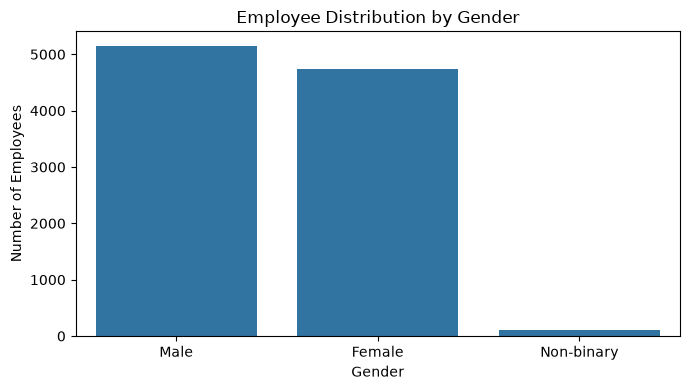

In [11]:

# Employee gender distribution

gender_summary = (
    employees["Gender"]
    .value_counts()
    .reset_index()
)

gender_summary.columns = [
    "Gender",
    "Employee_Count"
]

gender_summary["Percentage"] = (
    gender_summary["Employee_Count"]
    / len(employees) * 100
).round(2)

display(gender_summary)

# Visualization
plt.figure(figsize=(7, 4))

sns.barplot(
    data=gender_summary,
    x="Gender",
    y="Employee_Count"
)

plt.title("Employee Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


**Business Insight — Workforce Gender Distribution**

- Male employees represent 51.50% of the workforce, followed by female employees at 47.38% and non-binary employees at 1.12%.
- Male and female representation is relatively balanced, with a difference of 4.12 percentage points.
- This distribution provides a baseline for evaluating gender-based compensation differences in subsequent analyses.

Employee Age Summary:


count   10,000.00
mean        34.06
std          6.87
min         21.00
25%         29.00
50%         34.00
75%         39.00
max         60.00
Name: Age, dtype: float64

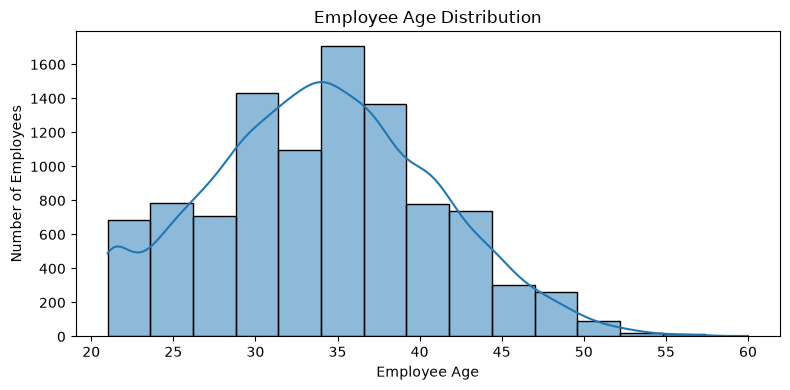

In [12]:

# Employee age distribution

print("Employee Age Summary:")
display(employees["Age"].describe().round(2))

# Age distribution visualization
plt.figure(figsize=(8, 4))

sns.histplot(
    data=employees,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Employee Age Distribution")
plt.xlabel("Employee Age")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


**Business Insight — Employee Age Distribution**

- The average employee age is 34.06 years, with a median of 34 years.
- Half of the workforce falls between 29 and 39 years of age.
- The workforce is concentrated around the early-to-mid 30s, with relatively fewer employees in older age groups.
- Age distribution provides useful context for subsequent experience, compensation, and career progression analyses.

,Location,Employee_Count,Percentage
0,Bengaluru,2794,27.94
1,Hyderabad,1660,16.60
2,Pune,1542,15.42
3,Chennai,1479,14.79
4,Mumbai,1311,13.11
5,Gurugram,1214,12.14


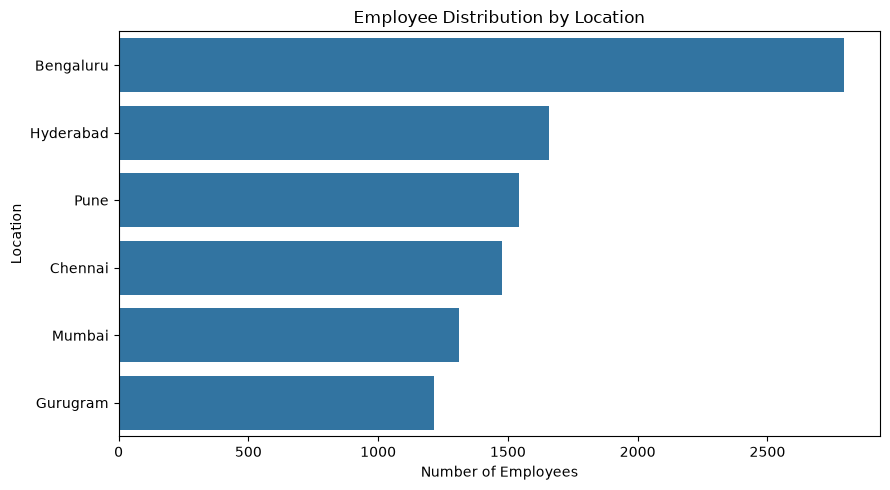

In [13]:

# Employee distribution by location

location_summary = (
    employees["Location"]
    .value_counts()
    .reset_index()
)

location_summary.columns = [
    "Location",
    "Employee_Count"
]

location_summary["Percentage"] = (
    location_summary["Employee_Count"]
    / len(employees) * 100
).round(2)

display(location_summary)

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=location_summary,
    x="Employee_Count",
    y="Location"
)

plt.title("Employee Distribution by Location")
plt.xlabel("Number of Employees")
plt.ylabel("Location")

plt.tight_layout()
plt.show()


**Business Insight — Workforce Location Distribution**

- Bengaluru has the largest workforce share at 27.94%, followed by Hyderabad at 16.60%.
- Bengaluru, Hyderabad, and Pune collectively account for 59.96% of employees.
- Workforce concentration varies across locations, making location an important factor to consider in subsequent compensation and pay equity analysis.

,Education_Level,Employee_Count,Percentage
0,Bachelor's,5162,51.62
1,Master's,2450,24.50
2,MBA,1469,14.69
3,Diploma,679,6.79
4,Doctorate,195,1.95
5,Unknown,45,0.45


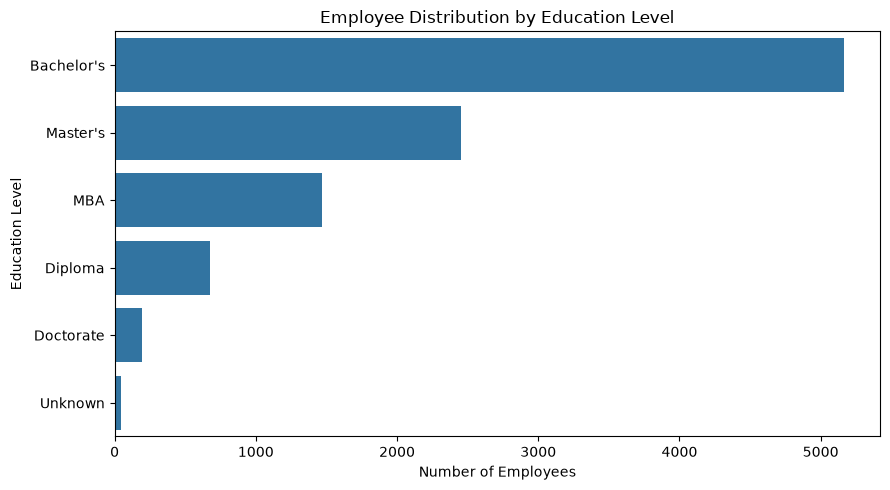

In [14]:

# Employee distribution by education level

education_summary = (
    employees["Education_Level"]
    .value_counts()
    .reset_index()
)

education_summary.columns = [
    "Education_Level",
    "Employee_Count"
]

education_summary["Percentage"] = (
    education_summary["Employee_Count"]
    / len(employees) * 100
).round(2)

display(education_summary)

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=education_summary,
    x="Employee_Count",
    y="Education_Level"
)

plt.title("Employee Distribution by Education Level")
plt.xlabel("Number of Employees")
plt.ylabel("Education Level")

plt.tight_layout()
plt.show()


**Business Insight — Employee Education Distribution**

- Bachelor's degree holders represent the largest workforce segment at 51.62%.
- Master's and MBA holders collectively account for 39.19% of employees.
- Only 0.45% of employees have unknown educational qualifications.
- Educational qualifications provide useful context for subsequent compensation comparisons, although differences in pay must also be evaluated alongside job level, experience, and location.

,Employment_Type,Employee_Count,Percentage
0,Full-time,9579,95.79
1,Part-time,421,4.21


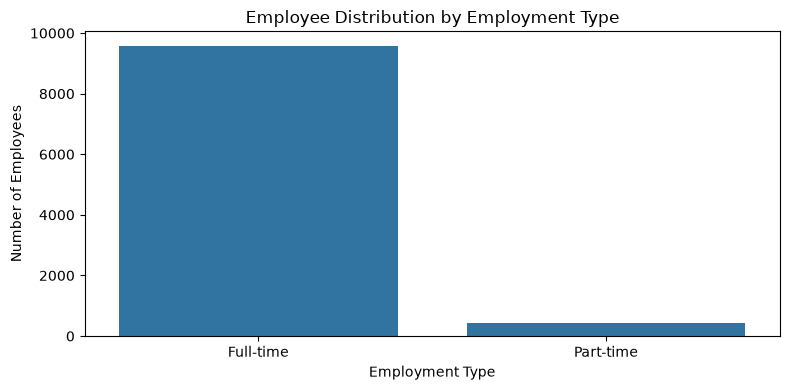

In [15]:

# Employee distribution by employment type

employment_summary = (
    employees["Employment_Type"]
    .value_counts()
    .reset_index()
)

employment_summary.columns = [
    "Employment_Type",
    "Employee_Count"
]

employment_summary["Percentage"] = (
    employment_summary["Employee_Count"]
    / len(employees) * 100
).round(2)

display(employment_summary)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=employment_summary,
    x="Employment_Type",
    y="Employee_Count"
)

plt.title("Employee Distribution by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


,Employment_Status,Employee_Count,Percentage
0,Active,9467,94.67
1,Exited,533,5.33


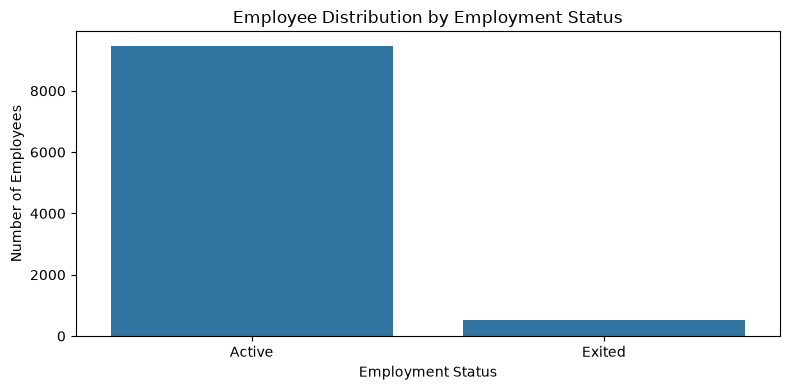

In [16]:

# Employee distribution by employment status

status_summary = (
    employees["Employment_Status"]
    .value_counts()
    .reset_index()
)

status_summary.columns = [
    "Employment_Status",
    "Employee_Count"
]

status_summary["Percentage"] = (
    status_summary["Employee_Count"]
    / len(employees) * 100
).round(2)

display(status_summary)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=status_summary,
    x="Employment_Status",
    y="Employee_Count"
)

plt.title("Employee Distribution by Employment Status")
plt.xlabel("Employment Status")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


Merged Records: 10000
Missing Departments: 0


,Department,Employee_Count,Percentage
0,Leadership,1405,14.05
1,Technology,1268,12.68
2,Product,945,9.45
3,Finance,770,7.70
4,Analytics,766,7.66
5,Supply Chain,735,7.35
6,Sales,721,7.21
7,Legal & Compliance,714,7.14
8,Marketing,697,6.97
9,Human Resources,668,6.68


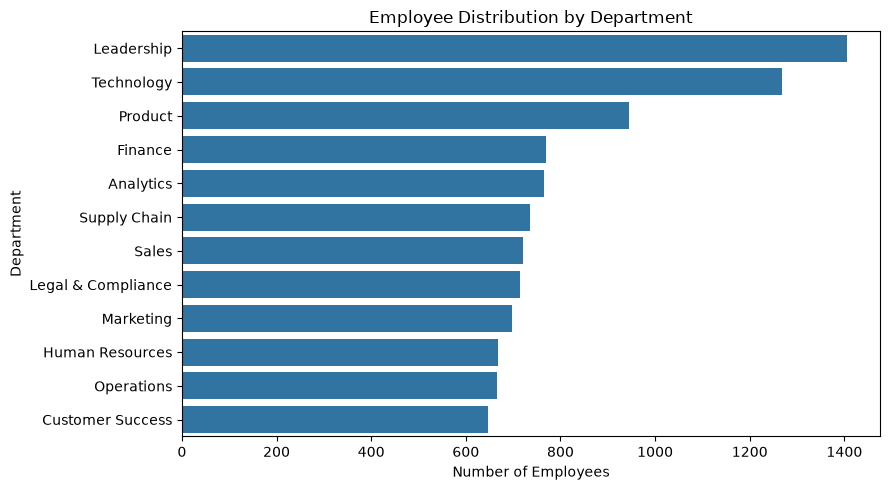

In [17]:

# Merge employee and job information

employee_jobs = employees.merge(
    jobs[["Job_ID", "Department"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Validate the merge
print("Merged Records:", len(employee_jobs))
print("Missing Departments:",
      employee_jobs["Department"].isna().sum())

# Department-wise employee distribution
department_summary = (
    employee_jobs["Department"]
    .value_counts()
    .reset_index()
)

department_summary.columns = [
    "Department",
    "Employee_Count"
]

department_summary["Percentage"] = (
    department_summary["Employee_Count"]
    / len(employee_jobs) * 100
).round(2)

display(department_summary)

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=department_summary,
    x="Employee_Count",
    y="Department"
)

plt.title("Employee Distribution by Department")
plt.xlabel("Number of Employees")
plt.ylabel("Department")

plt.tight_layout()
plt.show()


**Business Insight — Department Distribution**

- Leadership and Technology have the highest employee representation, accounting for 26.73% of the workforce.
- Customer Success has the smallest workforce share at 6.46%.
- Department-level workforce differences provide important context for evaluating salary expenses, compensation patterns, and pay equity across business functions.

Merged Records: 10000
Missing Job Levels: 0


,Job_Level,Employee_Count,Percentage
5,1,607,6.07
1,2,2192,21.92
2,3,2066,20.66
0,4,2725,27.25
4,5,1005,10.05
3,6,1405,14.05


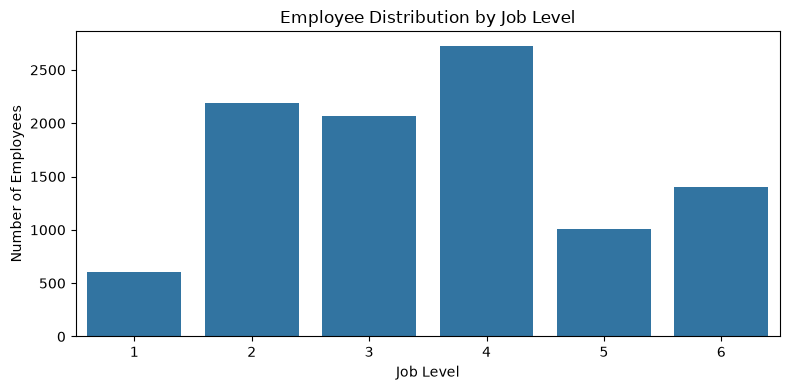

In [18]:

# Merge employee data with job levels

employee_levels = employees.merge(
    jobs[["Job_ID", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Validate merge
print("Merged Records:", len(employee_levels))
print("Missing Job Levels:",
      employee_levels["Job_Level"].isna().sum())

# Job level distribution
level_summary = (
    employee_levels["Job_Level"]
    .value_counts()
    .reset_index()
)

level_summary.columns = [
    "Job_Level",
    "Employee_Count"
]

level_summary["Percentage"] = (
    level_summary["Employee_Count"]
    / len(employee_levels) * 100
).round(2)

level_summary = level_summary.sort_values("Job_Level")

display(level_summary)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=level_summary,
    x="Job_Level",
    y="Employee_Count"
)

plt.title("Employee Distribution by Job Level")
plt.xlabel("Job Level")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


**Business Insight — Job Level Distribution**

- Job Level 4 has the highest workforce representation at 27.25%.
- Job Levels 2–4 account for 69.83% of employees.
- Job Level 1 has the lowest representation at 6.07%.
- Job-level distribution is important when evaluating compensation differences, as comparisons should account for differences in job seniority.

Experience Summary:


count   9,975.00
mean       11.16
std         6.84
min         0.00
25%         6.00
50%        11.00
75%        16.00
max        39.00
Name: Years_Experience, dtype: float64

Missing Experience Values: 25


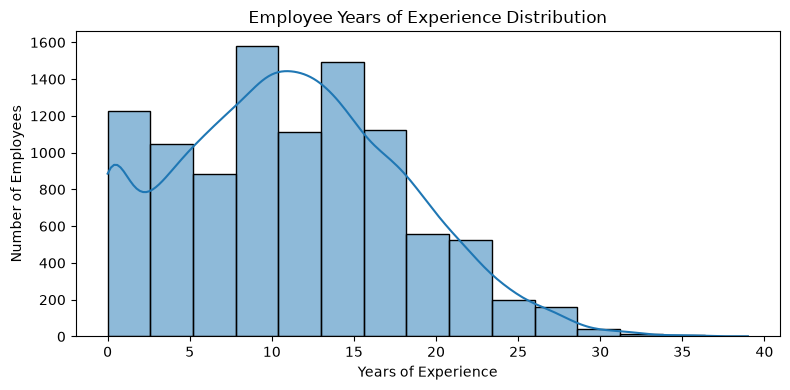

In [19]:

# Employee years of experience summary

print("Experience Summary:")
display(employees["Years_Experience"].describe().round(2))

print("Missing Experience Values:",
      employees["Years_Experience"].isna().sum())

# Experience distribution visualization
plt.figure(figsize=(8, 4))

sns.histplot(
    data=employees,
    x="Years_Experience",
    bins=15,
    kde=True
)

plt.title("Employee Years of Experience Distribution")
plt.xlabel("Years of Experience")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


**Business Insight — Employee Experience Distribution**

- Employees have an average of 11.16 years of professional experience, with a median of 11 years.
- Half of employees with recorded experience have between 6 and 16 years of experience.
- The distribution is concentrated around mid-career experience levels, with relatively fewer employees having more than 25 years of experience.
- Professional experience should be considered alongside job level, department, and location when evaluating compensation differences.

Employee Tenure Summary:


count   10,000.00
mean         6.41
std          5.09
min          0.00
25%          2.10
50%          5.20
75%          9.60
max         21.00
Name: Tenure_Years_2026, dtype: float64

Missing Tenure Values: 0


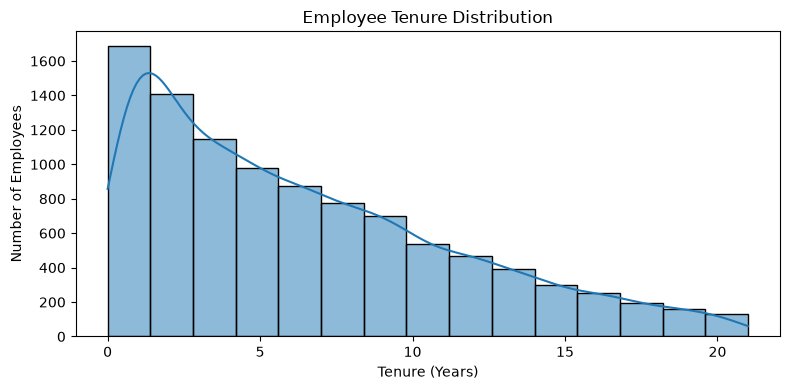

In [20]:

# Employee tenure summary

print("Employee Tenure Summary:")

display(
    employees["Tenure_Years_2026"]
    .describe()
    .round(2)
)

print("Missing Tenure Values:",
      employees["Tenure_Years_2026"].isna().sum())

# Tenure distribution visualization
plt.figure(figsize=(8, 4))

sns.histplot(
    data=employees,
    x="Tenure_Years_2026",
    bins=15,
    kde=True
)

plt.title("Employee Tenure Distribution")
plt.xlabel("Tenure (Years)")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


**Business Insight — Employee Tenure Distribution**

- Employees have an average organizational tenure of 6.41 years, with a median of 5.20 years.
- Half of the workforce has tenure between 2.10 and 9.60 years.
- The distribution is right-skewed, indicating a greater concentration of employees with shorter tenure.
- Organizational tenure provides important context for analyzing salary progression, promotions, and compensation differences.

,Compensation_Year,Employee_Count
0,2024,7539
1,2025,8766
2,2026,10000


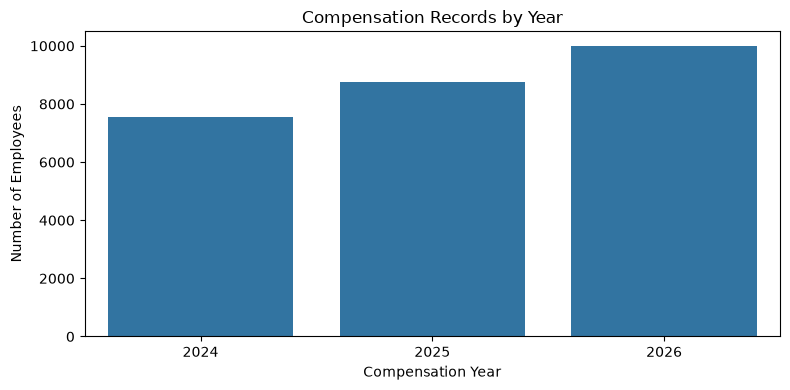

In [21]:

# Compensation records by year

compensation_year_summary = (
    compensation["Compensation_Year"]
    .value_counts()
    .sort_index()
    .reset_index()
)

compensation_year_summary.columns = [
    "Compensation_Year",
    "Employee_Count"
]

display(compensation_year_summary)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=compensation_year_summary,
    x="Compensation_Year",
    y="Employee_Count"
)

plt.title("Compensation Records by Year")
plt.xlabel("Compensation Year")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


,Compensation_Year,Employee_Count,Avg_Base_Salary,Avg_Total_Compensation
0,2024,7539,"2,134,602.86","2,466,420.82"
1,2025,8766,"2,092,426.40","2,417,610.25"
2,2026,10000,"2,047,550.81","2,363,933.67"


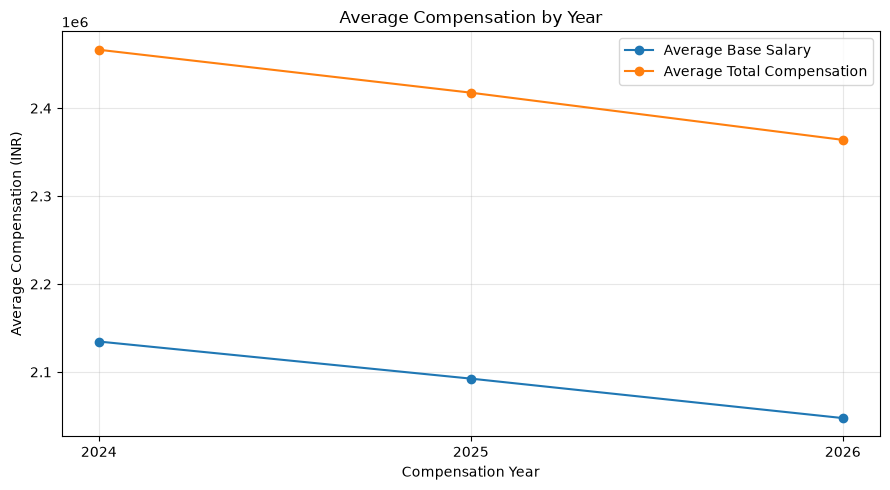

In [22]:

# Average compensation by year

yearly_compensation = (
    compensation.groupby("Compensation_Year")
    .agg(
        Employee_Count=("Employee_ID", "nunique"),
        Avg_Base_Salary=("Base_Salary", "mean"),
        Avg_Total_Compensation=("Total_Compensation", "mean")
    )
    .reset_index()
)

display(yearly_compensation.round(2))

# Visualization
plt.figure(figsize=(9, 5))

plt.plot(
    yearly_compensation["Compensation_Year"],
    yearly_compensation["Avg_Base_Salary"],
    marker="o",
    label="Average Base Salary"
)

plt.plot(
    yearly_compensation["Compensation_Year"],
    yearly_compensation["Avg_Total_Compensation"],
    marker="o",
    label="Average Total Compensation"
)

plt.title("Average Compensation by Year")
plt.xlabel("Compensation Year")
plt.ylabel("Average Compensation (INR)")
plt.xticks(yearly_compensation["Compensation_Year"])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Business Insight — Average Compensation Trends**

- Average base salary decreased from ₹21.35 lakh in 2024 to ₹20.48 lakh in 2026.
- Average total compensation declined from ₹24.66 lakh to ₹23.64 lakh over the same period.
- The number of employees with compensation records increased from 7,539 to 10,000.
- These trends may reflect changes in workforce composition, including newly hired employees and differences in job levels. Employee-level salary growth analysis is required to distinguish these effects from individual pay changes.

2026 Base Salary Summary:


count      10,000.00
mean    2,047,550.81
std     1,611,050.53
min       306,684.12
25%       809,179.72
50%     1,562,414.91
75%     2,256,147.43
max     6,715,741.84
Name: Base_Salary, dtype: float64

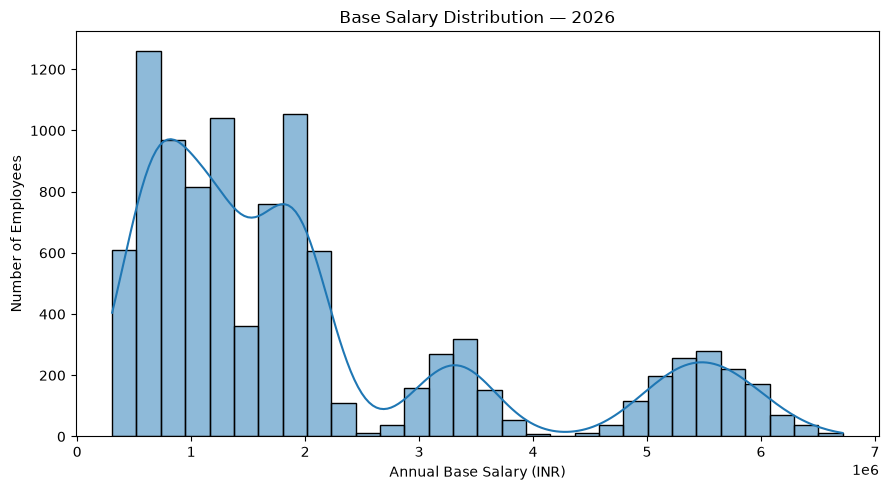

In [23]:

# Filter compensation data for 2026

compensation_2026 = compensation[
    compensation["Compensation_Year"] == 2026
].copy()

# Base salary summary statistics
print("2026 Base Salary Summary:")

display(
    compensation_2026["Base_Salary"]
    .describe()
    .round(2)
)

# Base salary distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=compensation_2026,
    x="Base_Salary",
    bins=30,
    kde=True
)

plt.title("Base Salary Distribution — 2026")
plt.xlabel("Annual Base Salary (INR)")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


**Business Insight — Base Salary Distribution (2026)**

- The average annual base salary is ₹20.48 lakh, compared with a median of ₹15.62 lakh.
- The distribution is right-skewed, with several distinct salary concentrations.
- The middle 50% of employees earn between approximately ₹8.09 lakh and ₹22.56 lakh annually.
- The wide salary variation highlights the importance of examining compensation by job level, department, experience, and location before assessing pay equity.

2026 Total Compensation Summary:


count      10,000.00
mean    2,363,933.67
std     1,900,713.78
min       332,786.56
25%       914,591.22
50%     1,773,733.02
75%     2,620,888.32
max     8,143,188.93
Name: Total_Compensation, dtype: float64

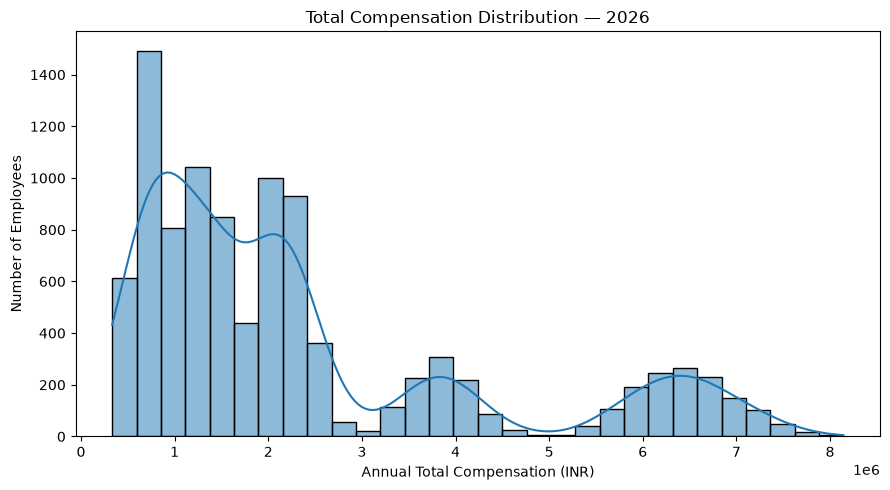

In [24]:

# Total compensation summary statistics

print("2026 Total Compensation Summary:")

display(
    compensation_2026["Total_Compensation"]
    .describe()
    .round(2)
)

# Total compensation distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=compensation_2026,
    x="Total_Compensation",
    bins=30,
    kde=True
)

plt.title("Total Compensation Distribution — 2026")
plt.xlabel("Annual Total Compensation (INR)")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


**Business Insight — Total Compensation Distribution (2026)**

- Average annual total compensation is ₹23.64 lakh, compared with a median of ₹17.74 lakh.
- Total compensation is right-skewed, with multiple distinct compensation concentrations.
- The middle 50% of employees receive between ₹9.15 lakh and ₹26.21 lakh annually.
- Differences in total compensation should be investigated across job levels, departments, experience, and other relevant factors before drawing pay equity conclusions.

,Component,Total_Amount,Percentage
0,Base_Salary,"20,475,508,071.21",86.62
1,Annual_Bonus,"2,444,430,147.65",10.34
2,Allowances,"719,398,457.82",3.04


Total Compensation Expense: 23639336677.5
Total Components: 23639336676.68


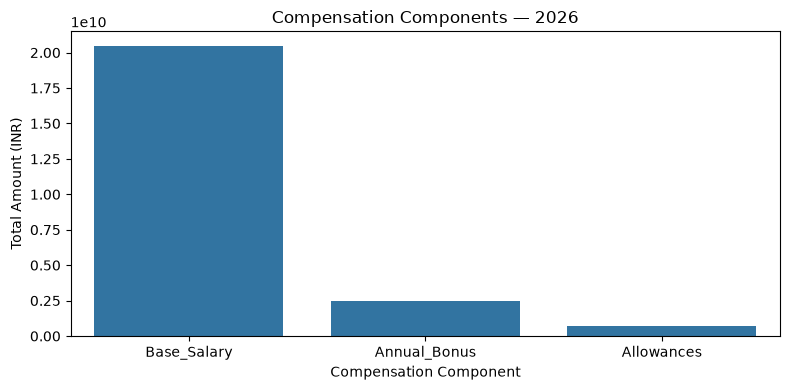

In [25]:

# Compensation component analysis for 2026

components = [
    "Base_Salary",
    "Annual_Bonus",
    "Allowances"
]

component_summary = (
    compensation_2026[components]
    .sum()
    .reset_index()
)

component_summary.columns = [
    "Component",
    "Total_Amount"
]

component_summary["Percentage"] = (
    component_summary["Total_Amount"]
    / component_summary["Total_Amount"].sum() * 100
).round(2)

display(component_summary.round(2))

# Validate component reconciliation
print(
    "Total Compensation Expense:",
    round(compensation_2026["Total_Compensation"].sum(), 2)
)

print(
    "Total Components:",
    round(component_summary["Total_Amount"].sum(), 2)
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=component_summary,
    x="Component",
    y="Total_Amount"
)

plt.title("Compensation Components — 2026")
plt.xlabel("Compensation Component")
plt.ylabel("Total Amount (INR)")

plt.tight_layout()
plt.show()


**Business Insight — Compensation Components (2026)**

- Base salary accounts for 86.62% of total compensation expenditure, making it the largest compensation component.
- Annual bonuses contribute 10.34%, while allowances account for 3.04%.
- Bonuses and allowances collectively represent 13.38% of total compensation expenditure.
- The organization relies primarily on base salary, making fixed pay an important focus for subsequent compensation and pay equity analysis.

Merged Records: 10000
Missing Job Levels: 0


,Job_Level,Employee_Count,Avg_Base_Salary
0,1,607,"398,591.08"
1,2,2192,"720,330.36"
2,3,2066,"1,192,708.08"
3,4,2725,"1,882,875.17"
4,5,1005,"3,308,317.59"
5,6,1405,"5,505,174.55"


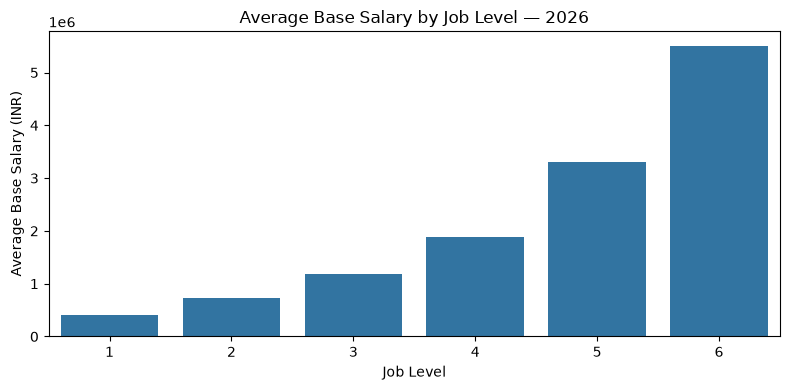

In [26]:

# Merge 2026 compensation with employee job information

salary_by_level_data = compensation_2026.merge(
    employees[["Employee_ID", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

salary_by_level_data = salary_by_level_data.merge(
    jobs[["Job_ID", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Validate merged data
print("Merged Records:", len(salary_by_level_data))
print("Missing Job Levels:",
      salary_by_level_data["Job_Level"].isna().sum())

# Average base salary by job level
salary_level_summary = (
    salary_by_level_data.groupby("Job_Level")
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Base_Salary=("Base_Salary", "mean")
    )
    .reset_index()
    .sort_values("Job_Level")
)

display(salary_level_summary.round(2))

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=salary_level_summary,
    x="Job_Level",
    y="Avg_Base_Salary"
)

plt.title("Average Base Salary by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Average Base Salary (INR)")

plt.tight_layout()
plt.show()


**Business Insight — Average Base Salary by Job Level (2026)**

- Average base salary increases consistently across job levels, from ₹3.99 lakh at Level 1 to ₹55.05 lakh at Level 6.
- Job Level 6 has the highest average base salary, while Level 1 has the lowest.
- The substantial differences between job levels indicate that job seniority is an important factor in compensation structure.
- Pay equity comparisons should account for job levels rather than relying only on overall salary averages.

Merged Records: 10000
Missing Departments: 0


,Department,Employee_Count,Avg_Total_Compensation
4,Leadership,1405,"6,449,037.83"
8,Product,945,"2,784,716.48"
11,Technology,1268,"2,495,273.49"
5,Legal & Compliance,714,"1,561,177.07"
0,Analytics,766,"1,479,654.82"
2,Finance,770,"1,424,237.44"
9,Sales,721,"1,405,635.42"
6,Marketing,697,"1,391,037.81"
10,Supply Chain,735,"1,381,933.16"
7,Operations,665,"1,267,624.39"


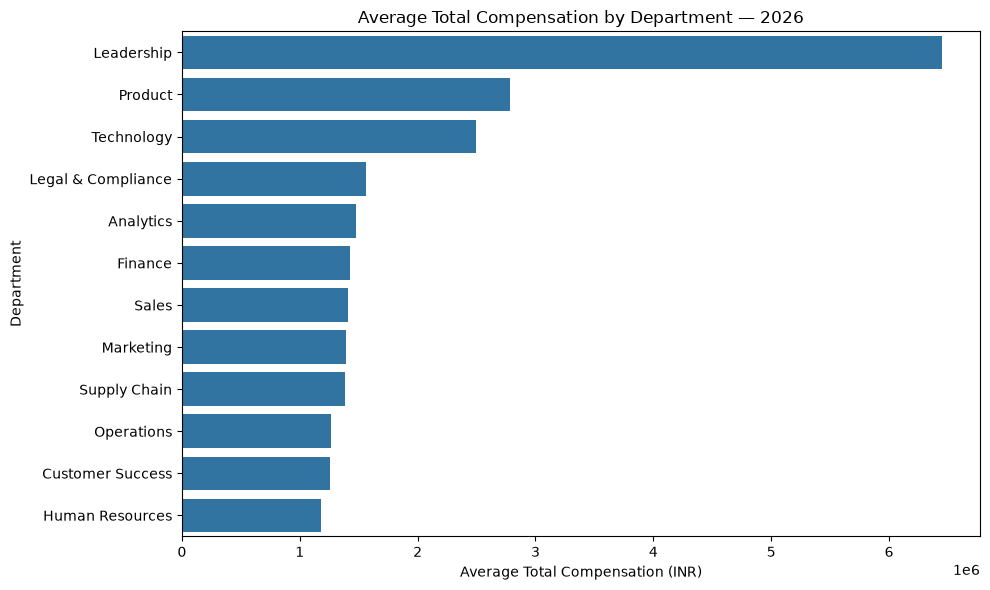

In [27]:

# Merge 2026 compensation with employee and department data

department_compensation = compensation_2026.merge(
    employees[["Employee_ID", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

department_compensation = department_compensation.merge(
    jobs[["Job_ID", "Department"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Validate merge
print("Merged Records:", len(department_compensation))
print("Missing Departments:",
      department_compensation["Department"].isna().sum())

# Average total compensation by department
department_salary_summary = (
    department_compensation.groupby("Department")
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Total_Compensation=("Total_Compensation", "mean")
    )
    .reset_index()
    .sort_values(
        "Avg_Total_Compensation",
        ascending=False
    )
)

display(department_salary_summary.round(2))

# Visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_salary_summary,
    x="Avg_Total_Compensation",
    y="Department"
)

plt.title("Average Total Compensation by Department — 2026")
plt.xlabel("Average Total Compensation (INR)")
plt.ylabel("Department")

plt.tight_layout()
plt.show()


**Business Insight — Department-Level Compensation (2026)**

- Leadership has the highest average total compensation at ₹64.49 lakh, followed by Product at ₹27.85 lakh and Technology at ₹24.95 lakh.
- Human Resources has the lowest average total compensation at ₹11.79 lakh.
- Compensation varies substantially across departments, potentially reflecting differences in job seniority, responsibilities, and workforce composition.
- Department-level salary differences should be evaluated alongside job levels and other relevant factors before drawing conclusions about pay equity.

Merged Records: 10000
Missing Locations: 0


,Location,Employee_Count,Avg_Base_Salary
4,Mumbai,1311,"2,158,636.34"
2,Gurugram,1214,"2,147,174.35"
0,Bengaluru,2794,"2,076,525.70"
3,Hyderabad,1660,"1,999,458.22"
5,Pune,1542,"1,982,139.19"
1,Chennai,1479,"1,934,749.21"


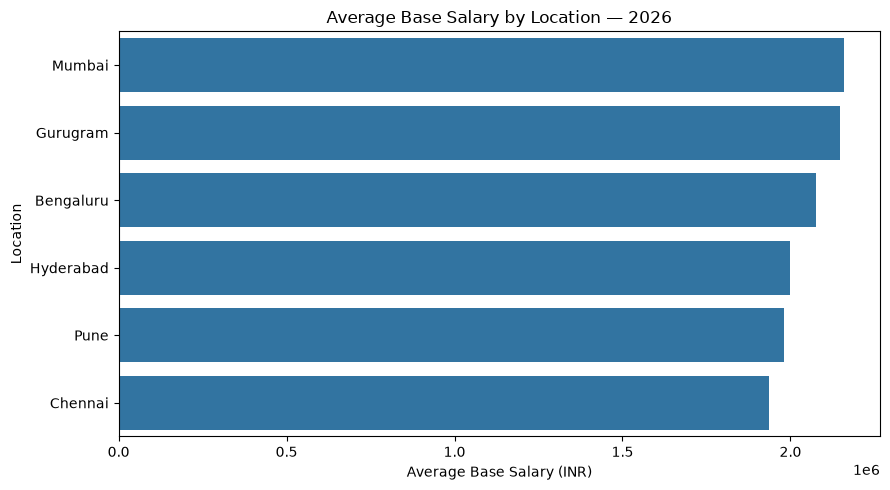

In [28]:

# Merge 2026 compensation with employee location

location_compensation = compensation_2026.merge(
    employees[["Employee_ID", "Location"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Merged Records:", len(location_compensation))
print("Missing Locations:",
      location_compensation["Location"].isna().sum())

# Average base salary by location
location_salary_summary = (
    location_compensation.groupby("Location")
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Base_Salary=("Base_Salary", "mean")
    )
    .reset_index()
    .sort_values(
        "Avg_Base_Salary",
        ascending=False
    )
)

display(location_salary_summary.round(2))

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=location_salary_summary,
    x="Avg_Base_Salary",
    y="Location"
)

plt.title("Average Base Salary by Location — 2026")
plt.xlabel("Average Base Salary (INR)")
plt.ylabel("Location")

plt.tight_layout()
plt.show()


**Business Insight — Location-Based Salary Distribution (2026)**

- Mumbai has the highest average annual base salary at ₹21.59 lakh, followed by Gurugram at ₹21.47 lakh.
- Chennai has the lowest average base salary at ₹19.35 lakh.
- The difference between the highest- and lowest-paying locations is approximately ₹2.24 lakh annually.
- These geographical salary differences may reflect variations in job levels, employee experience, and workforce composition. Further analysis is required before identifying potential location-based pay inequities.

Merged Records: 10000
Missing Gender Values: 0


,Gender,Employee_Count,Avg_Base_Salary,Median_Base_Salary
1,Male,5150,"2,060,003.00","1,568,888.16"
0,Female,4738,"2,035,345.26","1,558,756.33"
2,Non-binary,112,"1,991,310.25","1,414,448.90"


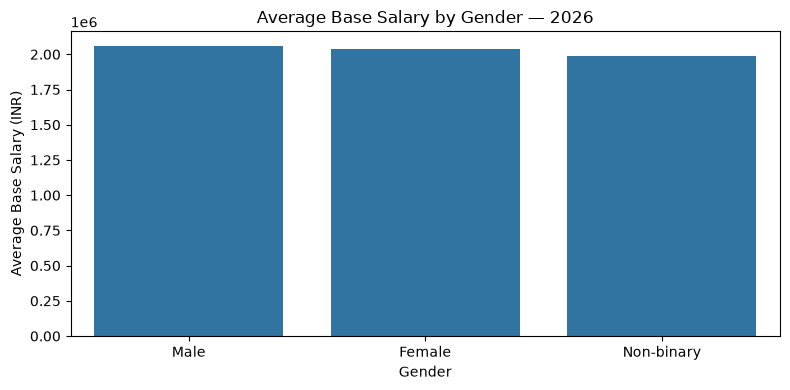

In [29]:

# Merge 2026 compensation with employee gender

gender_compensation = compensation_2026.merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Merged Records:", len(gender_compensation))
print("Missing Gender Values:",
      gender_compensation["Gender"].isna().sum())

# Average base salary by gender
gender_salary_summary = (
    gender_compensation.groupby("Gender")
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Base_Salary=("Base_Salary", "mean"),
        Median_Base_Salary=("Base_Salary", "median")
    )
    .reset_index()
    .sort_values("Avg_Base_Salary", ascending=False)
)

display(gender_salary_summary.round(2))

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=gender_salary_summary,
    x="Gender",
    y="Avg_Base_Salary"
)

plt.title("Average Base Salary by Gender — 2026")
plt.xlabel("Gender")
plt.ylabel("Average Base Salary (INR)")

plt.tight_layout()
plt.show()


**Business Insight — Gender-Based Base Salary Comparison (2026)**

- Male employees have an average base salary of ₹20.60 lakh, compared with ₹20.35 lakh for female employees and ₹19.91 lakh for non-binary employees.
- The unadjusted female-to-male average salary gap is approximately 1.20%.
- Overall salary differences are relatively small but may be influenced by job level, department, experience, and workforce composition.
- Further comparisons within equivalent job levels are necessary to assess potential pay equity concerns.

Merged Records: 10000
Missing Values: 0


,Job_Level,Gender,Employee_Count,Avg_Base_Salary
0,1,Female,277,"392,017.69"
1,1,Male,322,"404,245.90"
2,1,Non-binary,8,"398,588.27"
3,2,Female,1026,"715,137.35"
4,2,Male,1144,"725,378.37"
5,2,Non-binary,22,"700,016.95"
6,3,Female,992,"1,175,199.19"
7,3,Male,1046,"1,209,007.63"
8,3,Non-binary,28,"1,204,118.13"
9,4,Female,1294,"1,864,280.02"


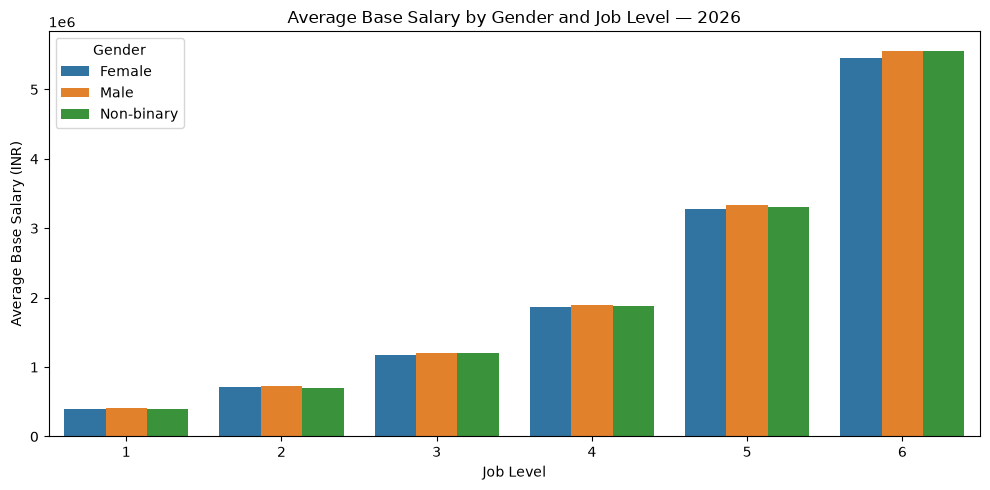

In [30]:

# Combine 2026 compensation with gender and job level

gender_level_data = compensation_2026.merge(
    employees[["Employee_ID", "Gender", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

gender_level_data = gender_level_data.merge(
    jobs[["Job_ID", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Validate merged data
print("Merged Records:", len(gender_level_data))

print("Missing Values:",
      gender_level_data[["Gender", "Job_Level"]]
      .isna().sum().sum())

# Average base salary by gender and job level
gender_level_summary = (
    gender_level_data.groupby(
        ["Job_Level", "Gender"]
    )
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Base_Salary=("Base_Salary", "mean")
    )
    .reset_index()
)

display(gender_level_summary.round(2))

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=gender_level_summary,
    x="Job_Level",
    y="Avg_Base_Salary",
    hue="Gender"
)

plt.title("Average Base Salary by Gender and Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Average Base Salary (INR)")
plt.legend(title="Gender")

plt.tight_layout()
plt.show()


**Business Insight — Gender-Based Salary Differences Within Job Levels (2026)**

- Average base salary increases consistently with job level across all gender groups.
- Female employees have slightly lower average base salaries than male employees at every job level, with differences ranging from approximately 1.41% to 3.02%.
- The persistence of these differences within job levels warrants further investigation.
- Additional comparisons accounting for job role, department, location, and experience are necessary before drawing conclusions about pay equity.

Employees with Missing Experience: 25


,Experience_Group,Employee_Count,Avg_Base_Salary
0,0-5 Years,2276,"696,973.24"
1,6-10 Years,2466,"1,188,322.39"
2,11-15 Years,2605,"1,874,384.16"
3,16-20 Years,1681,"3,576,683.43"
4,20+ Years,947,"5,298,191.04"


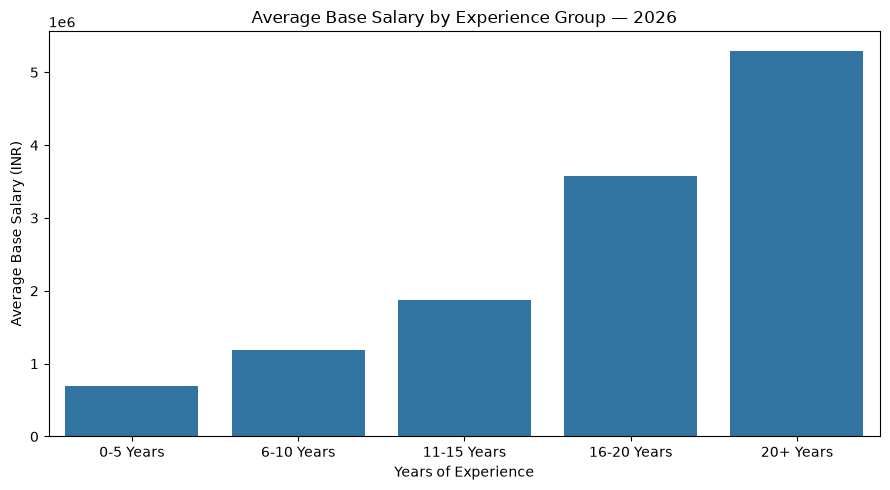

In [31]:

# Merge 2026 compensation with employee experience

experience_salary = compensation_2026.merge(
    employees[["Employee_ID", "Years_Experience"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Create experience groups
experience_salary["Experience_Group"] = pd.cut(
    experience_salary["Years_Experience"],
    bins=[-1, 5, 10, 15, 20, float("inf")],
    labels=[
        "0-5 Years",
        "6-10 Years",
        "11-15 Years",
        "16-20 Years",
        "20+ Years"
    ]
)

# Summarize average salary by experience group
experience_salary_summary = (
    experience_salary.groupby(
        "Experience_Group",
        observed=True
    )
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Base_Salary=("Base_Salary", "mean")
    )
    .reset_index()
)

print("Employees with Missing Experience:",
      experience_salary["Years_Experience"].isna().sum())

display(experience_salary_summary.round(2))

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=experience_salary_summary,
    x="Experience_Group",
    y="Avg_Base_Salary"
)

plt.title("Average Base Salary by Experience Group — 2026")
plt.xlabel("Years of Experience")
plt.ylabel("Average Base Salary (INR)")

plt.tight_layout()
plt.show()


**Business Insight — Experience-Based Salary Distribution (2026)**

- Average base salary increases steadily with professional experience, from ₹6.97 lakh for employees with 0–5 years of experience to ₹52.98 lakh for employees with more than 20 years.
- Employees with 16 or more years of experience have substantially higher average salaries than less-experienced groups.
- Professional experience is an important factor associated with compensation differences.
- Job level, department, and role should also be considered when evaluating the relationship between experience and salary.

Merged Records: 10000
Missing Education Values: 0


,Education_Level,Employee_Count,Avg_Base_Salary
2,Doctorate,195,"2,118,441.07"
1,Diploma,679,"2,071,796.20"
5,Unknown,45,"2,071,329.94"
3,MBA,1469,"2,054,325.30"
0,Bachelor's,5162,"2,044,736.05"
4,Master's,2450,"2,036,620.92"


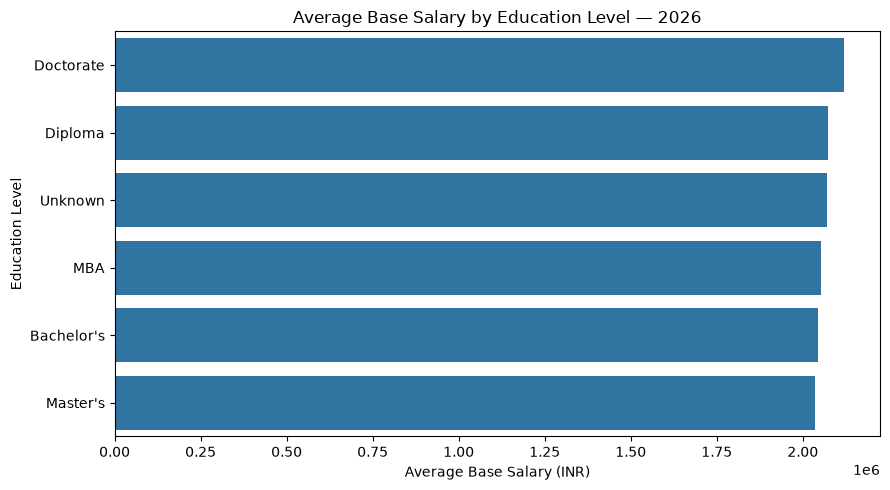

In [32]:

# Merge 2026 compensation with employee education

education_salary = compensation_2026.merge(
    employees[["Employee_ID", "Education_Level"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Merged Records:", len(education_salary))
print("Missing Education Values:",
      education_salary["Education_Level"].isna().sum())

# Average base salary by education level
education_salary_summary = (
    education_salary.groupby("Education_Level")
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Base_Salary=("Base_Salary", "mean")
    )
    .reset_index()
    .sort_values(
        "Avg_Base_Salary",
        ascending=False
    )
)

display(education_salary_summary.round(2))

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=education_salary_summary,
    x="Avg_Base_Salary",
    y="Education_Level"
)

plt.title("Average Base Salary by Education Level — 2026")
plt.xlabel("Average Base Salary (INR)")
plt.ylabel("Education Level")

plt.tight_layout()
plt.show()


**Business Insight — Education-Based Salary Distribution (2026)**

- Doctorate holders have the highest average annual base salary at ₹21.18 lakh.
- Average salaries are relatively similar across educational qualifications, ranging from ₹20.37 lakh for Master's degree holders to ₹21.18 lakh for Doctorate holders.
- Educational qualifications alone do not show a strong salary progression pattern in this dataset.
- Job level, professional experience, and job responsibilities should also be considered when examining education-related compensation differences.

Merged Records: 10000
Missing Employment Types: 0


,Employment_Type,Employee_Count,Avg_Base_Salary,Median_Base_Salary
0,Full-time,9579,"2,051,928.74","1,560,253.92"
1,Part-time,421,"1,947,939.93","1,583,521.47"


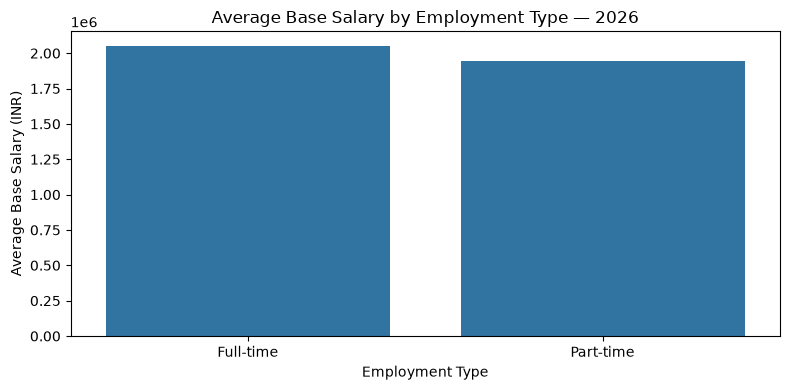

In [33]:

# Merge 2026 compensation with employment type

employment_salary = compensation_2026.merge(
    employees[["Employee_ID", "Employment_Type"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Merged Records:", len(employment_salary))
print("Missing Employment Types:",
      employment_salary["Employment_Type"].isna().sum())

# Average base salary by employment type
employment_salary_summary = (
    employment_salary.groupby("Employment_Type")
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Base_Salary=("Base_Salary", "mean"),
        Median_Base_Salary=("Base_Salary", "median")
    )
    .reset_index()
    .sort_values("Avg_Base_Salary", ascending=False)
)

display(employment_salary_summary.round(2))

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=employment_salary_summary,
    x="Employment_Type",
    y="Avg_Base_Salary"
)

plt.title("Average Base Salary by Employment Type — 2026")
plt.xlabel("Employment Type")
plt.ylabel("Average Base Salary (INR)")

plt.tight_layout()
plt.show()


Merged Records: 10000
Missing Employment Status: 0


,Employment_Status,Employee_Count,Avg_Base_Salary,Median_Base_Salary
0,Active,9467,"2,052,159.64","1,567,207.16"
1,Exited,533,"1,965,690.05","1,390,650.04"


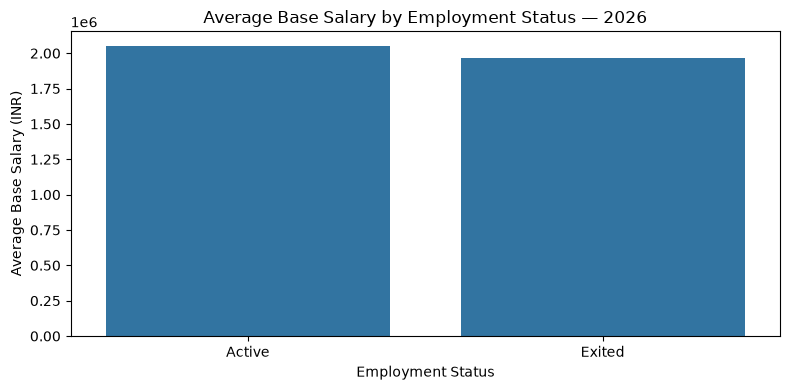

In [34]:

# Merge 2026 compensation with employment status

status_salary = compensation_2026.merge(
    employees[["Employee_ID", "Employment_Status"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Merged Records:", len(status_salary))
print("Missing Employment Status:",
      status_salary["Employment_Status"].isna().sum())

# Average base salary by employment status
status_salary_summary = (
    status_salary.groupby("Employment_Status")
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Base_Salary=("Base_Salary", "mean"),
        Median_Base_Salary=("Base_Salary", "median")
    )
    .reset_index()
    .sort_values("Avg_Base_Salary", ascending=False)
)

display(status_salary_summary.round(2))

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=status_salary_summary,
    x="Employment_Status",
    y="Avg_Base_Salary"
)

plt.title("Average Base Salary by Employment Status — 2026")
plt.xlabel("Employment Status")
plt.ylabel("Average Base Salary (INR)")

plt.tight_layout()
plt.show()


Merged Records: 10000
Missing Performance Ratings: 0


,Performance_Rating,Performance_Category,Employee_Count,Avg_Base_Salary
0,1.00,Needs Improvement,413,"2,055,989.76"
1,2.00,Developing,1115,"1,982,133.91"
2,3.00,Meets Expectations,5171,"2,004,537.35"
3,4.00,Exceeds Expectations,2700,"2,119,208.58"
4,5.00,Outstanding,601,"2,211,279.79"


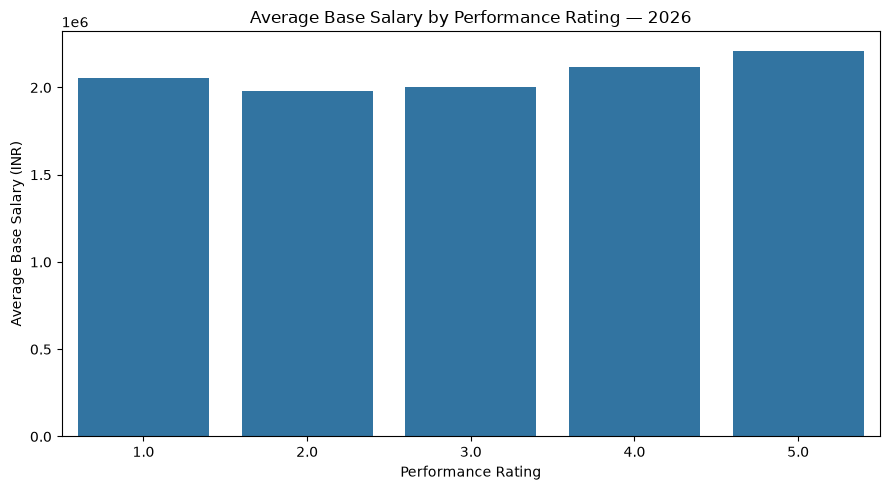

In [35]:

# Filter performance records for 2026

performance_2026 = performance[
    performance["Review_Year"] == 2026
].copy()

# Merge compensation and performance data

performance_salary = compensation_2026.merge(
    performance_2026[
        ["Employee_ID", "Performance_Rating", "Performance_Category"]
    ],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Merged Records:", len(performance_salary))

print("Missing Performance Ratings:",
      performance_salary["Performance_Rating"].isna().sum())

# Average base salary by performance rating

performance_salary_summary = (
    performance_salary.groupby(
        ["Performance_Rating", "Performance_Category"]
    )
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Base_Salary=("Base_Salary", "mean")
    )
    .reset_index()
    .sort_values("Performance_Rating")
)

display(performance_salary_summary.round(2))

# Visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=performance_salary_summary,
    x="Performance_Rating",
    y="Avg_Base_Salary"
)

plt.title("Average Base Salary by Performance Rating — 2026")
plt.xlabel("Performance Rating")
plt.ylabel("Average Base Salary (INR)")

plt.tight_layout()
plt.show()


**Business Insight — Performance Rating and Base Salary (2026)**

- Employees rated Outstanding have the highest average annual base salary at ₹22.11 lakh.
- Employees rated Exceeds Expectations earn an average of ₹21.19 lakh.
- Higher performance ratings generally correspond to higher average salaries among ratings 2–5, although the relationship is not perfectly consistent across all categories.
- Job level, experience, and role differences should be considered before attributing salary differences directly to performance.


,Performance_Rating,Performance_Category,Employee_Count,Percentage
0,1.00,Needs Improvement,413,4.13
1,2.00,Developing,1115,11.15
2,3.00,Meets Expectations,5171,51.71
3,4.00,Exceeds Expectations,2700,27.00
4,5.00,Outstanding,601,6.01


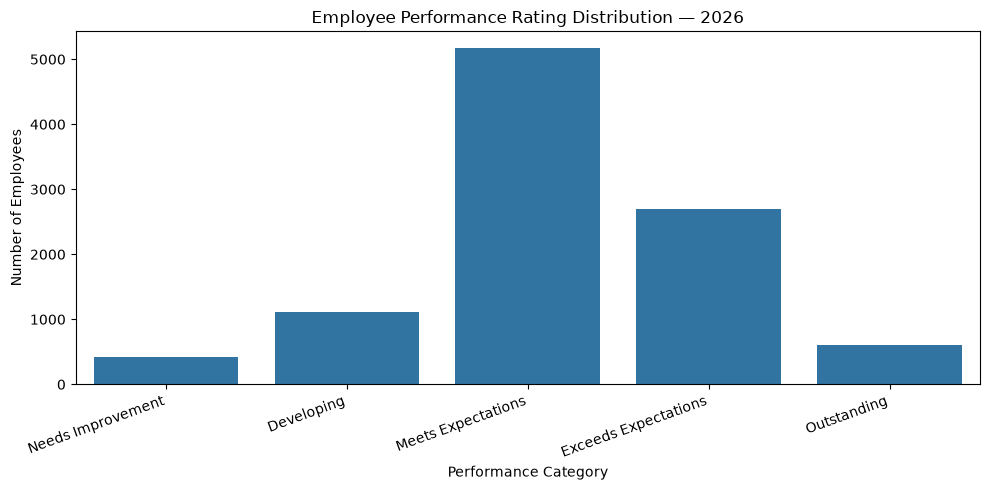

In [36]:

# Performance rating distribution for 2026

performance_distribution = (
    performance_2026.groupby(
        ["Performance_Rating", "Performance_Category"]
    )
    .agg(
        Employee_Count=("Employee_ID", "count")
    )
    .reset_index()
    .sort_values("Performance_Rating")
)

# Calculate percentages
performance_distribution["Percentage"] = (
    performance_distribution["Employee_Count"]
    / performance_distribution["Employee_Count"].sum()
    * 100
).round(2)

display(performance_distribution)

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=performance_distribution,
    x="Performance_Category",
    y="Employee_Count"
)

plt.title("Employee Performance Rating Distribution — 2026")
plt.xlabel("Performance Category")
plt.ylabel("Number of Employees")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()


**Business Insight — Performance Rating and Base Salary (2026)**

- Employees rated Outstanding have the highest average annual base salary at ₹22.11 lakh.
- Employees rated Exceeds Expectations earn an average of ₹21.19 lakh.
- Higher performance ratings generally correspond to higher average salaries among ratings 2–5, although the relationship is not perfectly consistent across all categories.
- Job level, experience, and role differences should be considered before attributing salary differences directly to performance.

,Performance_Rating,Performance_Category,Employee_Count,Percentage
0,1.00,Needs Improvement,413,4.13
1,2.00,Developing,1115,11.15
2,3.00,Meets Expectations,5171,51.71
3,4.00,Exceeds Expectations,2700,27.00
4,5.00,Outstanding,601,6.01


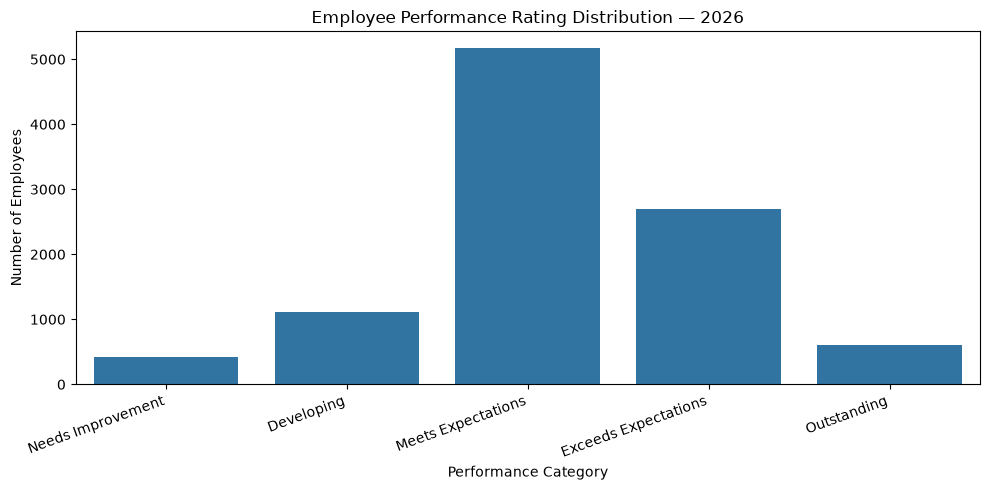

In [37]:

# Performance rating distribution for 2026

performance_distribution = (
    performance_2026.groupby(
        ["Performance_Rating", "Performance_Category"]
    )
    .agg(
        Employee_Count=("Employee_ID", "count")
    )
    .reset_index()
    .sort_values("Performance_Rating")
)

# Calculate percentages
performance_distribution["Percentage"] = (
    performance_distribution["Employee_Count"]
    / performance_distribution["Employee_Count"].sum()
    * 100
).round(2)

display(performance_distribution)

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=performance_distribution,
    x="Performance_Category",
    y="Employee_Count"
)

plt.title("Employee Performance Rating Distribution — 2026")
plt.xlabel("Performance Category")
plt.ylabel("Number of Employees")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()


**Business Insight — Employee Performance Distribution (2026)**

- Most employees (51.71%) meet performance expectations.
- High performers, comprising employees rated Exceeds Expectations or Outstanding, represent 33.01% of the workforce.
- Employees rated Developing or Needs Improvement collectively account for 15.28%.
- This performance distribution provides a baseline for examining promotion opportunities and compensation differences across performance groups.

,Promotion_Year,Promotion_Count,Unique_Employees
0,2024,738,738
1,2025,897,897
2,2026,970,970


Total Promotions: 2605


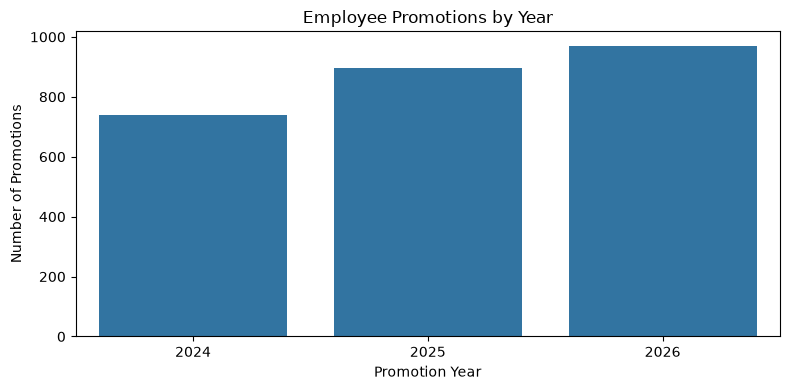

In [38]:

# Extract promotion year
promotions["Promotion_Year"] = (
    promotions["Promotion_Date"].dt.year
)

# Promotion distribution by year
promotion_year_summary = (
    promotions.groupby("Promotion_Year")
    .agg(
        Promotion_Count=("Employee_ID", "count"),
        Unique_Employees=("Employee_ID", "nunique")
    )
    .reset_index()
    .sort_values("Promotion_Year")
)

display(promotion_year_summary)

# Validate total promotions
print(
    "Total Promotions:",
    promotion_year_summary["Promotion_Count"].sum()
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=promotion_year_summary,
    x="Promotion_Year",
    y="Promotion_Count"
)

plt.title("Employee Promotions by Year")
plt.xlabel("Promotion Year")
plt.ylabel("Number of Promotions")

plt.tight_layout()
plt.show()


**Business Insight — Employee Promotion Trends (2024–2026)**

- Recorded employee promotions increased from 738 in 2024 to 970 in 2026, representing approximately 31.44% growth.
- The highest number of promotions occurred in 2026.
- Promotion counts increased consistently across the reporting period.
- Changes in the number of employees covered each year should be considered when evaluating promotion opportunities and career progression.

,Promotion_Year,Total_Employees,Unique_Employees,Promotion_Rate
0,2024,7539,738,9.79
1,2025,8766,897,10.23
2,2026,10000,970,9.70


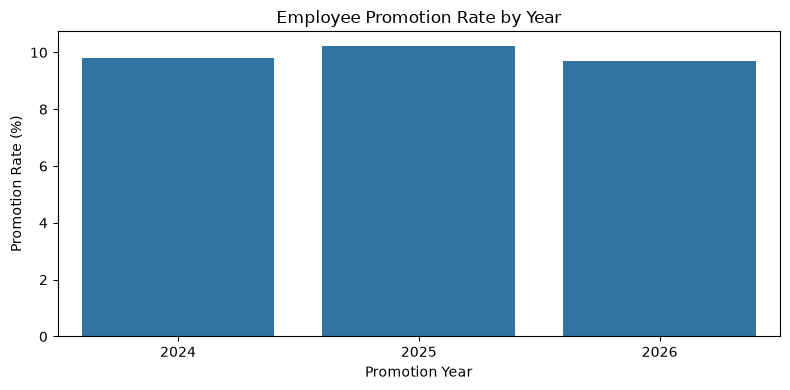

In [39]:

# Employee population by year
employee_population = (
    compensation.groupby("Compensation_Year")
    .agg(
        Total_Employees=("Employee_ID", "nunique")
    )
    .reset_index()
)

# Merge with yearly promotion summary
promotion_rate_summary = promotion_year_summary.merge(
    employee_population,
    left_on="Promotion_Year",
    right_on="Compensation_Year",
    how="left",
    validate="one_to_one"
)

# Calculate promotion rate
promotion_rate_summary["Promotion_Rate"] = (
    promotion_rate_summary["Unique_Employees"]
    / promotion_rate_summary["Total_Employees"]
    * 100
).round(2)

# Select relevant columns
promotion_rate_summary = promotion_rate_summary[
    [
        "Promotion_Year",
        "Total_Employees",
        "Unique_Employees",
        "Promotion_Rate"
    ]
]

display(promotion_rate_summary)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=promotion_rate_summary,
    x="Promotion_Year",
    y="Promotion_Rate"
)

plt.title("Employee Promotion Rate by Year")
plt.xlabel("Promotion Year")
plt.ylabel("Promotion Rate (%)")

plt.tight_layout()
plt.show()


**Business Insight — Employee Promotion Rates (2024–2026)**

- Employee promotion rates remained relatively stable between 2024 and 2026, ranging from 9.70% to 10.23%.
- The highest promotion rate occurred in 2025 at 10.23%, followed by a slight decline to 9.70% in 2026.
- Although the number of promotions increased annually, promotion rates did not follow the same upward trend.
- These results provide a baseline for examining promotion differences across performance ratings, gender, and job levels.

,Performance_Rating,Performance_Category,Total_Employees,Promoted_Employees,Promotion_Rate
0,1.00,Needs Improvement,413,38,9.20
1,2.00,Developing,1115,115,10.31
2,3.00,Meets Expectations,5171,476,9.21
3,4.00,Exceeds Expectations,2700,277,10.26
4,5.00,Outstanding,601,64,10.65


Total Employees: 10000
Total Promoted Employees: 970


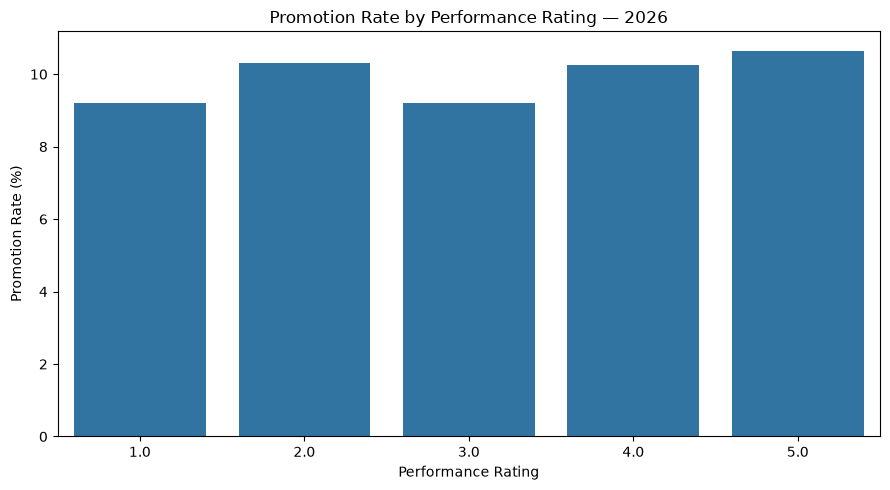

In [40]:

# Identify employees promoted in 2026

promoted_2026 = set(
    promotions.loc[
        promotions["Promotion_Year"] == 2026,
        "Employee_ID"
    ]
)

# Prepare performance data
performance_promotion = performance_2026.copy()

# Create promotion indicator
performance_promotion["Promoted"] = (
    performance_promotion["Employee_ID"]
    .isin(promoted_2026)
    .astype(int)
)

# Calculate promotion rate by performance rating
performance_promotion_summary = (
    performance_promotion.groupby(
        ["Performance_Rating", "Performance_Category"]
    )
    .agg(
        Total_Employees=("Employee_ID", "count"),
        Promoted_Employees=("Promoted", "sum")
    )
    .reset_index()
    .sort_values("Performance_Rating")
)

performance_promotion_summary["Promotion_Rate"] = (
    performance_promotion_summary["Promoted_Employees"]
    / performance_promotion_summary["Total_Employees"]
    * 100
).round(2)

display(performance_promotion_summary)

# Validation
print(
    "Total Employees:",
    performance_promotion_summary["Total_Employees"].sum()
)

print(
    "Total Promoted Employees:",
    performance_promotion_summary["Promoted_Employees"].sum()
)

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=performance_promotion_summary,
    x="Performance_Rating",
    y="Promotion_Rate"
)

plt.title("Promotion Rate by Performance Rating — 2026")
plt.xlabel("Performance Rating")
plt.ylabel("Promotion Rate (%)")

plt.tight_layout()
plt.show()


**Business Insight — Promotion Rates by Performance Rating (2026)**

- Employees rated Outstanding have the highest promotion rate at 10.65%, followed by Developing employees at 10.31%.
- Promotion rates range from 9.20% to 10.65%, indicating relatively small differences across performance categories.
- Higher performance ratings do not consistently correspond to higher promotion rates.
- Promotion decisions may involve additional factors such as job level, experience, and available opportunities. Further analysis is needed to understand these relationships.

,Gender,Total_Employees,Promoted_Employees,Promotion_Rate
0,Female,4738,461,9.73
1,Male,5150,496,9.63
2,Non-binary,112,13,11.61


Total Employees: 10000
Total Promoted Employees: 970


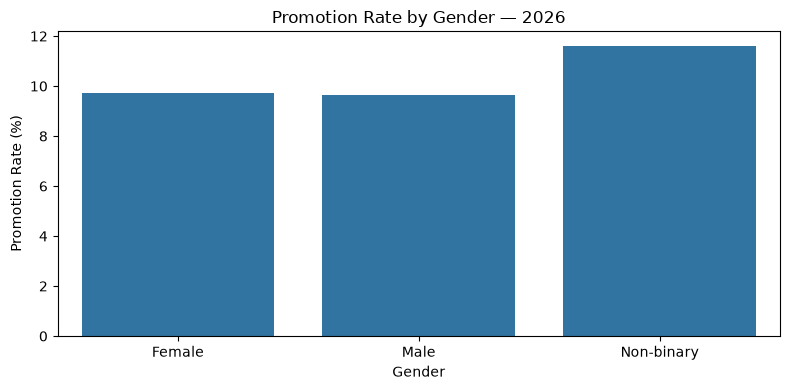

In [41]:

# Prepare employee gender data

gender_promotion = employees[
    ["Employee_ID", "Gender"]
].copy()

# Identify employees promoted in 2026
gender_promotion["Promoted"] = (
    gender_promotion["Employee_ID"]
    .isin(promoted_2026)
    .astype(int)
)

# Calculate promotion rates by gender
gender_promotion_summary = (
    gender_promotion.groupby("Gender")
    .agg(
        Total_Employees=("Employee_ID", "count"),
        Promoted_Employees=("Promoted", "sum")
    )
    .reset_index()
)

gender_promotion_summary["Promotion_Rate"] = (
    gender_promotion_summary["Promoted_Employees"]
    / gender_promotion_summary["Total_Employees"]
    * 100
).round(2)

display(gender_promotion_summary)

# Validate totals
print(
    "Total Employees:",
    gender_promotion_summary["Total_Employees"].sum()
)

print(
    "Total Promoted Employees:",
    gender_promotion_summary["Promoted_Employees"].sum()
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=gender_promotion_summary,
    x="Gender",
    y="Promotion_Rate"
)

plt.title("Promotion Rate by Gender — 2026")
plt.xlabel("Gender")
plt.ylabel("Promotion Rate (%)")

plt.tight_layout()
plt.show()


,Job_Level,Total_Employees,Promoted_Employees,Promotion_Rate
0,1,607,0,0.00
1,2,2192,197,8.99
2,3,2066,214,10.36
3,4,2725,279,10.24
4,5,1005,119,11.84
5,6,1405,161,11.46


Total Employees: 10000
Total Promoted Employees: 970
Missing Job Levels: 0


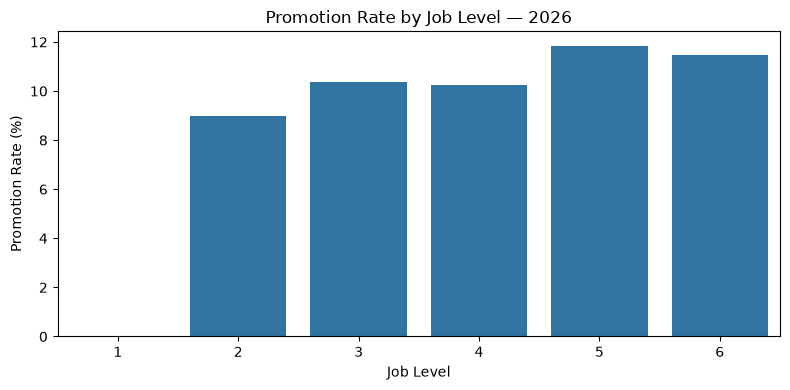

In [42]:

# Merge employees with job-level information

job_level_promotion = employees[
    ["Employee_ID", "Job_ID"]
].merge(
    jobs[["Job_ID", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Identify employees promoted in 2026
job_level_promotion["Promoted"] = (
    job_level_promotion["Employee_ID"]
    .isin(promoted_2026)
    .astype(int)
)

# Calculate promotion rates by job level
job_level_promotion_summary = (
    job_level_promotion.groupby("Job_Level")
    .agg(
        Total_Employees=("Employee_ID", "count"),
        Promoted_Employees=("Promoted", "sum")
    )
    .reset_index()
    .sort_values("Job_Level")
)

job_level_promotion_summary["Promotion_Rate"] = (
    job_level_promotion_summary["Promoted_Employees"]
    / job_level_promotion_summary["Total_Employees"]
    * 100
).round(2)

display(job_level_promotion_summary)

# Validate totals
print(
    "Total Employees:",
    job_level_promotion_summary["Total_Employees"].sum()
)

print(
    "Total Promoted Employees:",
    job_level_promotion_summary["Promoted_Employees"].sum()
)

print(
    "Missing Job Levels:",
    job_level_promotion["Job_Level"].isna().sum()
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=job_level_promotion_summary,
    x="Job_Level",
    y="Promotion_Rate"
)

plt.title("Promotion Rate by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Promotion Rate (%)")

plt.tight_layout()
plt.show()


**Business Insight — Promotion Rates by Job Level (2026)**

- Job Level 5 has the highest recorded promotion rate at 11.84%, followed by Level 6 at 11.46%.
- No promoted employees are recorded at Level 1.
- Promotion rates vary across job levels, but the recorded job level may reflect an employee's position after promotion.
- Therefore, these results describe promotions by recorded job level rather than definitive promotion opportunities at each starting level.

,Promotion_Year,Promotion_Count,Avg_Salary_Increase,Median_Salary_Increase
0,2024,738,14.62,14.64
1,2025,897,14.58,14.77
2,2026,970,14.51,14.50


Total Promotions: 2605
Overall Average Salary Increase (%): 14.57


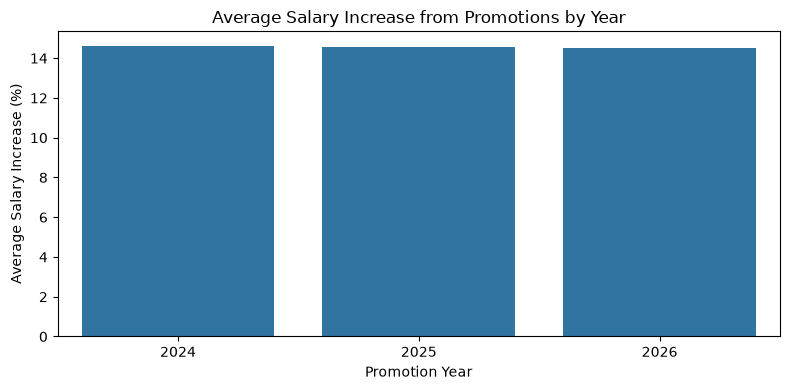

In [43]:

# Average salary increase associated with promotions by year

promotion_increase_summary = (
    promotions.groupby("Promotion_Year")
    .agg(
        Promotion_Count=("Employee_ID", "count"),
        Avg_Salary_Increase=("Salary_Increase_Pct", "mean"),
        Median_Salary_Increase=("Salary_Increase_Pct", "median")
    )
    .reset_index()
    .sort_values("Promotion_Year")
)

display(promotion_increase_summary.round(2))

# Validation
print(
    "Total Promotions:",
    promotion_increase_summary["Promotion_Count"].sum()
)

print(
    "Overall Average Salary Increase (%):",
    round(promotions["Salary_Increase_Pct"].mean(), 2)
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=promotion_increase_summary,
    x="Promotion_Year",
    y="Avg_Salary_Increase"
)

plt.title("Average Salary Increase from Promotions by Year")
plt.xlabel("Promotion Year")
plt.ylabel("Average Salary Increase (%)")

plt.tight_layout()
plt.show()


Total Promotion Records: 970
Missing Gender Values: 0


,Gender,Promotion_Count,Avg_Salary_Increase,Median_Salary_Increase
1,Male,496,14.61,14.90
0,Female,461,14.42,14.38
2,Non-binary,13,14.00,13.10


Total Promotions: 970


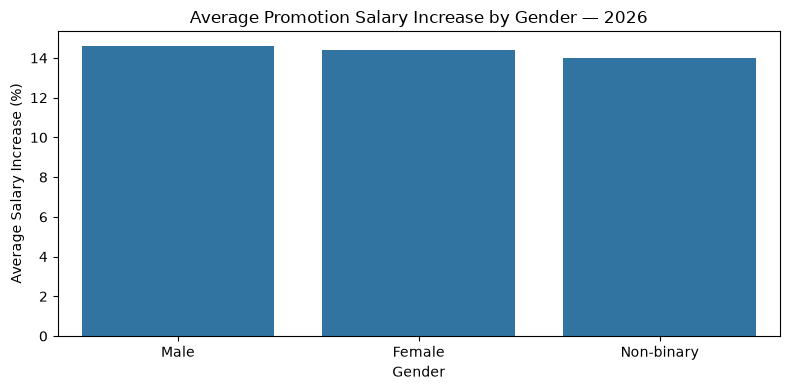

In [44]:

# Filter promotions for 2026
promotions_2026 = promotions[
    promotions["Promotion_Year"] == 2026
].copy()

# Merge promotions with employee gender
promotion_gender = promotions_2026.merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

# Validate merge
print("Total Promotion Records:", len(promotion_gender))
print("Missing Gender Values:",
      promotion_gender["Gender"].isna().sum())

# Average promotion salary increase by gender
promotion_gender_summary = (
    promotion_gender.groupby("Gender")
    .agg(
        Promotion_Count=("Employee_ID", "count"),
        Avg_Salary_Increase=("Salary_Increase_Pct", "mean"),
        Median_Salary_Increase=("Salary_Increase_Pct", "median")
    )
    .reset_index()
    .sort_values("Avg_Salary_Increase", ascending=False)
)

display(promotion_gender_summary.round(2))

# Validation
print(
    "Total Promotions:",
    promotion_gender_summary["Promotion_Count"].sum()
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=promotion_gender_summary,
    x="Gender",
    y="Avg_Salary_Increase"
)

plt.title("Average Promotion Salary Increase by Gender — 2026")
plt.xlabel("Gender")
plt.ylabel("Average Salary Increase (%)")

plt.tight_layout()
plt.show()


Total Promotion Records: 970
Missing Job Levels: 0


,Job_Level,Promotion_Count,Avg_Salary_Increase,Median_Salary_Increase
0,2,197,14.09,14.02
1,3,214,14.16,13.69
2,4,279,14.59,14.93
3,5,119,15.06,15.09
4,6,161,14.95,15.22


Total Promotions: 970


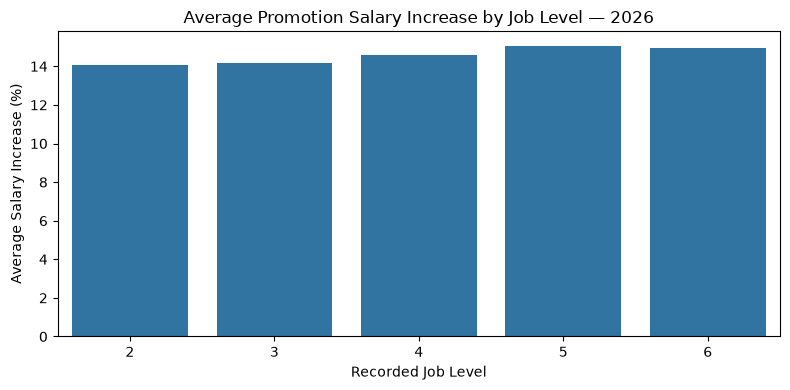

In [45]:

# Merge 2026 promotions with employee job information

promotion_level = promotions_2026.merge(
    employees[["Employee_ID", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

promotion_level = promotion_level.merge(
    jobs[["Job_ID", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Validate merge
print("Total Promotion Records:", len(promotion_level))
print("Missing Job Levels:",
      promotion_level["Job_Level"].isna().sum())

# Average salary increase by recorded job level
promotion_level_summary = (
    promotion_level.groupby("Job_Level")
    .agg(
        Promotion_Count=("Employee_ID", "count"),
        Avg_Salary_Increase=("Salary_Increase_Pct", "mean"),
        Median_Salary_Increase=("Salary_Increase_Pct", "median")
    )
    .reset_index()
    .sort_values("Job_Level")
)

display(promotion_level_summary.round(2))

# Validate total
print(
    "Total Promotions:",
    promotion_level_summary["Promotion_Count"].sum()
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=promotion_level_summary,
    x="Job_Level",
    y="Avg_Salary_Increase"
)

plt.title("Average Promotion Salary Increase by Job Level — 2026")
plt.xlabel("Recorded Job Level")
plt.ylabel("Average Salary Increase (%)")

plt.tight_layout()
plt.show()


Total Employees: 10000
Missing Salary Bands: 0


,Band_Status,Employee_Count,Percentage
0,Below Band,19,0.19
1,Within Band,9980,99.80
2,Above Band,1,0.01


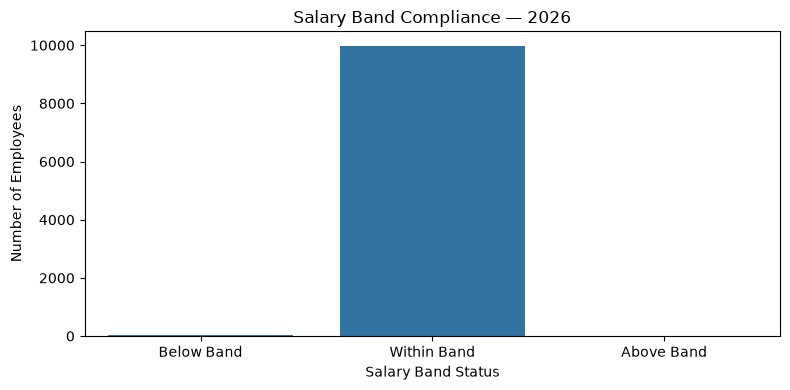

In [46]:

# Prepare employee compensation and job information

band_compliance = compensation_2026.merge(
    employees[["Employee_ID", "Job_ID", "Location"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

band_compliance = band_compliance.merge(
    jobs[["Job_ID", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Match employees to their salary bands
band_compliance = band_compliance.merge(
    salary_bands[
        ["Job_ID", "Location", "Job_Level", "Band_Min", "Band_Max"]
    ],
    on=["Job_ID", "Location", "Job_Level"],
    how="left",
    validate="many_to_one"
)

# Validate merges
print("Total Employees:", len(band_compliance))

print(
    "Missing Salary Bands:",
    band_compliance["Band_Min"].isna().sum()
)

# Classify salary band compliance
band_compliance["Band_Status"] = np.select(
    [
        band_compliance["Base_Salary"] < band_compliance["Band_Min"],
        band_compliance["Base_Salary"] > band_compliance["Band_Max"]
    ],
    ["Below Band", "Above Band"],
    default="Within Band"
)

# Summarize salary band compliance
band_summary = (
    band_compliance["Band_Status"]
    .value_counts()
    .reindex(
        ["Below Band", "Within Band", "Above Band"],
        fill_value=0
    )
    .reset_index()
)

band_summary.columns = ["Band_Status", "Employee_Count"]

band_summary["Percentage"] = (
    band_summary["Employee_Count"]
    / band_summary["Employee_Count"].sum()
    * 100
).round(2)

display(band_summary)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=band_summary,
    x="Band_Status",
    y="Employee_Count"
)

plt.title("Salary Band Compliance — 2026")
plt.xlabel("Salary Band Status")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


**Business Insight — Salary Band Compliance (2026)**

- Salary band compliance is 99.80%, with 9,980 employees earning within their assigned salary ranges.
- A total of 20 employees fall outside their salary bands: 19 below the minimum and 1 above the maximum.
- The high compliance rate indicates strong alignment between recorded salaries and established compensation bands.
- Out-of-band salaries should be reviewed to determine whether corrective adjustments or documented exceptions are necessary.

In [47]:

# Calculate salary band differences

band_compliance["Below_Band_Shortfall"] = np.where(
    band_compliance["Base_Salary"] < band_compliance["Band_Min"],
    band_compliance["Band_Min"] - band_compliance["Base_Salary"],
    0
)

band_compliance["Above_Band_Excess"] = np.where(
    band_compliance["Base_Salary"] > band_compliance["Band_Max"],
    band_compliance["Base_Salary"] - band_compliance["Band_Max"],
    0
)

# Summarize adjustment amounts

adjustment_summary = pd.DataFrame({
    "Metric": [
        "Employees Below Band",
        "Employees Above Band",
        "Total Below-Band Shortfall (INR)",
        "Total Above-Band Excess (INR)"
    ],
    "Value": [
        (band_compliance["Band_Status"] == "Below Band").sum(),
        (band_compliance["Band_Status"] == "Above Band").sum(),
        band_compliance["Below_Band_Shortfall"].sum(),
        band_compliance["Above_Band_Excess"].sum()
    ]
})

display(adjustment_summary.round(2))

# Validation
print(
    "Employees Requiring Minimum-Band Adjustment:",
    (band_compliance["Below_Band_Shortfall"] > 0).sum()
)

print(
    "Total Minimum-Band Adjustment Cost (INR):",
    round(band_compliance["Below_Band_Shortfall"].sum(), 2)
)


,Metric,Value
0,Employees Below Band,19.00
1,Employees Above Band,1.00
2,Total Below-Band Shortfall (INR),"267,993.93"
3,Total Above-Band Excess (INR),"162,972.82"


Employees Requiring Minimum-Band Adjustment: 19
Total Minimum-Band Adjustment Cost (INR): 267993.93


In [48]:

# Add department information to salary band compliance data

department_band = band_compliance.merge(
    jobs[["Job_ID", "Department"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Validate merge
print("Total Employees:", len(department_band))
print(
    "Missing Departments:",
    department_band["Department"].isna().sum()
)

# Count employees by department and band status
department_band_summary = (
    department_band.groupby(
        ["Department", "Band_Status"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=["Below Band", "Within Band", "Above Band"],
        fill_value=0
    )
    .reset_index()
)

# Calculate compliance rate
department_band_summary["Total_Employees"] = (
    department_band_summary[
        ["Below Band", "Within Band", "Above Band"]
    ].sum(axis=1)
)

department_band_summary["Compliance_Rate"] = (
    department_band_summary["Within Band"]
    / department_band_summary["Total_Employees"]
    * 100
).round(2)

# Sort by below-band employee count
department_band_summary = department_band_summary.sort_values(
    ["Below Band", "Above Band"],
    ascending=False
)

display(department_band_summary)

# Validate totals
print(
    "Total Below Band:",
    department_band_summary["Below Band"].sum()
)

print(
    "Total Within Band:",
    department_band_summary["Within Band"].sum()
)

print(
    "Total Above Band:",
    department_band_summary["Above Band"].sum()
)


Total Employees: 10000
Missing Departments: 0


Band_Status,Department,Below Band,Within Band,Above Band,Total_Employees,Compliance_Rate
3,Human Resources,4,664,0,668,99.40
10,Supply Chain,4,731,0,735,99.46
11,Technology,3,1265,0,1268,99.76
2,Finance,2,768,0,770,99.74
5,Legal & Compliance,2,712,0,714,99.72
7,Operations,2,663,0,665,99.70
1,Customer Success,1,645,0,646,99.85
6,Marketing,1,696,0,697,99.86
8,Product,0,944,1,945,99.89
0,Analytics,0,766,0,766,100.00


Total Below Band: 19
Total Within Band: 9980
Total Above Band: 1


**Business Insight — Department-Level Salary Band Compliance (2026)**

- All departments maintain salary band compliance above 99%.
- Human Resources and Supply Chain have the highest number of below-band employees, with four each.
- Product contains the only above-band employee.
- Analytics, Leadership, and Sales have complete salary band compliance.
- Compensation reviews should prioritize departments with below-band employees while considering the size of each department and the financial value of required adjustments.

,Department,Below_Band_Employees,Total_Shortfall
5,Legal & Compliance,2,"67,525.64"
7,Operations,2,"44,588.38"
3,Human Resources,4,"41,380.19"
10,Supply Chain,4,"40,125.62"
11,Technology,3,"32,437.19"
2,Finance,2,"29,125.20"
6,Marketing,1,"6,603.93"
1,Customer Success,1,"6,207.78"


Total Below-Band Employees: 19
Total Adjustment Cost (INR): 267993.93


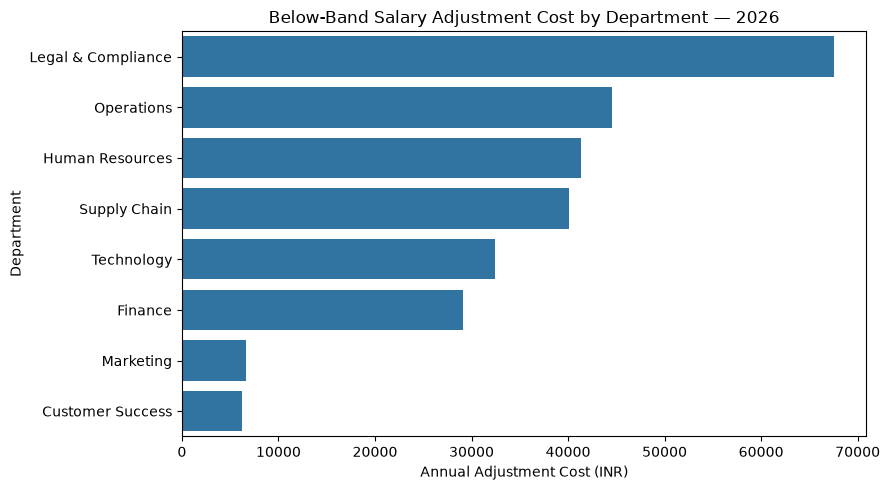

In [49]:

# Calculate below-band adjustment cost by department

department_shortfall_summary = (
    department_band.groupby("Department")
    .agg(
        Below_Band_Employees=(
            "Below_Band_Shortfall",
            lambda x: (x > 0).sum()
        ),
        Total_Shortfall=(
            "Below_Band_Shortfall",
            "sum"
        )
    )
    .reset_index()
)

# Keep departments requiring adjustments
department_shortfall_summary = (
    department_shortfall_summary[
        department_shortfall_summary["Below_Band_Employees"] > 0
    ]
    .sort_values("Total_Shortfall", ascending=False)
)

display(department_shortfall_summary.round(2))

# Validation
print(
    "Total Below-Band Employees:",
    department_shortfall_summary["Below_Band_Employees"].sum()
)

print(
    "Total Adjustment Cost (INR):",
    round(department_shortfall_summary["Total_Shortfall"].sum(), 2)
)

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=department_shortfall_summary,
    x="Total_Shortfall",
    y="Department"
)

plt.title("Below-Band Salary Adjustment Cost by Department — 2026")
plt.xlabel("Annual Adjustment Cost (INR)")
plt.ylabel("Department")

plt.tight_layout()
plt.show()


**Business Insight — Department-Level Salary Adjustment Requirements (2026)**

- Legal & Compliance has the highest estimated annual adjustment requirement at ₹67,525.64.
- Human Resources and Supply Chain each have four below-band employees, the highest counts among departments.
- A total additional annual base salary of ₹2.68 lakh would bring all 19 below-band employees to their assigned minimum salary bands.
- Compensation reviews should consider both the number of affected employees and the financial value of adjustments when prioritizing corrective action.

Total Employees: 10000
Missing Gender Values: 0


Band_Status,Gender,Below Band,Within Band,Above Band,Total_Employees,Compliance_Rate
0,Female,9,4729,0,4738,99.81
1,Male,10,5139,1,5150,99.79
2,Non-binary,0,112,0,112,100.00


Total Below Band: 19
Total Within Band: 9980
Total Above Band: 1


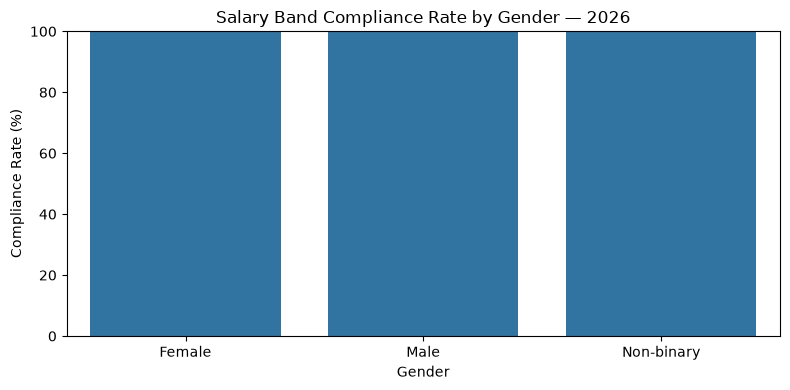

In [50]:

# Merge salary band compliance with gender

gender_band = band_compliance.merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Total Employees:", len(gender_band))
print("Missing Gender Values:", gender_band["Gender"].isna().sum())

# Count salary band status by gender
gender_band_summary = (
    gender_band.groupby(["Gender", "Band_Status"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=["Below Band", "Within Band", "Above Band"],
        fill_value=0
    )
    .reset_index()
)

# Calculate total employees and compliance rate
gender_band_summary["Total_Employees"] = (
    gender_band_summary[
        ["Below Band", "Within Band", "Above Band"]
    ].sum(axis=1)
)

gender_band_summary["Compliance_Rate"] = (
    gender_band_summary["Within Band"]
    / gender_band_summary["Total_Employees"]
    * 100
).round(2)

display(gender_band_summary)

# Validate totals
print("Total Below Band:", gender_band_summary["Below Band"].sum())
print("Total Within Band:", gender_band_summary["Within Band"].sum())
print("Total Above Band:", gender_band_summary["Above Band"].sum())

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=gender_band_summary,
    x="Gender",
    y="Compliance_Rate"
)

plt.title("Salary Band Compliance Rate by Gender — 2026")
plt.xlabel("Gender")
plt.ylabel("Compliance Rate (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


Band_Status,Job_Level,Below Band,Within Band,Above Band,Total_Employees,Compliance_Rate,Out_of_Band_Rate
0,1,4,603,0,607,99.34,0.66
1,2,13,2179,0,2192,99.41,0.59
2,3,2,2064,0,2066,99.90,0.10
3,4,0,2725,0,2725,100.00,0.00
4,5,0,1004,1,1005,99.90,0.10
5,6,0,1405,0,1405,100.00,0.00


Total Employees: 10000
Total Below Band: 19
Total Within Band: 9980
Total Above Band: 1


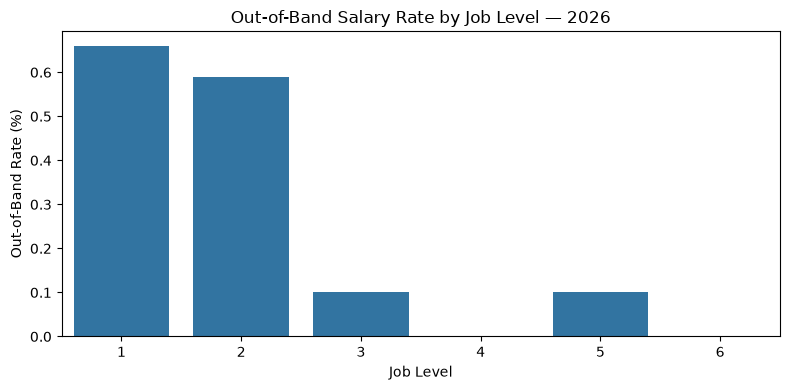

In [51]:

# Salary band compliance by job level

job_level_band_summary = (
    band_compliance.groupby(["Job_Level", "Band_Status"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=["Below Band", "Within Band", "Above Band"],
        fill_value=0
    )
    .reset_index()
    .sort_values("Job_Level")
)

# Calculate total employees
job_level_band_summary["Total_Employees"] = (
    job_level_band_summary[
        ["Below Band", "Within Band", "Above Band"]
    ].sum(axis=1)
)

# Calculate compliance and exception rates
job_level_band_summary["Compliance_Rate"] = (
    job_level_band_summary["Within Band"]
    / job_level_band_summary["Total_Employees"]
    * 100
).round(2)

job_level_band_summary["Out_of_Band_Rate"] = (
    (
        job_level_band_summary["Below Band"]
        + job_level_band_summary["Above Band"]
    )
    / job_level_band_summary["Total_Employees"]
    * 100
).round(2)

display(job_level_band_summary)

# Validation
print(
    "Total Employees:",
    job_level_band_summary["Total_Employees"].sum()
)

print(
    "Total Below Band:",
    job_level_band_summary["Below Band"].sum()
)

print(
    "Total Within Band:",
    job_level_band_summary["Within Band"].sum()
)

print(
    "Total Above Band:",
    job_level_band_summary["Above Band"].sum()
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=job_level_band_summary,
    x="Job_Level",
    y="Out_of_Band_Rate"
)

plt.title("Out-of-Band Salary Rate by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Out-of-Band Rate (%)")

plt.tight_layout()
plt.show()


Invalid Band Ranges: 0


,Job_Level,Employee_Count,Avg_Band_Position,Median_Band_Position
0,1,607,28.94,28.32
1,2,2192,32.23,31.74
2,3,2066,41.66,42.07
3,4,2725,49.94,50.12
4,5,1005,55.58,55.12
5,6,1405,58.38,58.35


Total Employees: 10000
Missing Band Positions: 0
Overall Average Band Position (%): 44.83


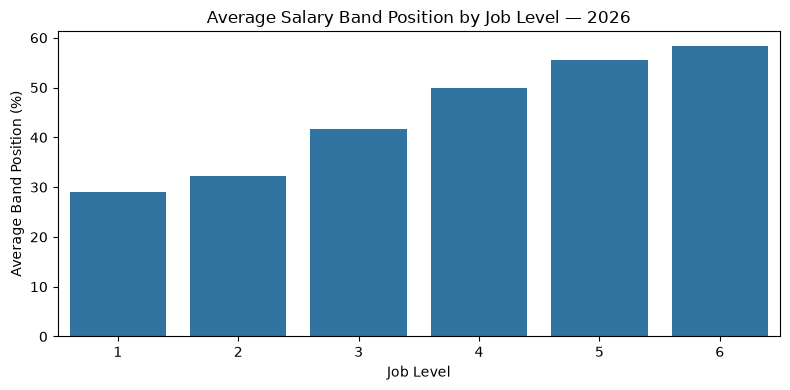

In [52]:

# Calculate employee salary position within assigned bands

band_position = band_compliance.copy()

band_position["Band_Range"] = (
    band_position["Band_Max"] - band_position["Band_Min"]
)

# Check that salary bands have valid ranges
print(
    "Invalid Band Ranges:",
    (band_position["Band_Range"] <= 0).sum()
)

band_position["Band_Position_Pct"] = np.where(
    band_position["Band_Range"] > 0,
    (
        (band_position["Base_Salary"] - band_position["Band_Min"])
        / band_position["Band_Range"]
    ) * 100,
    np.nan
)

# Summarize band position by job level
band_position_summary = (
    band_position.groupby("Job_Level")
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Band_Position=("Band_Position_Pct", "mean"),
        Median_Band_Position=("Band_Position_Pct", "median")
    )
    .reset_index()
    .sort_values("Job_Level")
)

display(band_position_summary.round(2))

# Validation
print("Total Employees:", len(band_position))
print(
    "Missing Band Positions:",
    band_position["Band_Position_Pct"].isna().sum()
)
print(
    "Overall Average Band Position (%):",
    round(band_position["Band_Position_Pct"].mean(), 2)
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=band_position_summary,
    x="Job_Level",
    y="Avg_Band_Position"
)

plt.title("Average Salary Band Position by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Average Band Position (%)")

plt.tight_layout()
plt.show()


,Gender,Employee_Count,Avg_Band_Position,Median_Band_Position
1,Male,5150,46.73,47.14
2,Non-binary,112,44.48,44.56
0,Female,4738,42.77,43.26


Total Employees: 10000
Missing Gender Values: 0
Overall Average Band Position (%): 44.83


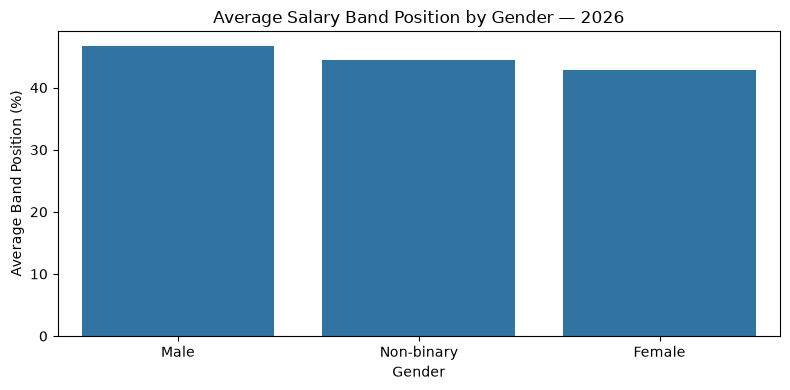

In [53]:

# Add employee gender to salary band position data

gender_band_position = band_position.merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Summarize band position by gender
gender_position_summary = (
    gender_band_position.groupby("Gender")
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Band_Position=("Band_Position_Pct", "mean"),
        Median_Band_Position=("Band_Position_Pct", "median")
    )
    .reset_index()
    .sort_values("Avg_Band_Position", ascending=False)
)

display(gender_position_summary.round(2))

# Validation
print("Total Employees:", len(gender_band_position))
print(
    "Missing Gender Values:",
    gender_band_position["Gender"].isna().sum()
)
print(
    "Overall Average Band Position (%):",
    round(gender_band_position["Band_Position_Pct"].mean(), 2)
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=gender_position_summary,
    x="Gender",
    y="Avg_Band_Position"
)

plt.title("Average Salary Band Position by Gender — 2026")
plt.xlabel("Gender")
plt.ylabel("Average Band Position (%)")

plt.tight_layout()
plt.show()


### Gender Pay Gap by Department (2026)

**Objective:** Compare average base salaries between male and female employees across departments.

**Formula:**

$$
\text{Gender Pay Gap (\%)} =
\frac{\text{Male Average Salary} - \text{Female Average Salary}}
{\text{Male Average Salary}} \times 100
$$

**Interpretation:**
- Positive percentage: Male average salary is higher.
- Negative percentage: Female average salary is higher.
- Zero: Both groups have equal average salaries.

**Business Insight:** Customer Success has the highest unadjusted pay gap at 4.82%. Technology and Supply Chain show negative gaps. Further analysis controlling for job level and experience is necessary before drawing pay equity conclusions.

,Job_Level,Gender,Employee_Count,Avg_Band_Position
0,1,Female,277,27.15
1,1,Male,322,30.44
2,1,Non-binary,8,30.48
3,2,Female,1026,30.26
4,2,Male,1144,34.03
5,2,Non-binary,22,29.90
6,3,Female,992,39.50
7,3,Male,1046,43.67
8,3,Non-binary,28,43.16
9,4,Female,1294,47.77


Total Employees: 10000
Missing Band Positions: 0


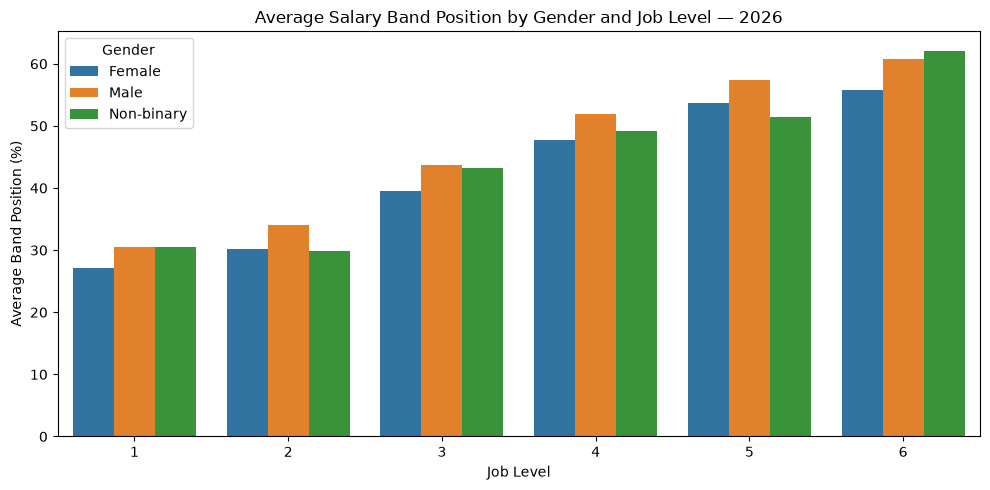

In [54]:

# Compare salary band position by gender within each job level

gender_level_position = (
    gender_band_position.groupby(["Job_Level", "Gender"])
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Band_Position=("Band_Position_Pct", "mean")
    )
    .reset_index()
    .sort_values(["Job_Level", "Gender"])
)

display(gender_level_position.round(2))

# Validation
print(
    "Total Employees:",
    gender_level_position["Employee_Count"].sum()
)

print(
    "Missing Band Positions:",
    gender_band_position["Band_Position_Pct"].isna().sum()
)

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=gender_level_position,
    x="Job_Level",
    y="Avg_Band_Position",
    hue="Gender"
)

plt.title("Average Salary Band Position by Gender and Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Average Band Position (%)")
plt.legend(title="Gender")

plt.tight_layout()
plt.show()


**Business Insight — Gender Differences in Salary Band Position (2026)**

- Male employees have higher average salary band positions than female employees across all six job levels.
- The observed differences range from 3.29 to 4.99 percentage points.
- The largest difference occurs at Job Level 6.
- These findings indicate a consistent descriptive gender difference in salary positioning that warrants further investigation.
- Additional comparisons by job role, department, and experience are needed before drawing conclusions about pay equity.

### Gender Pay Gap by Department (2026)

**Objective:** Compare average base salaries between male and female employees across departments.

**Formula:**

$$
\text{Gender Pay Gap (\%)} =
\frac{\text{Male Average Salary} - \text{Female Average Salary}}
{\text{Male Average Salary}} \times 100
$$

**Interpretation:**
- Positive percentage: Male average salary is higher.
- Negative percentage: Female average salary is higher.
- Zero: Both groups have equal average salaries.

**Business Insight:** Customer Success has the highest unadjusted pay gap at 4.82%. Technology and Supply Chain show negative gaps. Further analysis controlling for job level and experience is necessary before drawing pay equity conclusions.

Gender,Department,Female,Male,Pay_Gap_Pct
1,Customer Success,"1,072,338.80","1,126,678.47",4.82
0,Analytics,"1,272,371.95","1,319,066.90",3.54
7,Operations,"1,096,140.30","1,133,016.73",3.25
6,Marketing,"1,206,456.62","1,232,031.48",2.08
4,Leadership,"5,446,482.22","5,559,176.49",2.03
2,Finance,"1,245,465.82","1,266,863.80",1.69
5,Legal & Compliance,"1,357,999.31","1,378,638.99",1.50
3,Human Resources,"1,029,807.22","1,042,038.55",1.17
8,Product,"2,403,645.67","2,424,126.63",0.84
9,Sales,"1,233,256.78","1,235,353.92",0.17


Employees Analyzed: 9888
Missing Departments: 0
Departments Analyzed: 12


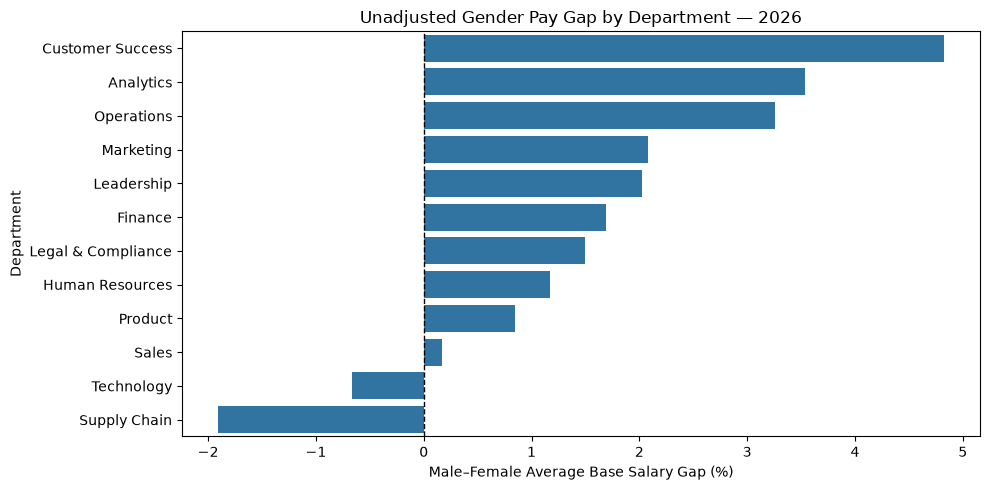

In [55]:

# Prepare 2026 salary data with department and gender

department_pay = compensation_2026[
    ["Employee_ID", "Base_Salary"]
].merge(
    employees[["Employee_ID", "Gender", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

department_pay = department_pay.merge(
    jobs[["Job_ID", "Department"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Focus on male and female employees
department_pay = department_pay[
    department_pay["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average base salary by department and gender
department_gender_salary = (
    department_pay.groupby(["Department", "Gender"])["Base_Salary"]
    .mean()
    .unstack()
)

# Calculate unadjusted gender pay gap
department_gender_salary["Pay_Gap_Pct"] = (
    (
        department_gender_salary["Male"]
        - department_gender_salary["Female"]
    )
    / department_gender_salary["Male"]
    * 100
)

department_gender_salary = (
    department_gender_salary
    .reset_index()
    .sort_values("Pay_Gap_Pct", ascending=False)
)

display(department_gender_salary.round(2))

# Validation
print("Employees Analyzed:", len(department_pay))
print(
    "Missing Departments:",
    department_pay["Department"].isna().sum()
)
print(
    "Departments Analyzed:",
    department_gender_salary["Department"].nunique()
)

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=department_gender_salary,
    x="Pay_Gap_Pct",
    y="Department"
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)

plt.title("Unadjusted Gender Pay Gap by Department — 2026")
plt.xlabel("Male–Female Average Base Salary Gap (%)")
plt.ylabel("Department")

plt.tight_layout()
plt.show()


### Gender Pay Gap by Job Level (2026)

**Objective:** Calculate the percentage difference between male and female average base salaries within each job level.

**Formula:**

$$
\text{Gender Pay Gap (\%)} =
\frac{\text{Male Average Base Salary} - \text{Female Average Base Salary}}
{\text{Male Average Base Salary}} \times 100
$$

A positive value indicates a higher male average salary, while a negative value indicates a higher female average salary.

This is a descriptive job-level comparison, not a fully adjusted pay equity analysis.

Gender,Job_Level,Female,Male,Pay_Gap_Pct
0,1,"392,017.69","404,245.90",3.02
1,2,"715,137.35","725,378.37",1.41
2,3,"1,175,199.19","1,209,007.63",2.80
3,4,"1,864,280.02","1,900,184.16",1.89
4,5,"3,276,591.28","3,337,541.57",1.83
5,6,"5,446,482.22","5,559,176.49",2.03


Employees Analyzed: 9888
Missing Job Levels: 0
Job Levels Analyzed: 6


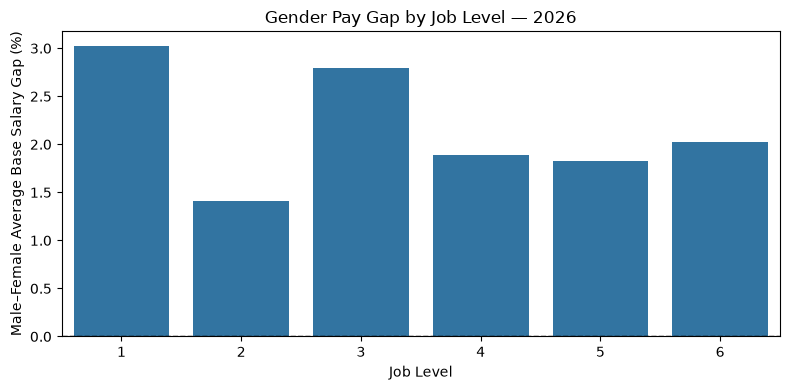

In [56]:

# Prepare 2026 salary data with gender and job level

level_pay = compensation_2026[
    ["Employee_ID", "Base_Salary"]
].merge(
    employees[["Employee_ID", "Gender", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

level_pay = level_pay.merge(
    jobs[["Job_ID", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Include male and female employees
level_pay = level_pay[
    level_pay["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average salary by job level and gender
level_gender_salary = (
    level_pay.groupby(["Job_Level", "Gender"])["Base_Salary"]
    .mean()
    .unstack()
)

# Calculate gender pay gap percentage
level_gender_salary["Pay_Gap_Pct"] = (
    (
        level_gender_salary["Male"]
        - level_gender_salary["Female"]
    )
    / level_gender_salary["Male"]
    * 100
)

level_gender_salary = (
    level_gender_salary
    .reset_index()
    .sort_values("Job_Level")
)

display(level_gender_salary.round(2))

# Validation
print("Employees Analyzed:", len(level_pay))
print("Missing Job Levels:", level_pay["Job_Level"].isna().sum())
print("Job Levels Analyzed:", level_gender_salary["Job_Level"].nunique())

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=level_gender_salary,
    x="Job_Level",
    y="Pay_Gap_Pct"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Gender Pay Gap by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Male–Female Average Base Salary Gap (%)")

plt.tight_layout()
plt.show()


### Gender Pay Gap by Department and Job Level (2026)

**Objective:** Compare average base salaries between male and female employees within the same department and job level.

**Formula:**

$$
\text{Gender Pay Gap (\%)} =
\frac{\text{Male Average Base Salary} - \text{Female Average Base Salary}}
{\text{Male Average Base Salary}} \times 100
$$

A positive percentage indicates a higher male average salary, while a negative percentage indicates a higher female average salary.

This comparison accounts descriptively for department and job level but does not control for individual job titles, experience, or other compensation factors.

Gender,Department,Job_Level,Female,Male,Pay_Gap_Pct,Male_Count,Female_Count
32,Sales,3,"1,159,884.03","1,205,429.34",3.78,83,81
10,Human Resources,1,"386,164.16","400,970.01",3.69,60,47
3,Customer Success,1,"363,867.97","377,548.94",3.62,52,69
9,Finance,4,"1,884,199.12","1,953,968.83",3.57,112,113
23,Operations,2,"630,006.66","649,543.67",3.01,68,67
39,Technology,4,"2,082,496.06","2,142,586.93",2.80,97,98
15,Legal & Compliance,2,"742,487.12","763,141.82",2.71,130,124
25,Operations,4,"1,694,010.79","1,740,294.37",2.66,137,123
8,Finance,3,"1,174,643.83","1,205,610.33",2.57,152,137
38,Technology,3,"1,304,843.29","1,339,173.14",2.56,170,134


Employees Analyzed: 9888
Missing Departments: 0
Missing Job Levels: 0
Comparable Department-Level Groups: 41


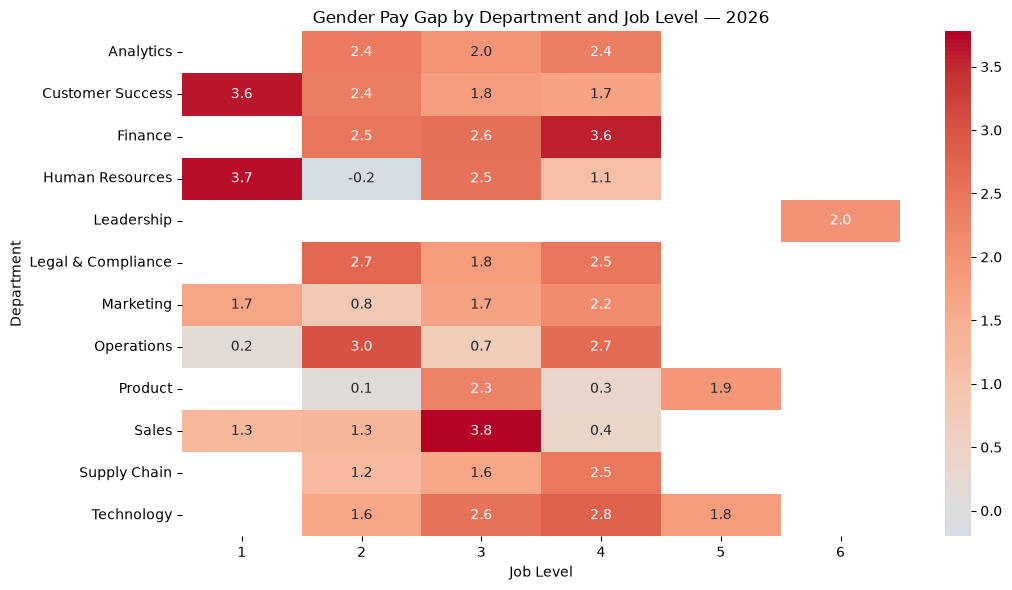

In [57]:

# Prepare 2026 salary data with gender, department and job level

detailed_pay = compensation_2026[
    ["Employee_ID", "Base_Salary"]
].merge(
    employees[["Employee_ID", "Gender", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

detailed_pay = detailed_pay.merge(
    jobs[["Job_ID", "Department", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Focus on male and female employees
detailed_pay = detailed_pay[
    detailed_pay["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average salary and employee counts
group_summary = (
    detailed_pay.groupby(
        ["Department", "Job_Level", "Gender"]
    )
    .agg(
        Avg_Base_Salary=("Base_Salary", "mean"),
        Employee_Count=("Employee_ID", "count")
    )
    .reset_index()
)

salary_pivot = group_summary.pivot(
    index=["Department", "Job_Level"],
    columns="Gender",
    values="Avg_Base_Salary"
)

count_pivot = group_summary.pivot(
    index=["Department", "Job_Level"],
    columns="Gender",
    values="Employee_Count"
)

# Keep only groups containing both genders
salary_pivot = salary_pivot.dropna(subset=["Male", "Female"])

# Calculate pay gap
salary_pivot["Pay_Gap_Pct"] = (
    (salary_pivot["Male"] - salary_pivot["Female"])
    / salary_pivot["Male"] * 100
)

# Add group sizes for interpretation
salary_pivot["Male_Count"] = count_pivot["Male"]
salary_pivot["Female_Count"] = count_pivot["Female"]

department_level_gap = (
    salary_pivot.reset_index()
    .sort_values("Pay_Gap_Pct", ascending=False)
)

display(department_level_gap.round(2))

# Validation
print("Employees Analyzed:", len(detailed_pay))
print(
    "Missing Departments:",
    detailed_pay["Department"].isna().sum()
)
print(
    "Missing Job Levels:",
    detailed_pay["Job_Level"].isna().sum()
)
print(
    "Comparable Department-Level Groups:",
    len(department_level_gap)
)

# Visualization
plt.figure(figsize=(11, 6))

gap_heatmap = department_level_gap.pivot(
    index="Department",
    columns="Job_Level",
    values="Pay_Gap_Pct"
)

sns.heatmap(
    gap_heatmap,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    center=0
)

plt.title("Gender Pay Gap by Department and Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Department")

plt.tight_layout()
plt.show()


### Gender Pay Gap by Experience Group (2026)

**Objective:** Compare male and female average base salaries within professional experience groups.

**Formula:**

$$
\text{Gender Pay Gap (\%)} =
\frac{\text{Male Average Base Salary} - \text{Female Average Base Salary}}
{\text{Male Average Base Salary}} \times 100
$$

Positive values indicate higher male average salaries; negative values indicate higher female average salaries.

This analysis controls descriptively for experience groups but not for job level, job title, or department.

Gender,Experience_Group,Female,Male,Pay_Gap_Pct
0,0-5 Years,"695,941.60","698,025.87",0.30
1,6-10 Years,"1,182,129.09","1,192,214.82",0.85
2,11-15 Years,"1,836,579.12","1,910,966.25",3.89
3,16-20 Years,"3,539,452.15","3,610,731.54",1.97
4,20+ Years,"5,247,151.40","5,341,619.05",1.77


Employees Analyzed: 9863
Missing Experience Values After Filtering: 0
Experience Groups Analyzed: 5


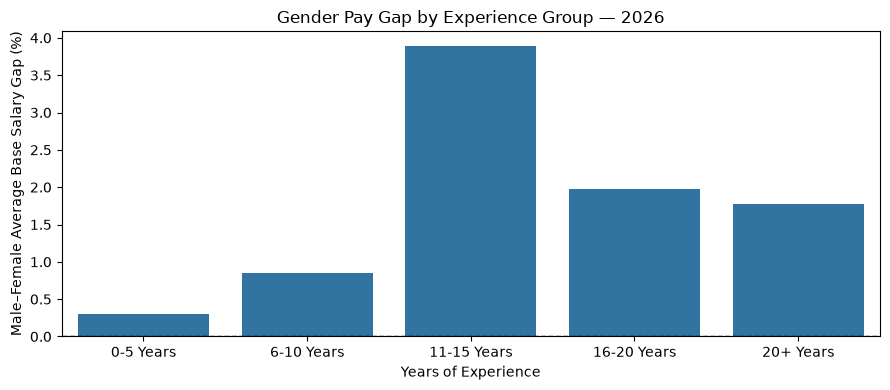

In [58]:

# Prepare salary data with gender and experience

experience_pay = compensation_2026[
    ["Employee_ID", "Base_Salary"]
].merge(
    employees[["Employee_ID", "Gender", "Years_Experience"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Include male and female employees with known experience
experience_pay = experience_pay[
    experience_pay["Gender"].isin(["Male", "Female"])
    & experience_pay["Years_Experience"].notna()
].copy()

# Create experience groups
experience_pay["Experience_Group"] = pd.cut(
    experience_pay["Years_Experience"],
    bins=[-1, 5, 10, 15, 20, float("inf")],
    labels=[
        "0-5 Years",
        "6-10 Years",
        "11-15 Years",
        "16-20 Years",
        "20+ Years"
    ]
)

# Calculate average salary by experience group and gender
experience_gender_salary = (
    experience_pay.groupby(
        ["Experience_Group", "Gender"],
        observed=True
    )["Base_Salary"]
    .mean()
    .unstack()
)

# Calculate gender pay gap
experience_gender_salary["Pay_Gap_Pct"] = (
    (
        experience_gender_salary["Male"]
        - experience_gender_salary["Female"]
    )
    / experience_gender_salary["Male"]
    * 100
)

experience_gender_salary = experience_gender_salary.reset_index()

display(experience_gender_salary.round(2))

# Validation
print("Employees Analyzed:", len(experience_pay))
print(
    "Missing Experience Values After Filtering:",
    experience_pay["Years_Experience"].isna().sum()
)
print(
    "Experience Groups Analyzed:",
    experience_gender_salary["Experience_Group"].nunique()
)

# Visualization
plt.figure(figsize=(9, 4))

sns.barplot(
    data=experience_gender_salary,
    x="Experience_Group",
    y="Pay_Gap_Pct"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Gender Pay Gap by Experience Group — 2026")
plt.xlabel("Years of Experience")
plt.ylabel("Male–Female Average Base Salary Gap (%)")

plt.tight_layout()
plt.show()


### Gender Pay Gap by Location (2026)

**Objective:** Compare male and female average base salaries across office locations to identify geographical differences in the unadjusted gender pay gap.

**Formula:**

$$
\text{Gender Pay Gap (\%)} =
\frac{\text{Male Average Base Salary} - \text{Female Average Base Salary}}{\text{Male Average Base Salary}} \times 100
$$

A positive value indicates higher male average base salary, while a negative value indicates higher female average base salary.

This is an unadjusted comparison and does not account for differences in job level, department, or experience.

Gender,Location,Female,Male,Pay_Gap_Pct
0,Bengaluru,"1,990,691.99","2,150,806.80",7.44
1,Chennai,"1,871,956.28","1,988,155.13",5.84
5,Pune,"1,978,809.44","1,988,629.14",0.49
3,Hyderabad,"2,012,524.85","1,992,339.11",-1.01
4,Mumbai,"2,187,040.47","2,120,454.86",-3.14
2,Gurugram,"2,265,947.18","2,048,905.01",-10.59


Employees Analyzed: 9888
Missing Locations: 0
Locations Analyzed: 6


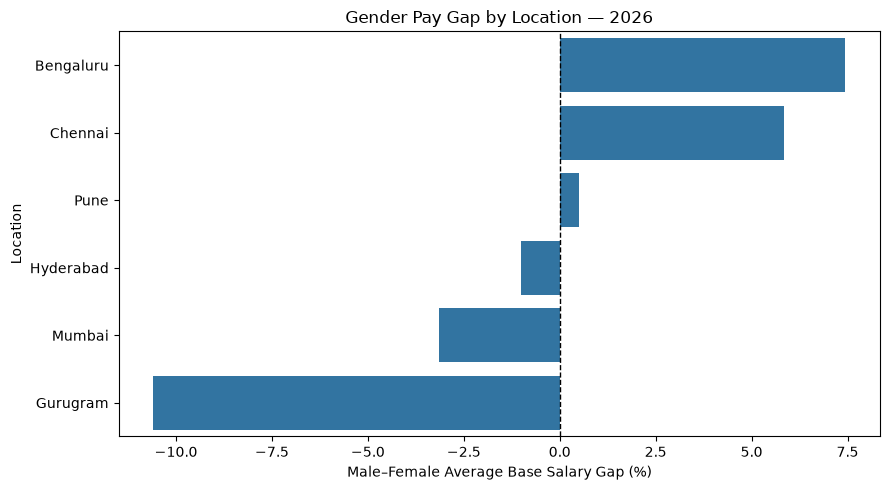

In [59]:

# Prepare 2026 salary data with gender and location

location_pay = compensation_2026[
    ["Employee_ID", "Base_Salary"]
].merge(
    employees[["Employee_ID", "Gender", "Location"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Include male and female employees
location_pay = location_pay[
    location_pay["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average salary by location and gender
location_gender_salary = (
    location_pay.groupby(["Location", "Gender"])["Base_Salary"]
    .mean()
    .unstack()
)

# Calculate gender pay gap
location_gender_salary["Pay_Gap_Pct"] = (
    (
        location_gender_salary["Male"]
        - location_gender_salary["Female"]
    )
    / location_gender_salary["Male"]
    * 100
)

location_gender_salary = (
    location_gender_salary
    .reset_index()
    .sort_values("Pay_Gap_Pct", ascending=False)
)

display(location_gender_salary.round(2))

# Validation
print("Employees Analyzed:", len(location_pay))
print("Missing Locations:", location_pay["Location"].isna().sum())
print("Locations Analyzed:", location_gender_salary["Location"].nunique())

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=location_gender_salary,
    x="Pay_Gap_Pct",
    y="Location"
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)

plt.title("Gender Pay Gap by Location — 2026")
plt.xlabel("Male–Female Average Base Salary Gap (%)")
plt.ylabel("Location")

plt.tight_layout()
plt.show()


Gender,Employment_Type,Female,Male,Pay_Gap_Pct,Female_Count,Male_Count
0,Full-time,"2,043,545.47","2,059,367.54",0.77,4554,4924
1,Part-time,"1,832,390.20","2,073,848.16",11.64,184,226


Employees Analyzed: 9888
Missing Employment Types: 0
Employment Types Analyzed: 2


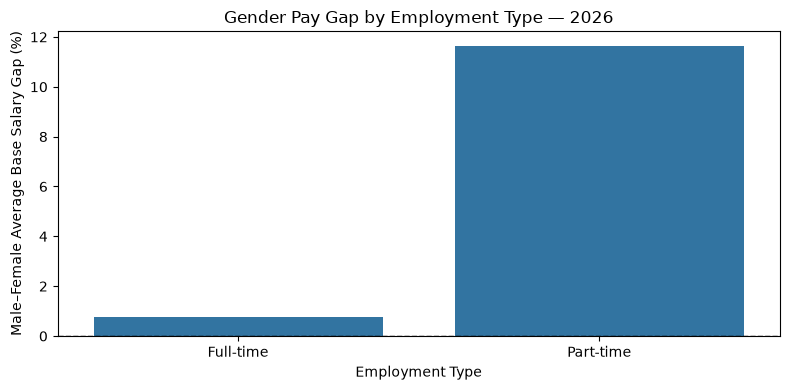

In [60]:

# Prepare 2026 salary data

employment_pay = compensation_2026[
    ["Employee_ID", "Base_Salary"]
].merge(
    employees[
        ["Employee_ID", "Gender", "Employment_Type"]
    ],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Include male and female employees
employment_pay = employment_pay[
    employment_pay["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average salary and employee counts
employment_summary = (
    employment_pay.groupby(
        ["Employment_Type", "Gender"]
    )
    .agg(
        Avg_Base_Salary=("Base_Salary", "mean"),
        Employee_Count=("Employee_ID", "count")
    )
    .reset_index()
)

# Pivot average salaries
salary_pivot = employment_summary.pivot(
    index="Employment_Type",
    columns="Gender",
    values="Avg_Base_Salary"
)

# Pivot employee counts
count_pivot = employment_summary.pivot(
    index="Employment_Type",
    columns="Gender",
    values="Employee_Count"
)

# Calculate gender pay gap
salary_pivot["Pay_Gap_Pct"] = (
    (salary_pivot["Male"] - salary_pivot["Female"])
    / salary_pivot["Male"] * 100
)

salary_pivot["Female_Count"] = count_pivot["Female"]
salary_pivot["Male_Count"] = count_pivot["Male"]

employment_gender_gap = salary_pivot.reset_index()

display(employment_gender_gap.round(2))

# Validation
print("Employees Analyzed:", len(employment_pay))
print(
    "Missing Employment Types:",
    employment_pay["Employment_Type"].isna().sum()
)
print(
    "Employment Types Analyzed:",
    employment_gender_gap["Employment_Type"].nunique()
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=employment_gender_gap,
    x="Employment_Type",
    y="Pay_Gap_Pct"
)

plt.axhline(
    0, color="black", linestyle="--", linewidth=1
)

plt.title("Gender Pay Gap by Employment Type — 2026")
plt.xlabel("Employment Type")
plt.ylabel("Male–Female Average Base Salary Gap (%)")

plt.tight_layout()
plt.show()


Gender,Employment_Status,Female,Male,Pay_Gap_Pct,Female_Count,Male_Count
0,Active,"2,045,392.68","2,058,992.30",0.66,4491,4872
1,Exited,"1,852,661.33","2,077,715.76",10.83,247,278


Employees Analyzed: 9888
Missing Employment Status: 0
Employment Status Groups: 2


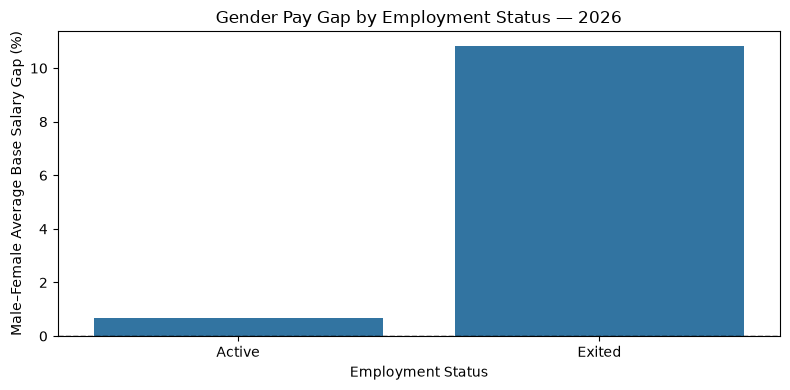

In [61]:

# Prepare 2026 salary data with gender and employment status

status_pay = compensation_2026[
    ["Employee_ID", "Base_Salary"]
].merge(
    employees[
        ["Employee_ID", "Gender", "Employment_Status"]
    ],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Include male and female employees
status_pay = status_pay[
    status_pay["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average salaries and employee counts
status_summary = (
    status_pay.groupby(
        ["Employment_Status", "Gender"]
    )
    .agg(
        Avg_Base_Salary=("Base_Salary", "mean"),
        Employee_Count=("Employee_ID", "count")
    )
    .reset_index()
)

# Pivot average salaries
salary_pivot = status_summary.pivot(
    index="Employment_Status",
    columns="Gender",
    values="Avg_Base_Salary"
)

# Pivot employee counts
count_pivot = status_summary.pivot(
    index="Employment_Status",
    columns="Gender",
    values="Employee_Count"
)

# Calculate gender pay gap
salary_pivot["Pay_Gap_Pct"] = (
    (salary_pivot["Male"] - salary_pivot["Female"])
    / salary_pivot["Male"] * 100
)

salary_pivot["Female_Count"] = count_pivot["Female"]
salary_pivot["Male_Count"] = count_pivot["Male"]

status_gender_gap = salary_pivot.reset_index()

display(status_gender_gap.round(2))

# Validation
print("Employees Analyzed:", len(status_pay))
print(
    "Missing Employment Status:",
    status_pay["Employment_Status"].isna().sum()
)
print(
    "Employment Status Groups:",
    status_gender_gap["Employment_Status"].nunique()
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=status_gender_gap,
    x="Employment_Status",
    y="Pay_Gap_Pct"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Gender Pay Gap by Employment Status — 2026")
plt.xlabel("Employment Status")
plt.ylabel("Male–Female Average Base Salary Gap (%)")

plt.tight_layout()
plt.show()


Gender,Performance_Rating,Performance_Category,Female,Male,Pay_Gap_Pct,Female_Count,Male_Count
0,1.00,Needs Improvement,"2,009,242.44","2,113,128.91",4.92,200,209
1,2.00,Developing,"1,952,492.40","2,004,353.97",2.59,516,588
2,3.00,Meets Expectations,"1,976,057.46","2,033,947.31",2.85,2465,2648
3,4.00,Exceeds Expectations,"2,158,325.63","2,083,391.64",-3.60,1268,1397
4,5.00,Outstanding,"2,167,448.98","2,248,119.46",3.59,289,308


Employees Analyzed: 9888
Missing Performance Ratings: 0
Performance Ratings Analyzed: 5


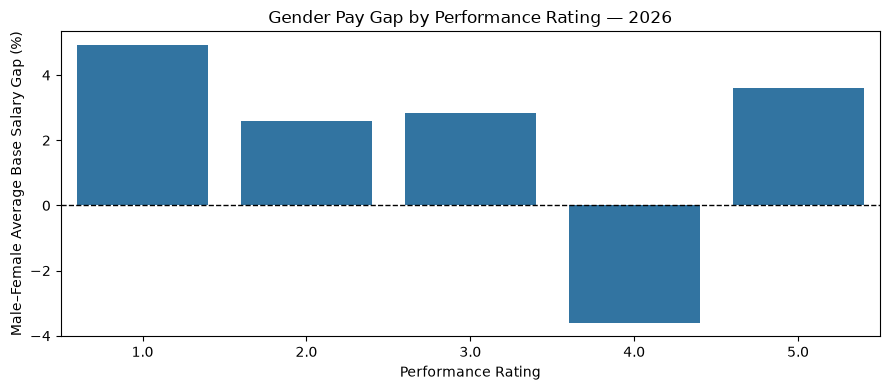

In [62]:

# Prepare 2026 salary data with gender

performance_pay = compensation_2026[
    ["Employee_ID", "Base_Salary"]
].merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Add 2026 performance ratings
performance_2026 = performance[
    performance["Review_Year"] == 2026
][["Employee_ID", "Performance_Rating", "Performance_Category"]]

performance_pay = performance_pay.merge(
    performance_2026,
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Include male and female employees
performance_pay = performance_pay[
    performance_pay["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average salary and employee counts
performance_summary = (
    performance_pay.groupby(
        ["Performance_Rating", "Performance_Category", "Gender"]
    )
    .agg(
        Avg_Base_Salary=("Base_Salary", "mean"),
        Employee_Count=("Employee_ID", "count")
    )
    .reset_index()
)

# Pivot average salaries
salary_pivot = performance_summary.pivot(
    index=["Performance_Rating", "Performance_Category"],
    columns="Gender",
    values="Avg_Base_Salary"
)

# Pivot employee counts
count_pivot = performance_summary.pivot(
    index=["Performance_Rating", "Performance_Category"],
    columns="Gender",
    values="Employee_Count"
)

# Calculate gender pay gap
salary_pivot["Pay_Gap_Pct"] = (
    (salary_pivot["Male"] - salary_pivot["Female"])
    / salary_pivot["Male"] * 100
)

salary_pivot["Female_Count"] = count_pivot["Female"]
salary_pivot["Male_Count"] = count_pivot["Male"]

performance_gender_gap = (
    salary_pivot
    .reset_index()
    .sort_values("Performance_Rating")
)

display(performance_gender_gap.round(2))

# Validation
print("Employees Analyzed:", len(performance_pay))
print(
    "Missing Performance Ratings:",
    performance_pay["Performance_Rating"].isna().sum()
)
print(
    "Performance Ratings Analyzed:",
    performance_gender_gap["Performance_Rating"].nunique()
)

# Visualization
plt.figure(figsize=(9, 4))

sns.barplot(
    data=performance_gender_gap,
    x="Performance_Rating",
    y="Pay_Gap_Pct"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Gender Pay Gap by Performance Rating — 2026")
plt.xlabel("Performance Rating")
plt.ylabel("Male–Female Average Base Salary Gap (%)")

plt.tight_layout()
plt.show()


Gender,Promotion_Status,Female,Male,Pay_Gap_Pct,Female_Count,Male_Count
0,Not Promoted,"2,018,662.83","2,029,110.83",0.51,4277,4654
1,Promoted,"2,190,119.19","2,349,866.29",6.80,461,496


Employees Analyzed: 9888
Promoted Employees Analyzed: 957
Promotion Status Groups: 2


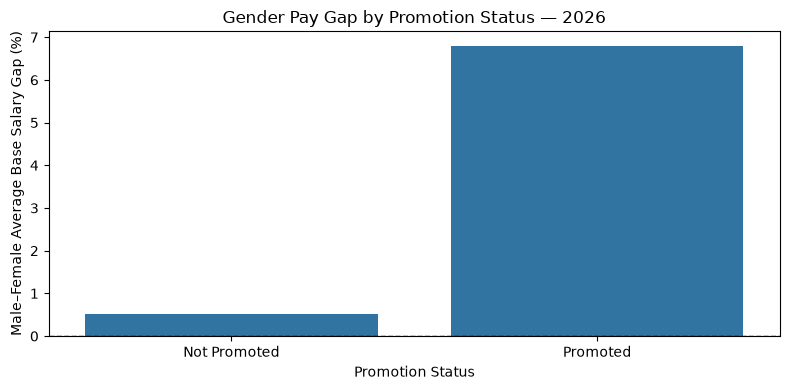

In [63]:

# Prepare 2026 salary data with gender

promotion_pay = compensation_2026[
    ["Employee_ID", "Base_Salary"]
].merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Identify employees promoted in 2026
promoted_2026 = promotions.loc[
    promotions["Promotion_Date"].dt.year == 2026,
    "Employee_ID"
].unique()

promotion_pay["Promotion_Status"] = np.where(
    promotion_pay["Employee_ID"].isin(promoted_2026),
    "Promoted",
    "Not Promoted"
)

# Include male and female employees
promotion_pay = promotion_pay[
    promotion_pay["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average salaries and employee counts
promotion_summary = (
    promotion_pay.groupby(["Promotion_Status", "Gender"])
    .agg(
        Avg_Base_Salary=("Base_Salary", "mean"),
        Employee_Count=("Employee_ID", "count")
    )
    .reset_index()
)

# Pivot average salaries
salary_pivot = promotion_summary.pivot(
    index="Promotion_Status",
    columns="Gender",
    values="Avg_Base_Salary"
)

# Pivot employee counts
count_pivot = promotion_summary.pivot(
    index="Promotion_Status",
    columns="Gender",
    values="Employee_Count"
)

# Calculate gender pay gap
salary_pivot["Pay_Gap_Pct"] = (
    (salary_pivot["Male"] - salary_pivot["Female"])
    / salary_pivot["Male"] * 100
)

salary_pivot["Female_Count"] = count_pivot["Female"]
salary_pivot["Male_Count"] = count_pivot["Male"]

promotion_gender_gap = salary_pivot.reset_index()

display(promotion_gender_gap.round(2))

# Validation
print("Employees Analyzed:", len(promotion_pay))
print(
    "Promoted Employees Analyzed:",
    (promotion_pay["Promotion_Status"] == "Promoted").sum()
)
print(
    "Promotion Status Groups:",
    promotion_gender_gap["Promotion_Status"].nunique()
)

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=promotion_gender_gap,
    x="Promotion_Status",
    y="Pay_Gap_Pct"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Gender Pay Gap by Promotion Status — 2026")
plt.xlabel("Promotion Status")
plt.ylabel("Male–Female Average Base Salary Gap (%)")

plt.tight_layout()
plt.show()


### Gender Gap in Promotion Salary Increases (2026)

**Objective:** Compare average promotion-related salary increase percentages between male and female employees.

**Formula:**

$$
\text{Promotion Increase Gap (pp)}
=
\text{Male Average Increase (\%)}
-
\text{Female Average Increase (\%)}
$$

The result is measured in **percentage points (pp)**.

A positive value indicates a higher average promotion increase for male employees, while a negative value indicates a higher average increase for female employees.

,Gender,Promotion_Count,Avg_Salary_Increase,Median_Salary_Increase
0,Female,461,14.42,14.38
1,Male,496,14.61,14.90


Promotions Analyzed: 957
Male Promotions: 496
Female Promotions: 461
Promotion Increase Gap (pp): 0.19


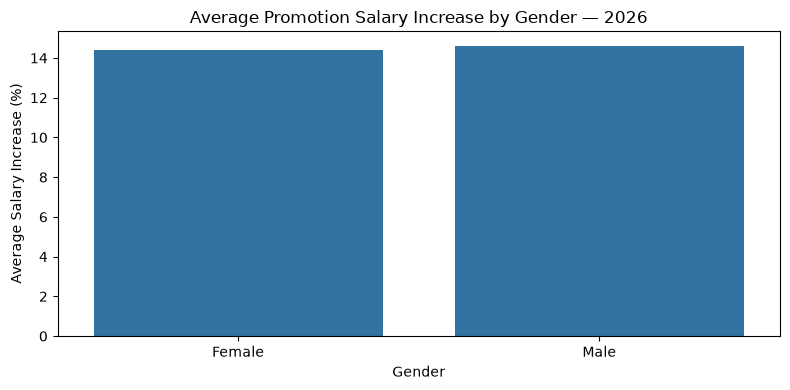

In [64]:

# Filter promotions for 2026
promotions_2026 = promotions[
    promotions["Promotion_Date"].dt.year == 2026
].copy()

# Add employee gender
promotion_increases = promotions_2026[
    ["Employee_ID", "Salary_Increase_Pct"]
].merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

# Include male and female employees
promotion_increases = promotion_increases[
    promotion_increases["Gender"].isin(["Male", "Female"])
].copy()

# Summarize salary increases by gender
increase_summary = (
    promotion_increases.groupby("Gender")
    .agg(
        Promotion_Count=("Employee_ID", "count"),
        Avg_Salary_Increase=("Salary_Increase_Pct", "mean"),
        Median_Salary_Increase=("Salary_Increase_Pct", "median")
    )
    .reset_index()
)

display(increase_summary.round(2))

# Calculate male-female difference in percentage points
male_avg = increase_summary.loc[
    increase_summary["Gender"] == "Male",
    "Avg_Salary_Increase"
].iloc[0]

female_avg = increase_summary.loc[
    increase_summary["Gender"] == "Female",
    "Avg_Salary_Increase"
].iloc[0]

increase_gap = male_avg - female_avg

print("Promotions Analyzed:", len(promotion_increases))
print("Male Promotions:", (promotion_increases["Gender"] == "Male").sum())
print("Female Promotions:", (promotion_increases["Gender"] == "Female").sum())
print("Promotion Increase Gap (pp):", round(increase_gap, 2))

# Visualization
plt.figure(figsize=(8, 4))

sns.barplot(
    data=increase_summary,
    x="Gender",
    y="Avg_Salary_Increase"
)

plt.title("Average Promotion Salary Increase by Gender — 2026")
plt.xlabel("Gender")
plt.ylabel("Average Salary Increase (%)")

plt.tight_layout()
plt.show()


**Key Findings — Promotion Salary Increases (2026)**

- Male employees received an average promotion salary increase of **14.61%**, compared with **14.42%** for female employees.
- The difference was **0.19 percentage points**, indicating a relatively small difference in average promotion increases.
- Median increases were **14.90% for male employees** and **14.38% for female employees**.
- The findings suggest similar average percentage increases, although further comparisons by job level and department may provide additional context.

Gender,Job_Level,Female,Male,Increase_Gap_pp,Female_Count,Male_Count
0,2,13.81,14.42,0.61,92,102
1,3,14.11,14.18,0.07,109,102
2,4,14.68,14.54,-0.13,135,141
3,5,14.55,15.43,0.89,53,64
4,6,15.10,14.84,-0.26,72,87


Promotions Analyzed: 957
Missing Job Levels: 0
Job Levels Analyzed: 5


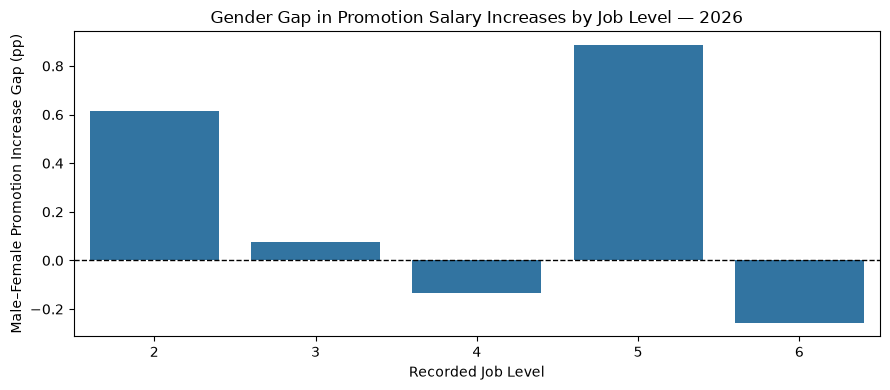

In [65]:

# Filter 2026 promotions
promotions_2026 = promotions[
    promotions["Promotion_Date"].dt.year == 2026
].copy()

# Add employee gender and job information
level_increases = promotions_2026[
    ["Employee_ID", "Salary_Increase_Pct"]
].merge(
    employees[["Employee_ID", "Gender", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

level_increases = level_increases.merge(
    jobs[["Job_ID", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Include male and female employees
level_increases = level_increases[
    level_increases["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average increase and promotion counts
level_summary = (
    level_increases.groupby(["Job_Level", "Gender"])
    .agg(
        Avg_Salary_Increase=("Salary_Increase_Pct", "mean"),
        Promotion_Count=("Employee_ID", "count")
    )
    .reset_index()
)

# Pivot average increases
increase_pivot = level_summary.pivot(
    index="Job_Level",
    columns="Gender",
    values="Avg_Salary_Increase"
)

# Pivot promotion counts
count_pivot = level_summary.pivot(
    index="Job_Level",
    columns="Gender",
    values="Promotion_Count"
)

# Calculate difference in percentage points
increase_pivot["Increase_Gap_pp"] = (
    increase_pivot["Male"] - increase_pivot["Female"]
)

increase_pivot["Female_Count"] = count_pivot["Female"]
increase_pivot["Male_Count"] = count_pivot["Male"]

level_increase_gap = (
    increase_pivot.reset_index()
    .sort_values("Job_Level")
)

display(level_increase_gap.round(2))

# Validation
print("Promotions Analyzed:", len(level_increases))
print("Missing Job Levels:", level_increases["Job_Level"].isna().sum())
print("Job Levels Analyzed:", level_increase_gap["Job_Level"].nunique())

# Visualization
plt.figure(figsize=(9, 4))

sns.barplot(
    data=level_increase_gap,
    x="Job_Level",
    y="Increase_Gap_pp"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Gender Gap in Promotion Salary Increases by Job Level — 2026")
plt.xlabel("Recorded Job Level")
plt.ylabel("Male–Female Promotion Increase Gap (pp)")

plt.tight_layout()
plt.show()


**Key Findings — Promotion Salary Increases by Job Level (2026)**

- **Job Level 5** has the largest positive gender difference in promotion salary increases at **0.89 percentage points**, followed by Level 2 at **0.61 percentage points**.
- **Job Levels 4 and 6** show negative differences of **−0.13 and −0.26 percentage points**, respectively, indicating slightly higher average increases for female employees.
- **Job Level 3** shows a minimal difference of **0.07 percentage points**.
- Overall, average promotion salary increases are relatively similar across genders within the same recorded job level. These descriptive differences do not establish whether promotion decisions or awards were equitable.

Gender,Department,Female,Male,Increase_Gap_pp,Female_Count,Male_Count
7,Operations,13.51,15.65,2.15,26,26
8,Product,13.85,15.03,1.18,51,52
11,Technology,14.40,15.06,0.66,57,66
3,Human Resources,13.21,13.72,0.51,18,21
9,Sales,14.56,15.06,0.50,27,35
0,Analytics,14.24,14.62,0.38,38,35
2,Finance,14.23,14.04,-0.19,48,46
4,Leadership,15.10,14.84,-0.26,72,87
6,Marketing,14.34,13.95,-0.39,25,35
10,Supply Chain,14.34,13.86,-0.48,37,30


Promotions Analyzed: 957
Missing Departments: 0
Departments Compared: 12


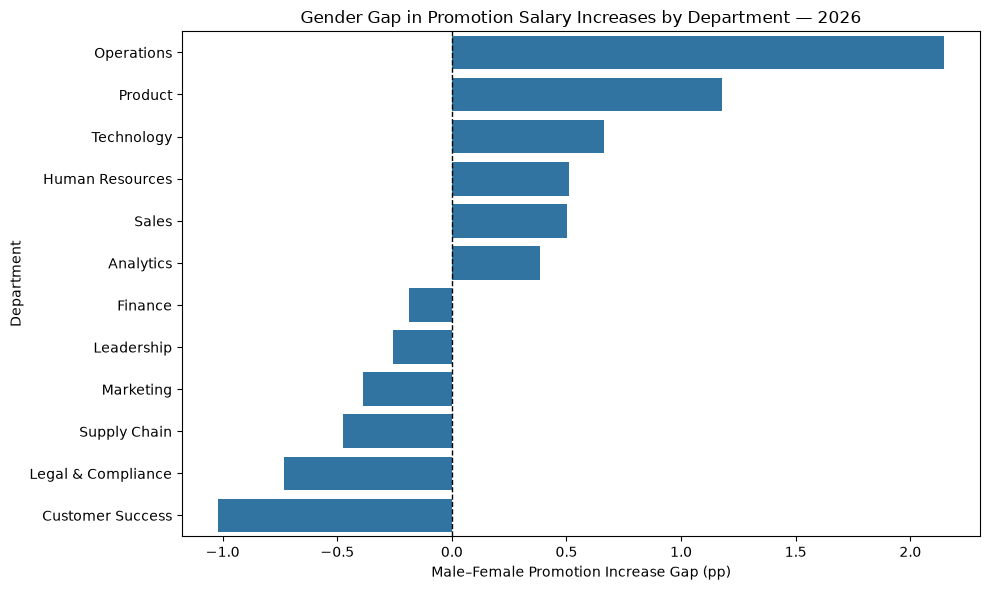

In [66]:

# Filter promotions for 2026
promotions_2026 = promotions[
    promotions["Promotion_Date"].dt.year == 2026
].copy()

# Add gender and department information
department_increases = promotions_2026[
    ["Employee_ID", "Salary_Increase_Pct"]
].merge(
    employees[["Employee_ID", "Gender", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

department_increases = department_increases.merge(
    jobs[["Job_ID", "Department"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Include male and female employees
department_increases = department_increases[
    department_increases["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average increases and counts
department_summary = (
    department_increases.groupby(["Department", "Gender"])
    .agg(
        Avg_Salary_Increase=("Salary_Increase_Pct", "mean"),
        Promotion_Count=("Employee_ID", "count")
    )
    .reset_index()
)

# Pivot average salary increases
increase_pivot = department_summary.pivot(
    index="Department",
    columns="Gender",
    values="Avg_Salary_Increase"
)

# Pivot promotion counts
count_pivot = department_summary.pivot(
    index="Department",
    columns="Gender",
    values="Promotion_Count"
)

# Keep departments with both male and female promotions
increase_pivot = increase_pivot.dropna(
    subset=["Male", "Female"]
)

# Calculate difference in percentage points
increase_pivot["Increase_Gap_pp"] = (
    increase_pivot["Male"] - increase_pivot["Female"]
)

increase_pivot["Female_Count"] = count_pivot["Female"]
increase_pivot["Male_Count"] = count_pivot["Male"]

department_increase_gap = (
    increase_pivot.reset_index()
    .sort_values("Increase_Gap_pp", ascending=False)
)

display(department_increase_gap.round(2))

# Validation
print("Promotions Analyzed:", len(department_increases))
print(
    "Missing Departments:",
    department_increases["Department"].isna().sum()
)
print(
    "Departments Compared:",
    len(department_increase_gap)
)

# Visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_increase_gap,
    x="Increase_Gap_pp",
    y="Department"
)

plt.axvline(
    0, color="black", linestyle="--", linewidth=1
)

plt.title(
    "Gender Gap in Promotion Salary Increases by Department — 2026"
)
plt.xlabel("Male–Female Promotion Increase Gap (pp)")
plt.ylabel("Department")

plt.tight_layout()
plt.show()


**Key Findings — Gender Gap in Promotion Salary Increases by Department (2026)**

- **Operations** recorded the largest positive gender difference at **2.15 percentage points**, with average promotion increases of 15.65% for male employees and 13.51% for female employees.
- **Product (1.18 pp)** and **Technology (0.66 pp)** also recorded higher average promotion increases for male employees.
- **Customer Success (−1.02 pp)** and **Legal & Compliance (−0.73 pp)** recorded the largest differences favoring female employees.
- All 12 departments had promotion records for both genders, allowing department-level comparisons.
- These are descriptive differences. Job level, experience, performance, and promotion counts should be considered before drawing conclusions about pay equity.

Year-over-Year Base Salary Growth (%)

Formula:

Salary Growth (%) = ((Current Year Salary − Previous Year Salary) / Previous Year Salary) × 100

Note: Only employees with compensation records in both consecutive years are included.

,Compensation_Year,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
0,2025,7539,4.32,3.85
1,2026,8766,3.86,3.46


Total Employee-Year Comparisons: 16305
Missing Growth Values: 0


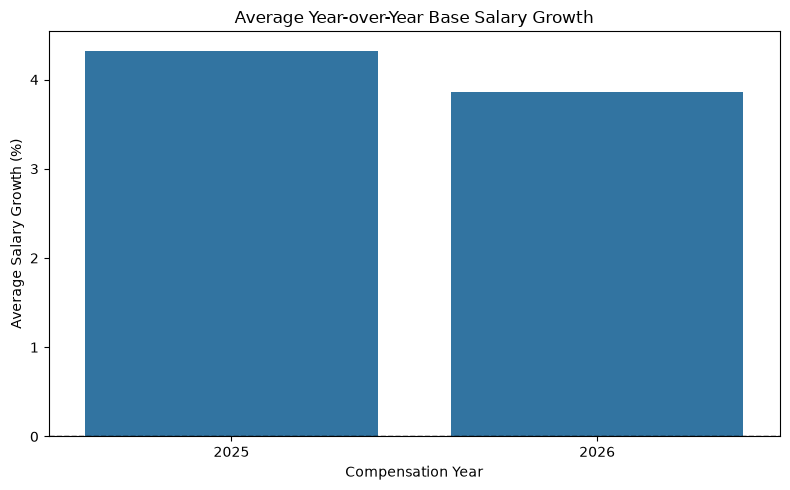

In [67]:

# Sort compensation records by employee and year
salary_growth = compensation[
    ["Employee_ID", "Compensation_Year", "Base_Salary"]
].copy()

salary_growth = salary_growth.sort_values(
    ["Employee_ID", "Compensation_Year"]
)

# Get previous compensation year and salary
salary_growth["Previous_Year"] = (
    salary_growth.groupby("Employee_ID")["Compensation_Year"]
    .shift(1)
)

salary_growth["Previous_Base_Salary"] = (
    salary_growth.groupby("Employee_ID")["Base_Salary"]
    .shift(1)
)

# Keep only consecutive-year comparisons
salary_growth = salary_growth[
    salary_growth["Compensation_Year"]
    - salary_growth["Previous_Year"] == 1
].copy()

# Calculate salary growth percentage
salary_growth["Salary_Growth_Pct"] = (
    (
        salary_growth["Base_Salary"]
        - salary_growth["Previous_Base_Salary"]
    )
    / salary_growth["Previous_Base_Salary"]
) * 100

# Summarize growth by year
yearly_salary_growth = (
    salary_growth.groupby("Compensation_Year")
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
)

display(yearly_salary_growth.round(2))

print("Total Employee-Year Comparisons:", len(salary_growth))
print("Missing Growth Values:",
      salary_growth["Salary_Growth_Pct"].isna().sum())

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=yearly_salary_growth,
    x="Compensation_Year",
    y="Avg_Salary_Growth"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Year-over-Year Base Salary Growth")
plt.xlabel("Compensation Year")
plt.ylabel("Average Salary Growth (%)")

plt.tight_layout()
plt.show()


**Key Findings — Year-over-Year Base Salary Growth**

- Average base salary growth decreased from **4.32% in 2025** to **3.86% in 2026**, a reduction of **0.46 percentage points**.
- Median salary growth declined from **3.85% to 3.46%**, indicating slower growth for the typical comparable employee.
- The analysis includes **16,305 consecutive employee-year comparisons**, with no missing growth values.
- These results measure salary changes for employees present in consecutive years, rather than changes in the overall workforce average.

Salary Change Distribution (%)

Formula:

Change Category Rate (%) = (Employees in Change Category / Total Comparable Employees) × 100

Note: Employees are classified as Increased, Decreased, or No Change based on their year-over-year base salary growth.

Salary Change Counts:


Salary_Change_Status,Increased,Decreased,No Change,Total_Employees
Compensation_Year,,,,
2025,5094,2445,0,7539
2026,5798,2968,0,8766


Salary Change Percentages:


Salary_Change_Status,Increased,Decreased,No Change
Compensation_Year,,,
2025,67.57,32.43,0.00
2026,66.14,33.86,0.00


Total Employee-Year Comparisons: 16305


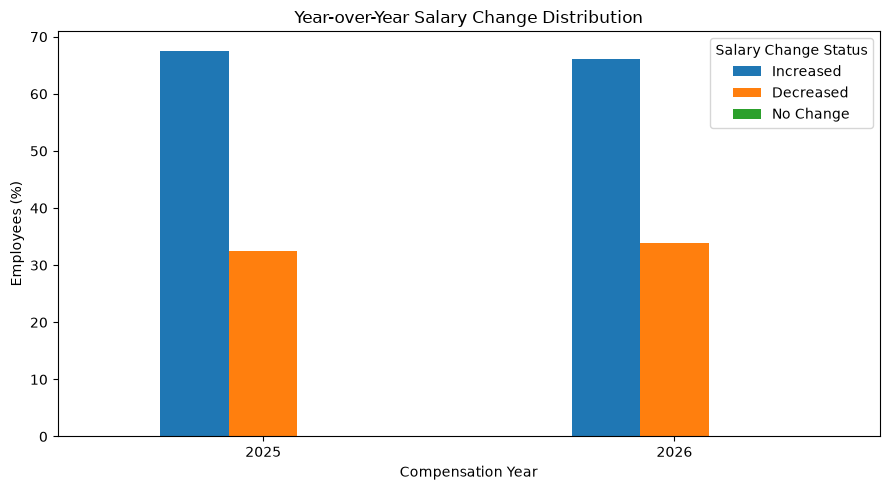

In [68]:

# Classify year-over-year salary changes
salary_growth["Salary_Change_Status"] = np.select(
    [
        salary_growth["Salary_Growth_Pct"] > 0,
        salary_growth["Salary_Growth_Pct"] < 0
    ],
    ["Increased", "Decreased"],
    default="No Change"
)

# Count employees by year and salary change status
salary_change_summary = (
    salary_growth.groupby(
        ["Compensation_Year", "Salary_Change_Status"]
    )["Employee_ID"]
    .nunique()
    .unstack(fill_value=0)
)

# Ensure consistent column order
salary_change_summary = salary_change_summary.reindex(
    columns=["Increased", "Decreased", "No Change"],
    fill_value=0
)

salary_change_summary["Total_Employees"] = (
    salary_change_summary[
        ["Increased", "Decreased", "No Change"]
    ].sum(axis=1)
)

# Calculate percentage distribution
salary_change_pct = (
    salary_change_summary[
        ["Increased", "Decreased", "No Change"]
    ]
    .div(salary_change_summary["Total_Employees"], axis=0)
    * 100
)

print("Salary Change Counts:")
display(salary_change_summary)

print("Salary Change Percentages:")
display(salary_change_pct.round(2))

print(
    "Total Employee-Year Comparisons:",
    salary_change_summary["Total_Employees"].sum()
)

# Visualization
ax = salary_change_pct.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Year-over-Year Salary Change Distribution")
plt.xlabel("Compensation Year")
plt.ylabel("Employees (%)")
plt.xticks(rotation=0)
plt.legend(title="Salary Change Status")
plt.tight_layout()
plt.show()


**Key Findings — Year-over-Year Salary Change Distribution**

- The percentage of employees receiving salary increases decreased from **67.57% in 2025 to 66.14% in 2026**, a decline of 1.43 percentage points.
- The percentage experiencing salary decreases increased from **32.43% to 33.86%**.
- No employees had unchanged base salaries in either comparison year.
- Although most comparable employees received salary increases, the proportion experiencing salary decreases rose slightly in 2026.

Employees Compared: 8766
Missing Job Levels: 0


,Job_Level,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
0,1,393,4.75,4.34
1,2,1673,3.77,3.54
2,3,1858,3.97,3.66
3,4,2542,4.05,3.62
4,5,948,3.35,2.57
5,6,1352,3.54,3.10


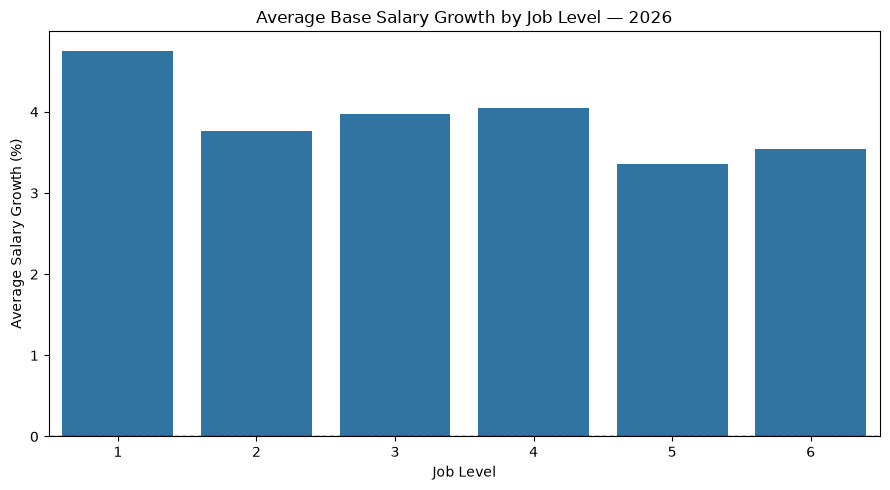

In [69]:

# Select 2026 salary growth records
growth_2026 = salary_growth[
    salary_growth["Compensation_Year"] == 2026
].copy()

# Add job information
growth_2026 = growth_2026.merge(
    employees[["Employee_ID", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

growth_2026 = growth_2026.merge(
    jobs[["Job_ID", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Summarize salary growth by job level
growth_by_level = (
    growth_2026.groupby("Job_Level")
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
    .sort_values("Job_Level")
)

print("Employees Compared:", len(growth_2026))
print("Missing Job Levels:", growth_2026["Job_Level"].isna().sum())

display(growth_by_level.round(2))

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=growth_by_level,
    x="Job_Level",
    y="Avg_Salary_Growth"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Base Salary Growth by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Average Salary Growth (%)")

plt.tight_layout()
plt.show()


**Key Findings — Average Salary Growth by Job Level (2026)**

- **Job Level 1** recorded the highest average base salary growth at **4.75%**, followed by Level 4 at **4.05%**.
- **Job Level 5** recorded the lowest average growth at **3.35%**, followed by Level 6 at **3.54%**.
- The difference between the highest and lowest average growth rates was **1.40 percentage points**.
- All six job levels recorded positive average salary growth, although individual employees may have experienced salary decreases.
- Salary growth varies by job level, suggesting that compensation progression should be examined alongside employee experience, performance, and promotion history.

Employees Compared: 8766
Missing Departments: 0
Departments Analyzed: 12


,Department,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
9,Sales,606,4.78,4.41
3,Human Resources,531,4.46,4.40
5,Legal & Compliance,611,4.29,3.39
2,Finance,674,4.03,3.53
11,Technology,1131,3.87,3.51
7,Operations,557,3.86,3.18
1,Customer Success,544,3.82,3.63
6,Marketing,591,3.74,3.21
0,Analytics,670,3.59,3.55
4,Leadership,1352,3.54,3.10


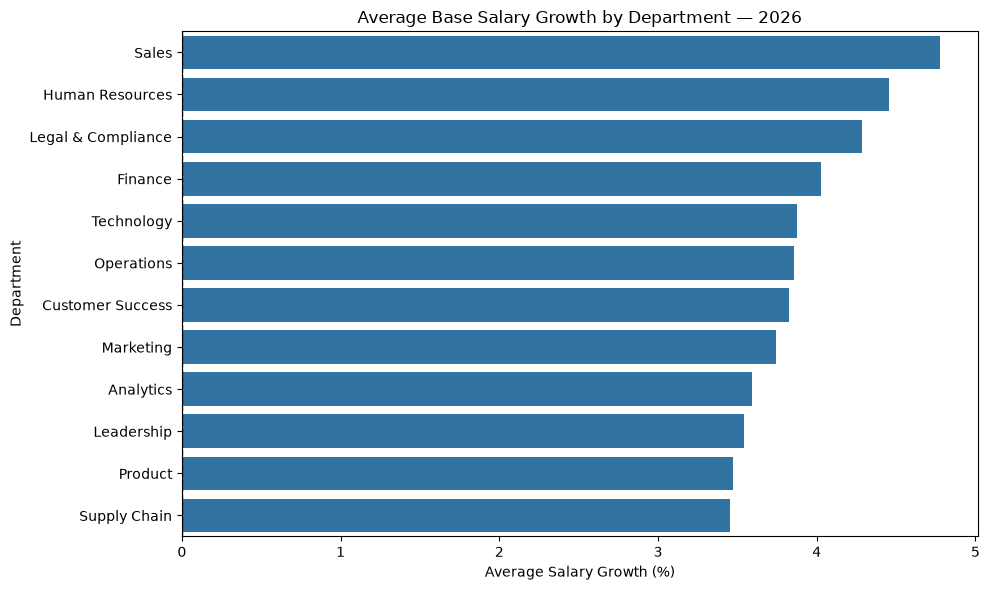

In [70]:

# Use the existing 2026 salary growth dataset
department_growth = growth_2026.merge(
    jobs[["Job_ID", "Department"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Calculate department-level salary growth
growth_by_department = (
    department_growth.groupby("Department")
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
    .sort_values("Avg_Salary_Growth", ascending=False)
)

print("Employees Compared:", len(department_growth))
print(
    "Missing Departments:",
    department_growth["Department"].isna().sum()
)
print(
    "Departments Analyzed:",
    growth_by_department["Department"].nunique()
)

display(growth_by_department.round(2))

# Visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    data=growth_by_department,
    x="Avg_Salary_Growth",
    y="Department"
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Base Salary Growth by Department — 2026")
plt.xlabel("Average Salary Growth (%)")
plt.ylabel("Department")

plt.tight_layout()
plt.show()


**Key Findings — Average Salary Growth by Department (2026)**

- **Sales** recorded the highest average base salary growth at **4.78%**, followed by **Human Resources (4.46%)** and **Legal & Compliance (4.29%)**.
- **Supply Chain (3.45%)**, **Product (3.47%)**, and **Leadership (3.54%)** recorded the lowest average growth rates.
- The difference between the highest and lowest departmental growth rates was **1.33 percentage points**.
- All 12 departments recorded positive average salary growth, although individual employees may have experienced salary decreases.
- Differences in salary growth may reflect variations in job levels, performance, promotions, and compensation policies.

Employees Compared: 8766
Missing Gender Values: 0


,Gender,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
2,Non-binary,94,4.11,3.67
1,Male,4496,3.95,3.58
0,Female,4176,3.75,3.33


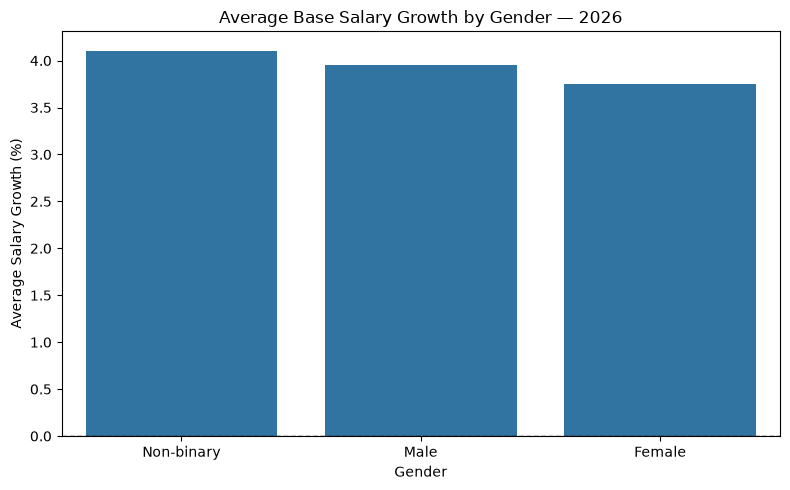

In [71]:

# Add employee gender to 2026 salary growth data
gender_growth = growth_2026.merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Calculate average and median salary growth by gender
growth_by_gender = (
    gender_growth.groupby("Gender")
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
    .sort_values("Avg_Salary_Growth", ascending=False)
)

print("Employees Compared:", len(gender_growth))
print("Missing Gender Values:", gender_growth["Gender"].isna().sum())

display(growth_by_gender.round(2))

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=growth_by_gender,
    x="Gender",
    y="Avg_Salary_Growth"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Base Salary Growth by Gender — 2026")
plt.xlabel("Gender")
plt.ylabel("Average Salary Growth (%)")

plt.tight_layout()
plt.show()


**Key Findings — Average Salary Growth by Gender (2026)**

- **Non-binary employees** recorded the highest average base salary growth at **4.11%**, followed by **male employees (3.95%)** and **female employees (3.75%)**.
- The male–female difference in average salary growth was **0.20 percentage points**, favoring male employees.
- Median salary growth was **3.67% for non-binary employees**, **3.58% for male employees**, and **3.33% for female employees**.
- All three groups recorded positive average salary growth.
- These are unadjusted comparisons. Differences in job level, department, experience, and performance may contribute to the observed variation. The non-binary group also has a smaller sample of 94 employees.

### Gender Gap in Salary Growth (Percentage Points)

Formula:

Growth Gap (pp) = Male Average Salary Growth (%) − Female Average Salary Growth (%)

Positive: Male employees received higher average salary growth.
Negative: Female employees received higher average salary growth.
Zero: Both groups recorded equal average salary growth.

Employees Analyzed: 8672
Missing Job Levels: 0


Gender,Job_Level,Female,Male,Growth_Gap_pp,Female_Count,Male_Count
0,1,4.43,4.87,0.44,184,206
1,2,3.60,3.92,0.32,794,862
2,3,4.09,3.82,-0.27,894,939
3,4,3.79,4.31,0.53,1208,1308
4,5,3.56,3.30,-0.26,450,489
5,6,3.32,3.69,0.37,646,692


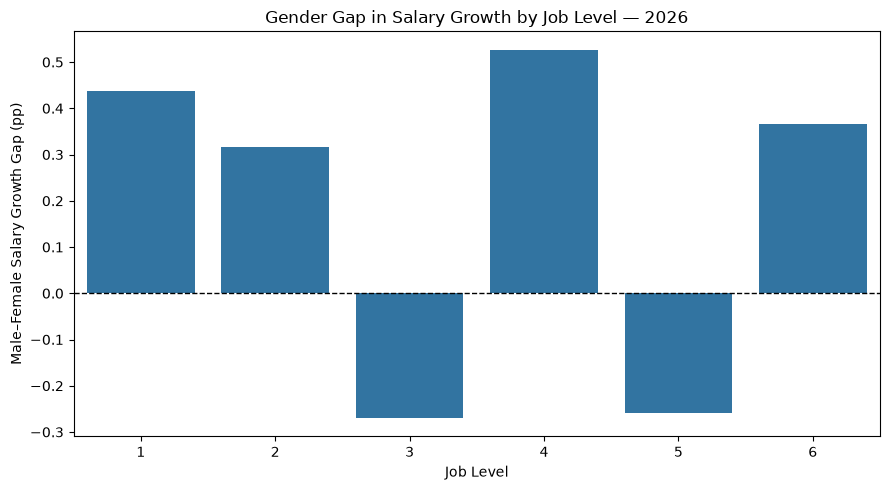

In [72]:

# Use the existing 2026 growth dataset with job levels
growth_level_gender = growth_2026.merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Focus on male and female employees
growth_level_gender = growth_level_gender[
    growth_level_gender["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average salary growth by job level and gender
growth_gap_level = (
    growth_level_gender.groupby(["Job_Level", "Gender"])
    ["Salary_Growth_Pct"]
    .mean()
    .unstack()
    .reset_index()
)

# Calculate percentage-point difference
growth_gap_level["Growth_Gap_pp"] = (
    growth_gap_level["Male"] - growth_gap_level["Female"]
)

# Add employee counts for context
gender_counts = (
    growth_level_gender.groupby(["Job_Level", "Gender"])
    ["Employee_ID"]
    .nunique()
    .unstack(fill_value=0)
    .rename(columns={
        "Female": "Female_Count",
        "Male": "Male_Count"
    })
    .reset_index()
)

growth_gap_level = growth_gap_level.merge(
    gender_counts,
    on="Job_Level",
    how="left"
)

print("Employees Analyzed:", len(growth_level_gender))
print("Missing Job Levels:",
      growth_level_gender["Job_Level"].isna().sum())

display(growth_gap_level.round(2))

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=growth_gap_level,
    x="Job_Level",
    y="Growth_Gap_pp"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Gender Gap in Salary Growth by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Male–Female Salary Growth Gap (pp)")

plt.tight_layout()
plt.show()


**Key Findings — Gender Gap in Salary Growth by Job Level (2026)**

- **Job Level 4** recorded the largest difference favoring male employees at **0.53 percentage points**, followed by Level 1 at **0.44 pp**.
- Male employees recorded higher average salary growth in **four of the six job levels**.
- Female employees recorded higher average growth at **Level 3 (0.27 pp)** and **Level 5 (0.26 pp)**.
- The differences ranged from **−0.27 pp to +0.53 pp**, indicating relatively small but varying gaps across job levels.
- These comparisons control for broad job level only. Differences in department, experience, performance, and promotions may still influence the results.

Employees Analyzed: 8672
Missing Departments: 0
Departments Compared: 12


Gender,Department,Female,Male,Growth_Gap_pp,Female_Count,Male_Count
2,Finance,3.05,4.93,1.89,328,336
6,Marketing,3.16,4.12,0.96,270,309
7,Operations,3.66,4.07,0.41,275,279
4,Leadership,3.32,3.69,0.37,646,692
3,Human Resources,4.29,4.51,0.22,220,305
11,Technology,3.84,3.95,0.12,543,577
10,Supply Chain,3.43,3.47,0.03,320,313
5,Legal & Compliance,4.33,4.23,-0.09,311,298
8,Product,3.56,3.45,-0.11,396,455
0,Analytics,3.69,3.38,-0.30,320,337


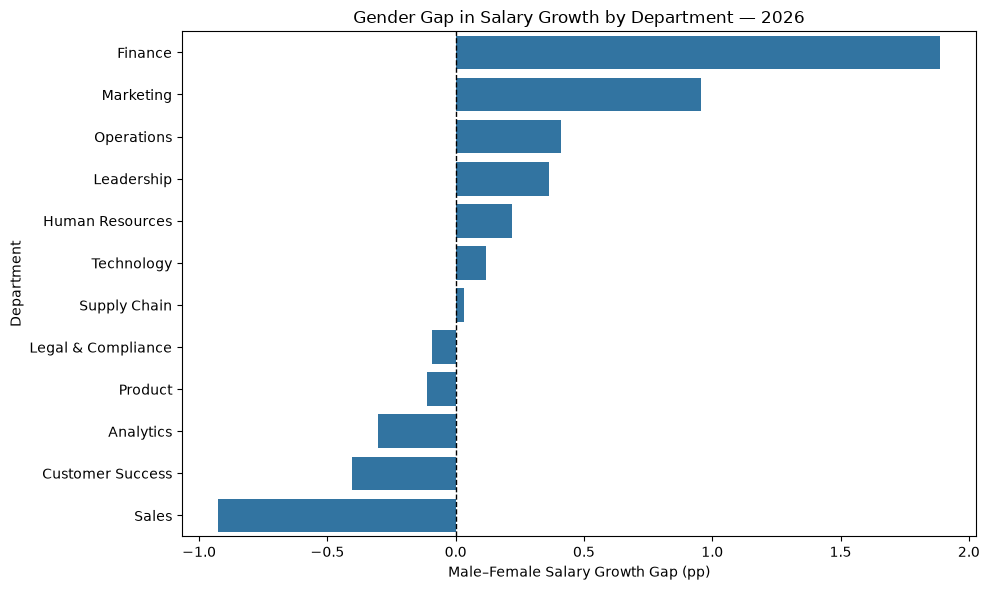

In [73]:

# Use the existing department growth dataset
growth_department_gender = department_growth.merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Focus on male and female employees
growth_department_gender = growth_department_gender[
    growth_department_gender["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average salary growth by department and gender
growth_gap_department = (
    growth_department_gender.groupby(["Department", "Gender"])
    ["Salary_Growth_Pct"]
    .mean()
    .unstack()
    .reset_index()
)

# Calculate male-female percentage-point difference
growth_gap_department["Growth_Gap_pp"] = (
    growth_gap_department["Male"]
    - growth_gap_department["Female"]
)

# Count employees in each group
department_gender_counts = (
    growth_department_gender.groupby(["Department", "Gender"])
    ["Employee_ID"]
    .nunique()
    .unstack(fill_value=0)
    .rename(columns={
        "Female": "Female_Count",
        "Male": "Male_Count"
    })
    .reset_index()
)

growth_gap_department = growth_gap_department.merge(
    department_gender_counts,
    on="Department",
    how="left"
)

growth_gap_department = growth_gap_department.sort_values(
    "Growth_Gap_pp",
    ascending=False
)

print("Employees Analyzed:", len(growth_department_gender))
print(
    "Missing Departments:",
    growth_department_gender["Department"].isna().sum()
)
print(
    "Departments Compared:",
    growth_gap_department["Department"].nunique()
)

display(growth_gap_department.round(2))

# Visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    data=growth_gap_department,
    x="Growth_Gap_pp",
    y="Department"
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)

plt.title("Gender Gap in Salary Growth by Department — 2026")
plt.xlabel("Male–Female Salary Growth Gap (pp)")
plt.ylabel("Department")

plt.tight_layout()
plt.show()


**Key Findings — Gender Gap in Salary Growth by Department (2026)**

- **Finance** recorded the largest salary growth difference favoring male employees at **1.89 percentage points**, followed by **Marketing (0.96 pp)**.
- **Sales** recorded the largest difference favoring female employees at **0.93 pp**, followed by **Customer Success (0.40 pp)** and **Analytics (0.30 pp)**.
- Male employees had higher average salary growth in **7 departments**, while female employees had higher growth in **5 departments**.
- **Supply Chain** recorded the smallest difference at approximately **0.03 pp**.
- These are unadjusted departmental comparisons. Job level, experience, performance, and promotions may contribute to the observed differences.

Employees Compared: 8766
Missing Performance Ratings: 0


,Performance_Rating,Performance_Category,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
0,1.00,Needs Improvement,363,-2.10,-2.51
1,2.00,Developing,995,0.92,0.53
2,3.00,Meets Expectations,4516,3.24,2.90
3,4.00,Exceeds Expectations,2355,6.14,5.80
4,5.00,Outstanding,537,8.52,8.24


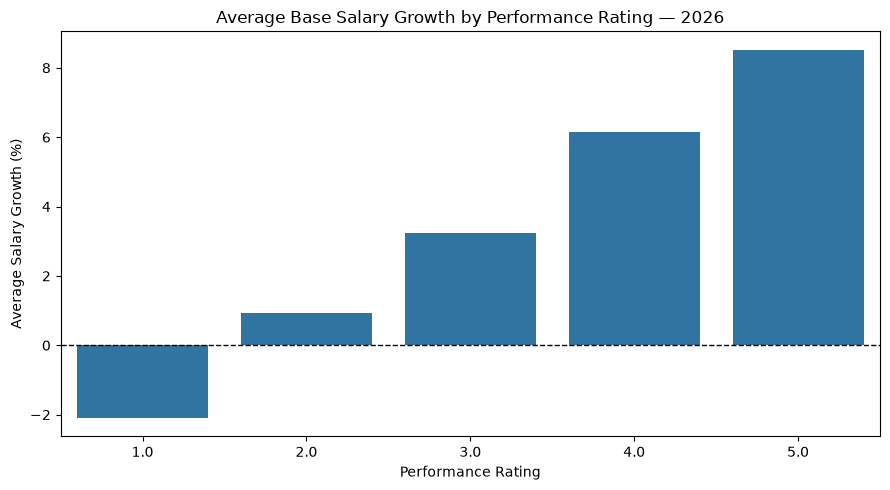

In [74]:

# Select 2026 performance records
performance_2026 = performance[
    performance["Review_Year"] == 2026
][
    ["Employee_ID", "Performance_Rating", "Performance_Category"]
].copy()

# Merge performance ratings with salary growth
performance_growth = growth_2026.merge(
    performance_2026,
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Summarize salary growth by performance rating
growth_by_performance = (
    performance_growth.groupby(
        ["Performance_Rating", "Performance_Category"]
    )
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
    .sort_values("Performance_Rating")
)

print("Employees Compared:", len(performance_growth))
print(
    "Missing Performance Ratings:",
    performance_growth["Performance_Rating"].isna().sum()
)

display(growth_by_performance.round(2))

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=growth_by_performance,
    x="Performance_Rating",
    y="Avg_Salary_Growth"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Base Salary Growth by Performance Rating — 2026")
plt.xlabel("Performance Rating")
plt.ylabel("Average Salary Growth (%)")

plt.tight_layout()
plt.show()


**Key Findings — Salary Growth by Performance Rating (2026)**

- Employees rated **Outstanding (5)** received the highest average base salary growth at **8.52%**, followed by **Exceeds Expectations (4)** at **6.14%**.
- Employees rated **Meets Expectations (3)** recorded average salary growth of **3.24%**.
- Employees rated **Developing (2)** received an average increase of **0.92%**, while those rated **Needs Improvement (1)** experienced an average salary reduction of **2.10%**.
- The difference between the highest and lowest performance groups was **10.62 percentage points**.
- Salary growth increases consistently across performance ratings, suggesting that compensation adjustments are strongly aligned with employee performance in this dataset.

Employees Compared: 8766
Promoted Employees Compared: 970


,Promotion_Status,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
0,Not Promoted,7796,3.89,3.46
1,Promoted,970,3.62,3.42


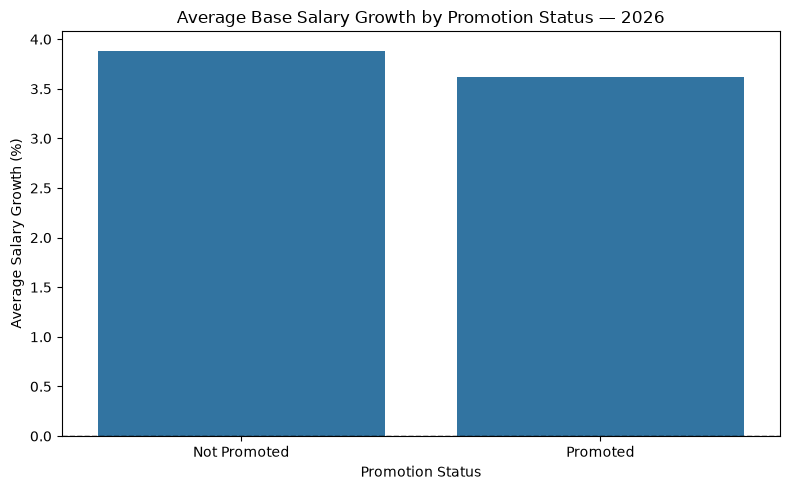

In [75]:

# Identify employees promoted in 2026
promoted_2026_ids = set(
    promotions.loc[
        promotions["Promotion_Date"].dt.year == 2026,
        "Employee_ID"
    ]
)

# Prepare salary growth data
promotion_growth = growth_2026.copy()

# Assign promotion status
promotion_growth["Promotion_Status"] = np.where(
    promotion_growth["Employee_ID"].isin(promoted_2026_ids),
    "Promoted",
    "Not Promoted"
)

# Calculate salary growth by promotion status
growth_by_promotion = (
    promotion_growth.groupby("Promotion_Status")
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
)

print("Employees Compared:", len(promotion_growth))
print(
    "Promoted Employees Compared:",
    (promotion_growth["Promotion_Status"] == "Promoted").sum()
)

display(growth_by_promotion.round(2))

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=growth_by_promotion,
    x="Promotion_Status",
    y="Avg_Salary_Growth",
    order=["Not Promoted", "Promoted"]
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Base Salary Growth by Promotion Status — 2026")
plt.xlabel("Promotion Status")
plt.ylabel("Average Salary Growth (%)")

plt.tight_layout()
plt.show()


**Key Findings — Salary Growth by Promotion Status (2026)**

- Employees who were **not promoted** recorded average base salary growth of **3.89%**, compared with **3.62%** among promoted employees.
- Non-promoted employees had a slightly higher average salary growth rate, with a difference of **0.27 percentage points**.
- Median salary growth was also similar: **3.46%** for non-promoted employees and **3.42%** for promoted employees.
- Promotion status alone does not explain salary growth differences in this dataset.
- **Important:** The year-over-year base salary growth metric and the promotion-related salary increase percentage are different measures. They should not be interpreted as equivalent.

**Business implication:** Further analysis should consider job level, performance ratings, and promotion-related adjustments before drawing conclusions about the impact of promotions on compensation.

Employees Compared: 8766
Missing Experience Values: 23


,Experience_Group,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
0,0-5 Years,1573,3.77,3.45
1,6-10 Years,2220,4.08,3.84
2,11-15 Years,2436,3.90,3.46
3,16-20 Years,1601,3.72,3.07
4,20+ Years,913,3.66,3.03


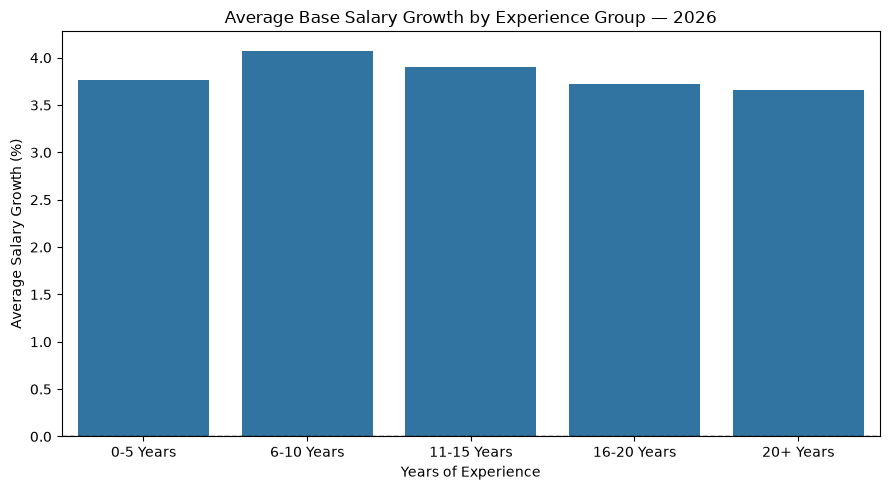

In [76]:

# Merge salary growth with employee experience
experience_growth = growth_2026.merge(
    employees[["Employee_ID", "Years_Experience"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

print("Employees Compared:", len(experience_growth))
print(
    "Missing Experience Values:",
    experience_growth["Years_Experience"].isna().sum()
)

# Exclude missing experience values
experience_growth = experience_growth.dropna(
    subset=["Years_Experience"]
).copy()

# Create experience groups
experience_growth["Experience_Group"] = pd.cut(
    experience_growth["Years_Experience"],
    bins=[-1, 5, 10, 15, 20, np.inf],
    labels=[
        "0-5 Years",
        "6-10 Years",
        "11-15 Years",
        "16-20 Years",
        "20+ Years"
    ]
)

# Calculate salary growth by experience group
growth_by_experience = (
    experience_growth.groupby(
        "Experience_Group",
        observed=True
    )
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
)

display(growth_by_experience.round(2))

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=growth_by_experience,
    x="Experience_Group",
    y="Avg_Salary_Growth"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Base Salary Growth by Experience Group — 2026")
plt.xlabel("Years of Experience")
plt.ylabel("Average Salary Growth (%)")

plt.tight_layout()
plt.show()


**Key Findings — Salary Growth by Experience Group (2026)**

- Employees with **6–10 years of experience** recorded the highest average base salary growth at **4.08%**.
- Employees with **11–15 years of experience** followed at **3.90%**, while those with **0–5 years** recorded **3.77%**.
- Employees with **20+ years of experience** experienced the lowest average growth at **3.66%**.
- The difference between the highest and lowest experience groups was **0.42 percentage points**.
- Salary growth varies moderately across experience groups and does not increase consistently with years of experience.
- **23 employees** with missing experience information were excluded from this analysis.

**Business implication:** Experience alone does not determine annual salary growth. Performance, job level, and compensation policies may also influence salary adjustments.

Employees Compared: 8766
Missing Locations: 0


,Location,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
0,Bengaluru,2465,4.07,3.57
3,Hyderabad,1459,3.93,3.67
4,Mumbai,1153,3.75,3.42
1,Chennai,1298,3.75,3.46
2,Gurugram,1048,3.73,3.12
5,Pune,1343,3.68,3.35


Locations Analyzed: 6


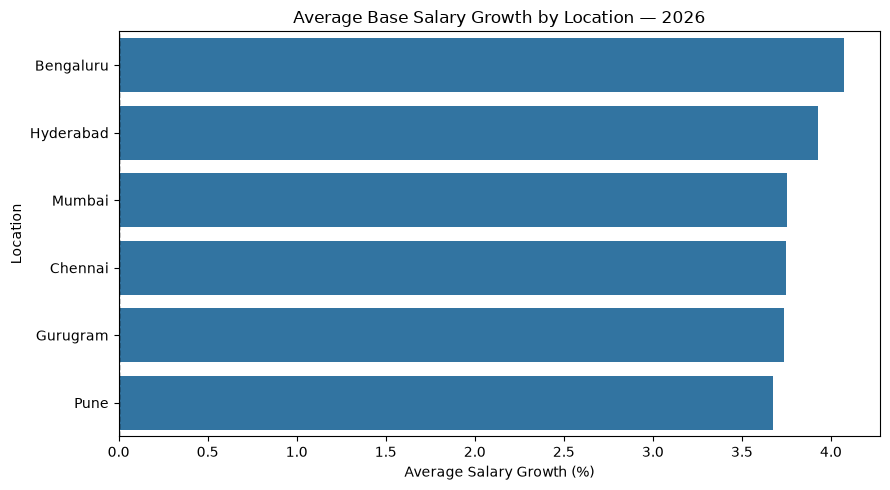

In [77]:

# Merge salary growth with employee location
location_growth = growth_2026.merge(
    employees[["Employee_ID", "Location"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

print("Employees Compared:", len(location_growth))
print(
    "Missing Locations:",
    location_growth["Location"].isna().sum()
)

# Calculate salary growth by location
growth_by_location = (
    location_growth.groupby("Location")
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
    .sort_values("Avg_Salary_Growth", ascending=False)
)

display(growth_by_location.round(2))

print("Locations Analyzed:", len(growth_by_location))

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=growth_by_location,
    x="Avg_Salary_Growth",
    y="Location"
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Base Salary Growth by Location — 2026")
plt.xlabel("Average Salary Growth (%)")
plt.ylabel("Location")

plt.tight_layout()
plt.show()


**Key Findings — Salary Growth by Location (2026)**

- **Bengaluru** recorded the highest average base salary growth at **4.07%**, followed by **Hyderabad (3.93%)**.
- **Mumbai and Chennai** both recorded average salary growth of approximately **3.75%**.
- **Pune** recorded the lowest average salary growth at **3.68%**, followed by **Gurugram (3.73%)**.
- The difference between the highest and lowest locations was **0.39 percentage points**, indicating relatively limited geographical variation.
- All six locations recorded positive average salary growth.

**Business implication:** Annual salary growth is relatively consistent across locations, although differences in employee performance, job levels, and workforce composition may contribute to the observed variation.

Employees Compared: 8766
Missing Employment Types: 0


,Employment_Type,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
1,Part-time,362,4.17,3.45
0,Full-time,8404,3.84,3.46


Employment Types Analyzed: 2


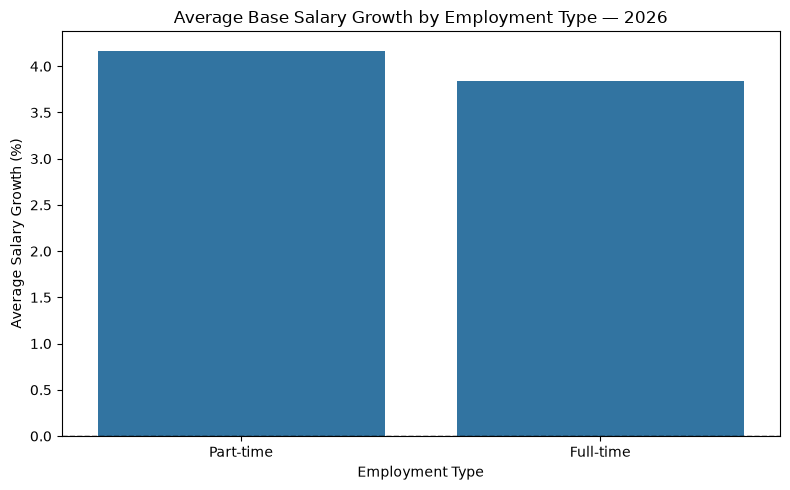

In [78]:

# Merge salary growth with employment type
employment_growth = growth_2026.merge(
    employees[["Employee_ID", "Employment_Type"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

print("Employees Compared:", len(employment_growth))
print(
    "Missing Employment Types:",
    employment_growth["Employment_Type"].isna().sum()
)

# Calculate salary growth by employment type
growth_by_employment = (
    employment_growth.groupby("Employment_Type")
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
    .sort_values("Avg_Salary_Growth", ascending=False)
)

display(growth_by_employment.round(2))

print("Employment Types Analyzed:", len(growth_by_employment))

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=growth_by_employment,
    x="Employment_Type",
    y="Avg_Salary_Growth"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Base Salary Growth by Employment Type — 2026")
plt.xlabel("Employment Type")
plt.ylabel("Average Salary Growth (%)")

plt.tight_layout()
plt.show()


**Key Findings — Salary Growth by Employment Type (2026)**

- **Part-time employees** recorded higher average base salary growth at **4.17%**, compared with **3.84%** for full-time employees.
- The difference in average salary growth was **0.33 percentage points**.
- Median salary growth was nearly identical: **3.45%** for part-time employees and **3.46%** for full-time employees.
- The analysis included **8,404 full-time employees** and **362 part-time employees**.
- The higher part-time average should be interpreted cautiously because the part-time employee group is considerably smaller.

**Business implication:** Average salary growth differs slightly by employment type, but similar median growth rates suggest that the typical employee experienced comparable salary adjustments.

Employees Compared: 8766
Missing Employment Status: 0


,Employment_Status,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
1,Exited,461,3.94,3.56
0,Active,8305,3.85,3.45


Employment Status Groups: 2


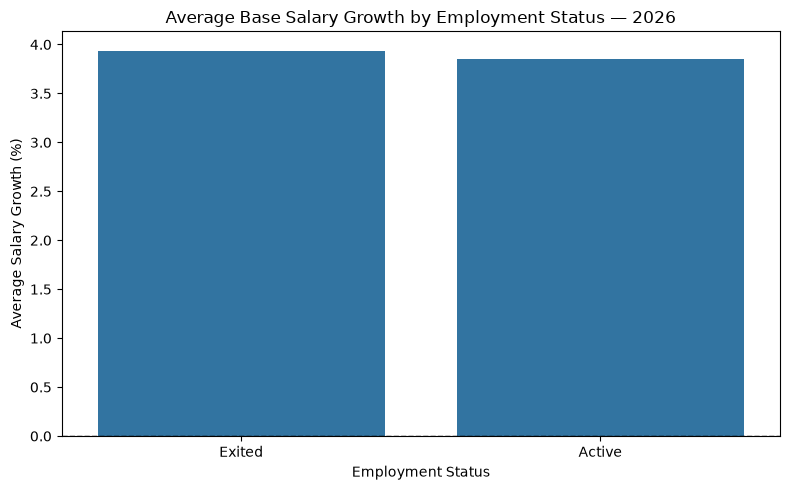

In [79]:

# Merge salary growth with employment status
status_growth = growth_2026.merge(
    employees[["Employee_ID", "Employment_Status"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

print("Employees Compared:", len(status_growth))
print(
    "Missing Employment Status:",
    status_growth["Employment_Status"].isna().sum()
)

# Calculate salary growth by employment status
growth_by_status = (
    status_growth.groupby("Employment_Status")
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
    .sort_values("Avg_Salary_Growth", ascending=False)
)

display(growth_by_status.round(2))

print("Employment Status Groups:", len(growth_by_status))

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=growth_by_status,
    x="Employment_Status",
    y="Avg_Salary_Growth"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Base Salary Growth by Employment Status — 2026")
plt.xlabel("Employment Status")
plt.ylabel("Average Salary Growth (%)")

plt.tight_layout()
plt.show()


**Key Findings — Salary Growth by Employment Status (2026)**

- **Exited employees** recorded slightly higher average base salary growth at **3.94%**, compared with **3.85%** for active employees.
- The difference in average salary growth was only **0.09 percentage points**.
- Median salary growth was **3.56%** for exited employees and **3.45%** for active employees.
- The analysis included **8,305 active employees** and **461 exited employees**.
- The small differences suggest that salary growth was broadly similar across the two employment status groups.

**Business implication:** Employment status does not show a substantial difference in average salary growth in this dataset. However, these results do not establish whether salary growth influenced employee exits.

### Salary Change Distribution (%) 

**Formula:**

Salary Change Percentage = (Employees in Salary Change Category / Total Employees in Performance Group) × 100

**Note:** Salary changes are classified as **Increased, Decreased, or No Change** based on year-over-year base salary growth.

Employees Compared: 8766
Missing Performance Ratings: 0


,Salary_Change_Status,Increased,Decreased,No Change,Total_Employees
Performance_Rating,Performance_Category,,,,
1.00,Needs Improvement,141,222,0,363
2.00,Developing,531,464,0,995
3.00,Meets Expectations,2895,1621,0,4516
4.00,Exceeds Expectations,1789,566,0,2355
5.00,Outstanding,442,95,0,537


,Salary_Change_Status,Increased,Decreased,No Change
Performance_Rating,Performance_Category,,,
1.00,Needs Improvement,38.84,61.16,0.00
2.00,Developing,53.37,46.63,0.00
3.00,Meets Expectations,64.11,35.89,0.00
4.00,Exceeds Expectations,75.97,24.03,0.00
5.00,Outstanding,82.31,17.69,0.00


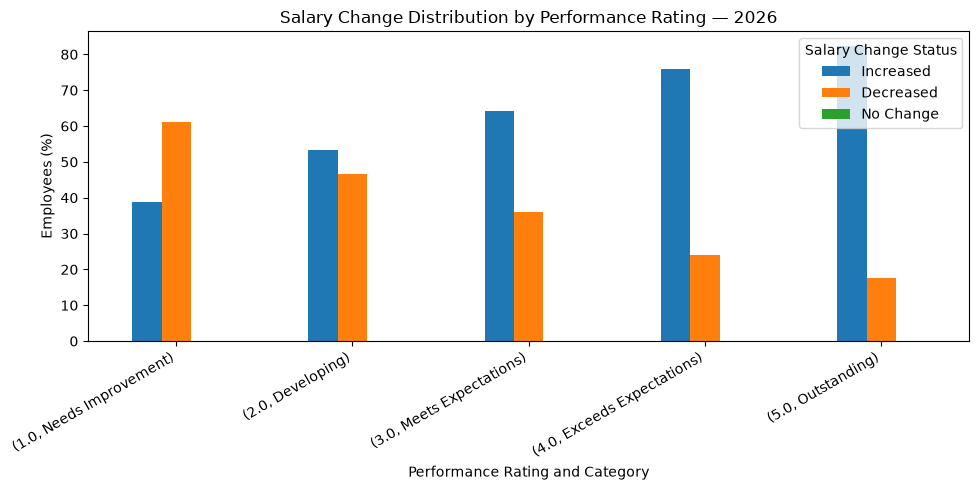

In [80]:

# Merge 2026 salary growth with performance ratings
performance_changes = growth_2026.merge(
    performance.loc[
        performance["Review_Year"] == 2026,
        ["Employee_ID", "Performance_Rating", "Performance_Category"]
    ],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

print("Employees Compared:", len(performance_changes))
print(
    "Missing Performance Ratings:",
    performance_changes["Performance_Rating"].isna().sum()
)

# Classify salary changes
performance_changes["Salary_Change_Status"] = np.select(
    [
        performance_changes["Salary_Growth_Pct"] > 0,
        performance_changes["Salary_Growth_Pct"] < 0
    ],
    ["Increased", "Decreased"],
    default="No Change"
)

# Count salary changes by performance rating
performance_change_counts = pd.crosstab(
    [
        performance_changes["Performance_Rating"],
        performance_changes["Performance_Category"]
    ],
    performance_changes["Salary_Change_Status"]
)

# Ensure all three categories are included
performance_change_counts = performance_change_counts.reindex(
    columns=["Increased", "Decreased", "No Change"],
    fill_value=0
)

performance_change_counts["Total_Employees"] = (
    performance_change_counts.sum(axis=1)
)

display(performance_change_counts)

# Calculate percentage distribution
performance_change_pct = (
    performance_change_counts[
        ["Increased", "Decreased", "No Change"]
    ]
    .div(performance_change_counts["Total_Employees"], axis=0)
    * 100
).round(2)

display(performance_change_pct)

# Visualization
performance_change_pct.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Salary Change Distribution by Performance Rating — 2026")
plt.xlabel("Performance Rating and Category")
plt.ylabel("Employees (%)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Salary Change Status")

plt.tight_layout()
plt.show()


**Key Findings — Salary Change Distribution by Performance Rating (2026)**

- Employees rated **Outstanding (5)** had the highest salary increase rate at **82.31%**, followed by **Exceeds Expectations (4)** at **75.97%**.
- Among employees rated **Meets Expectations (3)**, **64.11%** received salary increases, while **35.89%** experienced decreases.
- Employees rated **Needs Improvement (1)** had the highest salary decrease rate at **61.16%**.
- The percentage of employees receiving salary increases increased consistently with performance ratings, from **38.84%** at Rating 1 to **82.31%** at Rating 5.
- No employees recorded unchanged base salaries in the year-over-year comparison.

**Business implication:** Higher performance ratings are associated with a greater likelihood of receiving salary increases, suggesting a performance-linked compensation pattern. However, salary increases and decreases occur across all performance categories.

In [81]:

# Use existing job-level information
level_changes = growth_2026.copy()

# Check available columns
print("Total Employees:", len(level_changes))
print("Missing Job Levels:", level_changes["Job_Level"].isna().sum())
print("Duplicate Employee Records:",
      level_changes["Employee_ID"].duplicated().sum())

# Salary growth summary by job level
level_growth_summary = (
    level_changes.groupby("Job_Level")
    .agg(
        Employees_Compared=("Employee_ID", "nunique"),
        Avg_Salary_Growth=("Salary_Growth_Pct", "mean"),
        Median_Salary_Growth=("Salary_Growth_Pct", "median")
    )
    .reset_index()
    .round(2)
)

display(level_growth_summary)


Total Employees: 8766
Missing Job Levels: 0
Duplicate Employee Records: 0


,Job_Level,Employees_Compared,Avg_Salary_Growth,Median_Salary_Growth
0,1,393,4.75,4.34
1,2,1673,3.77,3.54
2,3,1858,3.97,3.66
3,4,2542,4.05,3.62
4,5,948,3.35,2.57
5,6,1352,3.54,3.10


Salary Change Counts:


Salary_Change_Status,Increased,Decreased,No Change
Job_Level,,,
1,273,120,0
2,1100,573,0
3,1236,622,0
4,1702,840,0
5,605,343,0
6,882,470,0


Salary Change Percentages:


Salary_Change_Status,Increased,Decreased,No Change
Job_Level,,,
1,69.47,30.53,0.00
2,65.75,34.25,0.00
3,66.52,33.48,0.00
4,66.96,33.04,0.00
5,63.82,36.18,0.00
6,65.24,34.76,0.00


Total Employees: 8766


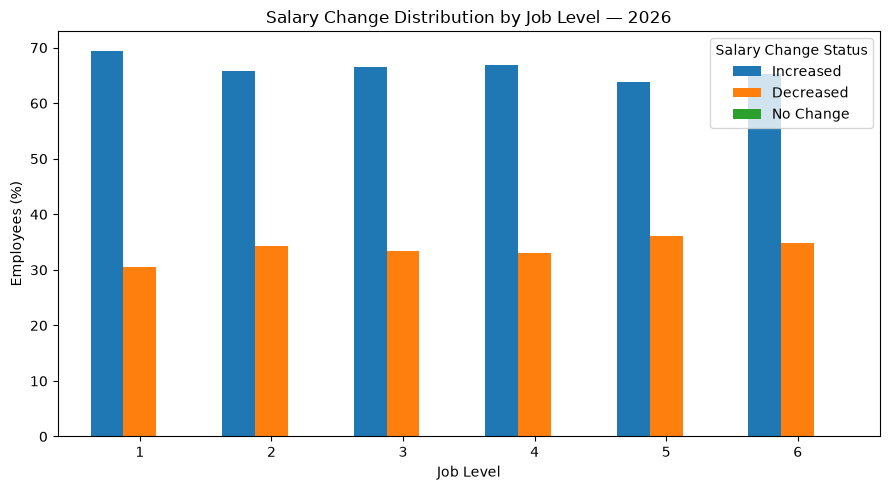

In [82]:

# Salary change distribution by job level
level_change_counts = pd.crosstab(
    level_changes["Job_Level"],
    level_changes["Salary_Change_Status"]
)

# Ensure all categories are present
level_change_counts = level_change_counts.reindex(
    columns=["Increased", "Decreased", "No Change"],
    fill_value=0
)

# Calculate percentages within each job level
level_change_pct = (
    level_change_counts.div(
        level_change_counts.sum(axis=1), axis=0
    ) * 100
).round(2)

print("Salary Change Counts:")
display(level_change_counts)

print("Salary Change Percentages:")
display(level_change_pct)

print("Total Employees:", level_change_counts.to_numpy().sum())

# Visualization
ax = level_change_pct.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75
)

plt.title("Salary Change Distribution by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Employees (%)")
plt.xticks(rotation=0)
plt.legend(title="Salary Change Status")
plt.tight_layout()
plt.show()


Employees Compared: 8766
Missing Departments: 0
Departments Analyzed: 12

Salary Change Counts:


Salary_Change_Status,Increased,Decreased,No Change
Department,,,
Analytics,433,237,0
Customer Success,360,184,0
Finance,460,214,0
Human Resources,361,170,0
Leadership,882,470,0
Legal & Compliance,402,209,0
Marketing,390,201,0
Operations,368,189,0
Product,552,308,0



Salary Change Percentages:


Salary_Change_Status,Increased,Decreased,No Change
Department,,,
Sales,69.31,30.69,0.00
Finance,68.25,31.75,0.00
Human Resources,67.98,32.02,0.00
Technology,67.02,32.98,0.00
Customer Success,66.18,33.82,0.00
Operations,66.07,33.93,0.00
Marketing,65.99,34.01,0.00
Legal & Compliance,65.79,34.21,0.00
Leadership,65.24,34.76,0.00


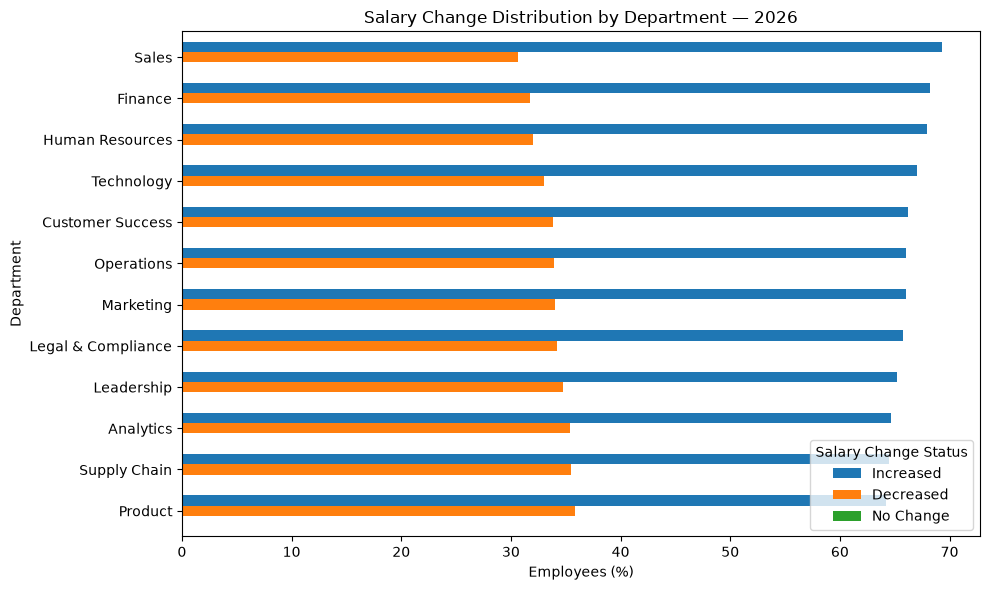

In [83]:

# Prepare employee department information
department_changes = growth_2026[
    ["Employee_ID", "Salary_Change_Status"]
].merge(
    employees[["Employee_ID", "Job_ID"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

department_changes = department_changes.merge(
    jobs[["Job_ID", "Department"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Count salary changes by department
department_change_counts = pd.crosstab(
    department_changes["Department"],
    department_changes["Salary_Change_Status"]
)

department_change_counts = department_change_counts.reindex(
    columns=["Increased", "Decreased", "No Change"],
    fill_value=0
)

# Calculate percentages
department_change_pct = (
    department_change_counts.div(
        department_change_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

# Sort by salary increase percentage
department_change_pct = department_change_pct.sort_values(
    "Increased", ascending=False
)

print("Employees Compared:", len(department_changes))
print("Missing Departments:",
      department_changes["Department"].isna().sum())
print("Departments Analyzed:", len(department_change_pct))

print("\nSalary Change Counts:")
display(department_change_counts)

print("\nSalary Change Percentages:")
display(department_change_pct)

# Visualization
department_change_pct.plot(
    kind="barh",
    figsize=(10, 6),
    width=0.75
)

plt.title("Salary Change Distribution by Department — 2026")
plt.xlabel("Employees (%)")
plt.ylabel("Department")
plt.legend(title="Salary Change Status")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


Employees Compared: 8766
Missing Gender Values: 0

Salary Change Counts:


Salary_Change_Status,Increased,Decreased,No Change
Gender,,,
Female,2759,1417,0
Male,2984,1512,0
Non-binary,55,39,0



Salary Change Percentages:


Salary_Change_Status,Increased,Decreased,No Change
Gender,,,
Female,66.07,33.93,0.00
Male,66.37,33.63,0.00
Non-binary,58.51,41.49,0.00


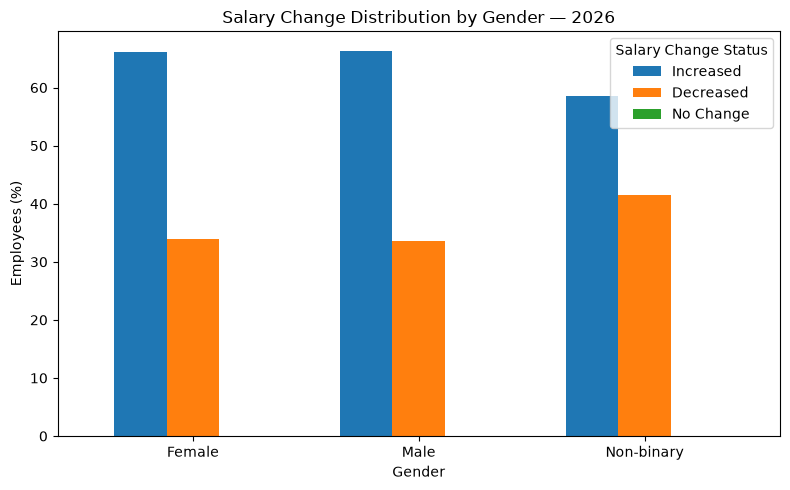

In [84]:

# Prepare gender and salary change data
gender_changes = growth_2026[
    ["Employee_ID", "Salary_Change_Status"]
].merge(
    employees[["Employee_ID", "Gender"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Count salary changes by gender
gender_change_counts = pd.crosstab(
    gender_changes["Gender"],
    gender_changes["Salary_Change_Status"]
)

gender_change_counts = gender_change_counts.reindex(
    columns=["Increased", "Decreased", "No Change"],
    fill_value=0
)

# Calculate percentages within each gender
gender_change_pct = (
    gender_change_counts.div(
        gender_change_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

print("Employees Compared:", len(gender_changes))
print("Missing Gender Values:",
      gender_changes["Gender"].isna().sum())

print("\nSalary Change Counts:")
display(gender_change_counts)

print("\nSalary Change Percentages:")
display(gender_change_pct)

# Visualization
gender_change_pct.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.7
)

plt.title("Salary Change Distribution by Gender — 2026")
plt.xlabel("Gender")
plt.ylabel("Employees (%)")
plt.xticks(rotation=0)
plt.legend(title="Salary Change Status")
plt.tight_layout()
plt.show()


### Key Findings — Salary Change Distribution by Gender (2026)

- Male employees had the highest salary increase rate at **66.37%**, followed closely by female employees at **66.07%**.
- The difference in salary increase rates between male and female employees was only **0.30 percentage points**.
- Non-binary employees had a lower salary increase rate of **58.51%**, compared with 66.37% for male employees and 66.07% for female employees.
- Salary increases were more common than decreases across all gender groups.
- These results are descriptive and do not establish whether salary decisions were equitable after accounting for job level, performance, experience, and other factors.

Employees Compared: 8766
Missing Experience Values: 23

Salary Change Counts:


Salary_Change_Status,Increased,Decreased,No Change
Experience_Group,,,
0-5 Years,1024,549,0
6-10 Years,1502,718,0
11-15 Years,1618,818,0
16-20 Years,1048,553,0
20+ Years,594,319,0



Salary Change Percentages:


Salary_Change_Status,Increased,Decreased,No Change
Experience_Group,,,
0-5 Years,65.10,34.90,0.00
6-10 Years,67.66,32.34,0.00
11-15 Years,66.42,33.58,0.00
16-20 Years,65.46,34.54,0.00
20+ Years,65.06,34.94,0.00


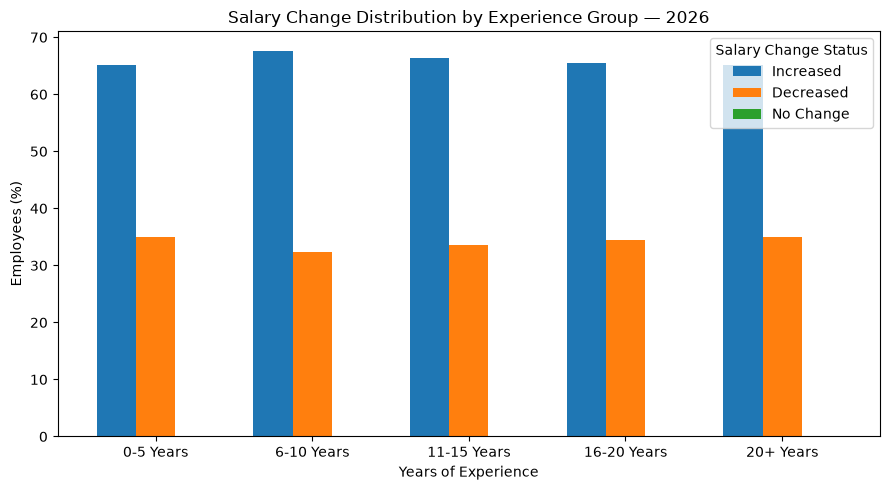

In [85]:

# Prepare salary change data with experience
experience_changes = growth_2026[
    ["Employee_ID", "Salary_Change_Status"]
].merge(
    employees[["Employee_ID", "Years_Experience"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Create experience groups
experience_changes["Experience_Group"] = pd.cut(
    experience_changes["Years_Experience"],
    bins=[-0.01, 5, 10, 15, 20, float("inf")],
    labels=[
        "0-5 Years",
        "6-10 Years",
        "11-15 Years",
        "16-20 Years",
        "20+ Years"
    ],
    include_lowest=True
)

# Count salary changes
experience_change_counts = pd.crosstab(
    experience_changes["Experience_Group"],
    experience_changes["Salary_Change_Status"]
)

experience_change_counts = experience_change_counts.reindex(
    columns=["Increased", "Decreased", "No Change"],
    fill_value=0
)

# Calculate percentages
experience_change_pct = (
    experience_change_counts.div(
        experience_change_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

print("Employees Compared:", len(experience_changes))
print("Missing Experience Values:",
      experience_changes["Years_Experience"].isna().sum())

print("\nSalary Change Counts:")
display(experience_change_counts)

print("\nSalary Change Percentages:")
display(experience_change_pct)

# Visualization
experience_change_pct.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75
)

plt.title("Salary Change Distribution by Experience Group — 2026")
plt.xlabel("Years of Experience")
plt.ylabel("Employees (%)")
plt.xticks(rotation=0)
plt.legend(title="Salary Change Status")
plt.tight_layout()
plt.show()


### Key Findings — Salary Change Distribution by Experience Group (2026)

- Employees with **6–10 years of experience** had the highest salary increase rate at **67.66%**.
- Employees with **20+ years of experience** had the lowest increase rate at **65.06%**, closely followed by those with 0–5 years at 65.10%.
- Salary increase rates ranged from **65.06% to 67.66%**, a difference of 2.60 percentage points.
- Salary increases were more common than decreases across all five experience groups.
- **23 employees** with missing experience information were excluded from the experience-group comparison.

Employees Compared: 8766
Missing Locations: 0
Locations Analyzed: 6

Salary Change Counts:


Salary_Change_Status,Increased,Decreased,No Change
Location,,,
Bengaluru,1668,797,0
Chennai,857,441,0
Gurugram,688,360,0
Hyderabad,962,497,0
Mumbai,755,398,0
Pune,868,475,0



Salary Change Percentages:


Salary_Change_Status,Increased,Decreased,No Change
Location,,,
Bengaluru,67.67,32.33,0.00
Chennai,66.02,33.98,0.00
Hyderabad,65.94,34.06,0.00
Gurugram,65.65,34.35,0.00
Mumbai,65.48,34.52,0.00
Pune,64.63,35.37,0.00


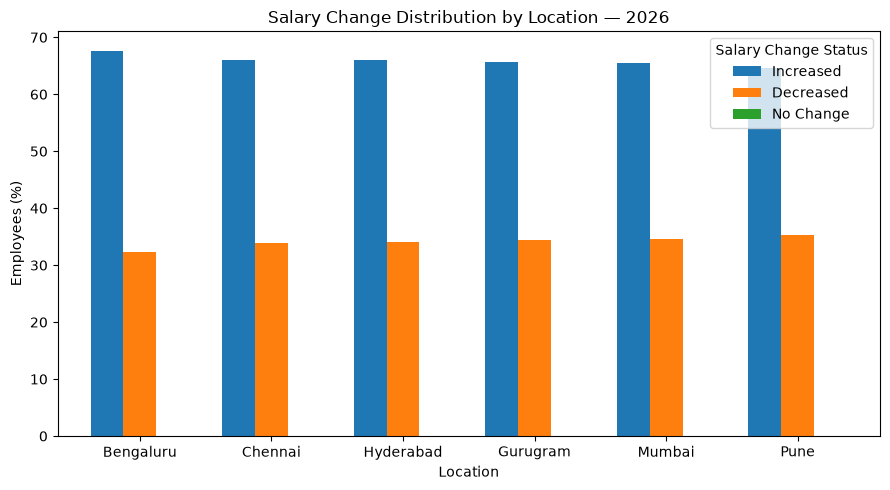

In [86]:

# Prepare salary change data with location
location_changes = growth_2026[
    ["Employee_ID", "Salary_Change_Status"]
].merge(
    employees[["Employee_ID", "Location"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Count salary changes by location
location_change_counts = pd.crosstab(
    location_changes["Location"],
    location_changes["Salary_Change_Status"]
)

location_change_counts = location_change_counts.reindex(
    columns=["Increased", "Decreased", "No Change"],
    fill_value=0
)

# Calculate percentages
location_change_pct = (
    location_change_counts.div(
        location_change_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

# Sort by salary increase percentage
location_change_pct = location_change_pct.sort_values(
    "Increased",
    ascending=False
)

print("Employees Compared:", len(location_changes))
print("Missing Locations:",
      location_changes["Location"].isna().sum())
print("Locations Analyzed:", len(location_change_pct))

print("\nSalary Change Counts:")
display(location_change_counts)

print("\nSalary Change Percentages:")
display(location_change_pct)

# Visualization
location_change_pct.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75
)

plt.title("Salary Change Distribution by Location — 2026")
plt.xlabel("Location")
plt.ylabel("Employees (%)")
plt.xticks(rotation=0)
plt.legend(title="Salary Change Status")
plt.tight_layout()
plt.show()


### Key Findings — Salary Change Distribution by Location (2026)

- **Bengaluru** had the highest salary increase rate at **67.67%**, covering 1,668 employees.
- **Pune** had the lowest salary increase rate at **64.63%** and the highest salary decrease rate at **35.37%**.
- The difference between the highest and lowest salary increase rates was **3.04 percentage points**.
- Salary increases were more common than decreases across all six locations.
- These differences are descriptive and may reflect variations in employee performance, job levels, or workforce composition.

Employees Compared: 8766
Missing Employment Types: 0
Employment Types Analyzed: 2

Salary Change Counts:


Salary_Change_Status,Increased,Decreased,No Change
Employment_Type,,,
Full-time,5556,2848,0
Part-time,242,120,0



Salary Change Percentages:


Salary_Change_Status,Increased,Decreased,No Change
Employment_Type,,,
Full-time,66.11,33.89,0.00
Part-time,66.85,33.15,0.00


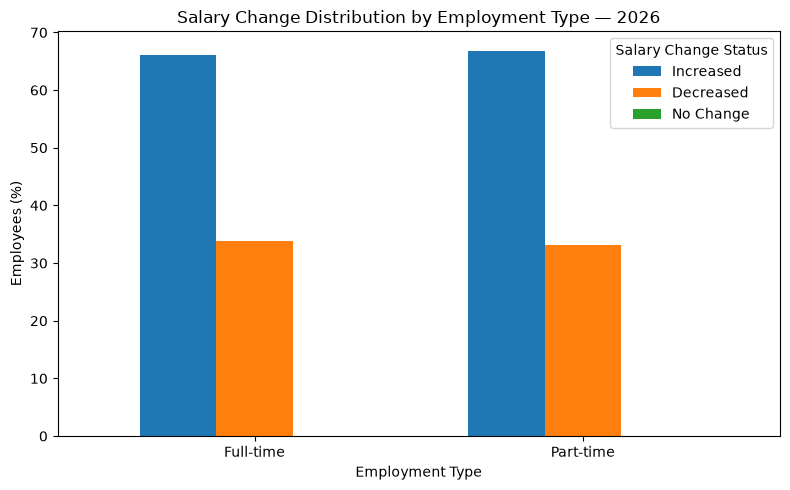

In [87]:

# Prepare salary change data with employment type
employment_type_changes = growth_2026[
    ["Employee_ID", "Salary_Change_Status"]
].merge(
    employees[["Employee_ID", "Employment_Type"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Count salary changes by employment type
employment_type_counts = pd.crosstab(
    employment_type_changes["Employment_Type"],
    employment_type_changes["Salary_Change_Status"]
)

employment_type_counts = employment_type_counts.reindex(
    columns=["Increased", "Decreased", "No Change"],
    fill_value=0
)

# Calculate percentages within each employment type
employment_type_pct = (
    employment_type_counts.div(
        employment_type_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

print("Employees Compared:", len(employment_type_changes))
print("Missing Employment Types:",
      employment_type_changes["Employment_Type"].isna().sum())
print("Employment Types Analyzed:", len(employment_type_pct))

print("\nSalary Change Counts:")
display(employment_type_counts)

print("\nSalary Change Percentages:")
display(employment_type_pct)

# Visualization
employment_type_pct.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.7
)

plt.title("Salary Change Distribution by Employment Type — 2026")
plt.xlabel("Employment Type")
plt.ylabel("Employees (%)")
plt.xticks(rotation=0)
plt.legend(title="Salary Change Status")
plt.tight_layout()
plt.show()


### Key Findings — Salary Change Distribution by Employment Type (2026)

- **Part-time employees** had a slightly higher salary increase rate (**66.85%**) than full-time employees (**66.11%**).
- The difference in salary increase rates was only **0.74 percentage points**.
- Salary increases were more common than decreases in both employment groups.
- The difference is descriptive and does not establish a meaningful employment-type effect without further analysis.

Employees Compared: 8766
Missing Employment Status: 0
Employment Status Groups: 2

Salary Change Counts:


Salary_Change_Status,Increased,Decreased,No Change
Employment_Status,,,
Active,5485,2820,0
Exited,313,148,0



Salary Change Percentages:


Salary_Change_Status,Increased,Decreased,No Change
Employment_Status,,,
Active,66.04,33.96,0.00
Exited,67.90,32.10,0.00


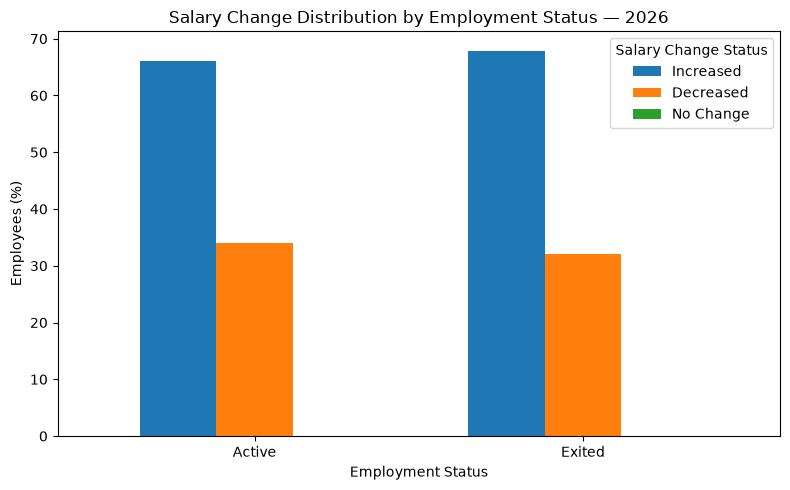

In [88]:

# Prepare salary change data with employment status
employment_status_changes = growth_2026[
    ["Employee_ID", "Salary_Change_Status"]
].merge(
    employees[["Employee_ID", "Employment_Status"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Count salary changes by employment status
employment_status_counts = pd.crosstab(
    employment_status_changes["Employment_Status"],
    employment_status_changes["Salary_Change_Status"]
)

employment_status_counts = employment_status_counts.reindex(
    columns=["Increased", "Decreased", "No Change"],
    fill_value=0
)

# Calculate percentages
employment_status_pct = (
    employment_status_counts.div(
        employment_status_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

print("Employees Compared:", len(employment_status_changes))
print("Missing Employment Status:",
      employment_status_changes["Employment_Status"].isna().sum())
print("Employment Status Groups:", len(employment_status_pct))

print("\nSalary Change Counts:")
display(employment_status_counts)

print("\nSalary Change Percentages:")
display(employment_status_pct)

# Visualization
employment_status_pct.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.7
)

plt.title("Salary Change Distribution by Employment Status — 2026")
plt.xlabel("Employment Status")
plt.ylabel("Employees (%)")
plt.xticks(rotation=0)
plt.legend(title="Salary Change Status")
plt.tight_layout()
plt.show()


### Key Findings — Salary Change Distribution by Employment Status (2026)

- **Exited employees** had a salary increase rate of **67.90%**, compared with **66.04%** for active employees.
- The difference in salary increase rates was **1.86 percentage points**.
- Salary decreases affected **33.96%** of active employees and **32.10%** of exited employees.
- Salary increases were more common than decreases in both groups.
- These findings describe historical salary changes among employees classified by their recorded employment status; they do not establish whether salary changes influenced employee exits.

### Salary Growth Distribution and Outlier Detection

The Interquartile Range (IQR) method identifies unusually high or low salary growth values.

**Formulas:**

- IQR = Q3 − Q1
- Lower Bound = Q1 − 1.5 × IQR
- Upper Bound = Q3 + 1.5 × IQR

Where Q1 is the 25th percentile and Q3 is the 75th percentile of salary growth.

Employees with salary growth outside these bounds are flagged as statistical outliers. These values are not automatically errors and should not be removed without investigation.

Employees Analyzed: 8766
Average Salary Growth (%): 3.86
Median Salary Growth (%): 3.46
Minimum Salary Growth (%): -27.21
Maximum Salary Growth (%): 46.13

Q1: -2.22
Q3: 9.5
IQR: 11.72
Lower Bound: -19.8
Upper Bound: 27.09
Outlier Employees: 80
Outlier Rate (%): 0.91


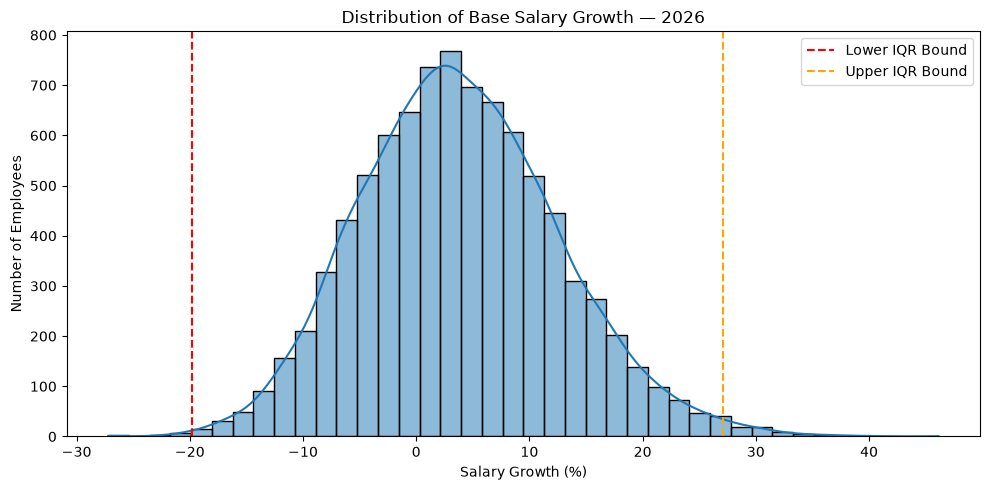

In [89]:

# Salary growth distribution and outlier analysis — 2026
salary_growth_values = growth_2026[
    "Salary_Growth_Pct"
].dropna()

# Summary statistics
print("Employees Analyzed:", len(salary_growth_values))
print("Average Salary Growth (%):",
      round(salary_growth_values.mean(), 2))
print("Median Salary Growth (%):",
      round(salary_growth_values.median(), 2))
print("Minimum Salary Growth (%):",
      round(salary_growth_values.min(), 2))
print("Maximum Salary Growth (%):",
      round(salary_growth_values.max(), 2))

# IQR outlier detection
q1 = salary_growth_values.quantile(0.25)
q3 = salary_growth_values.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (salary_growth_values < lower_bound) |
    (salary_growth_values > upper_bound)
)

outlier_count = outlier_mask.sum()
outlier_rate = outlier_count / len(salary_growth_values) * 100

print("\nQ1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("IQR:", round(iqr, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Outlier Employees:", outlier_count)
print("Outlier Rate (%):", round(outlier_rate, 2))

# Distribution chart
plt.figure(figsize=(10, 5))
sns.histplot(
    salary_growth_values,
    bins=40,
    kde=True
)

plt.axvline(
    lower_bound,
    color="red",
    linestyle="--",
    label="Lower IQR Bound"
)
plt.axvline(
    upper_bound,
    color="orange",
    linestyle="--",
    label="Upper IQR Bound"
)

plt.title("Distribution of Base Salary Growth — 2026")
plt.xlabel("Salary Growth (%)")
plt.ylabel("Number of Employees")
plt.legend()
plt.tight_layout()
plt.show()


### Key Findings — Salary Growth Distribution and Outlier Analysis (2026)

- The average year-over-year base salary growth was **3.86%**, while the median was **3.46%**.
- Individual salary growth ranged from **−27.21% to 46.13%**, indicating substantial variation in salary adjustments.
- The middle 50% of employees had salary growth between approximately **−2.22% and 9.50%**.
- Using the IQR method, **80 employees (0.91%)** were identified as salary growth outliers.
- These outliers warrant further investigation but should not automatically be treated as data errors or excluded from the analysis.

Employees Analyzed: 8766
Missing Departments: 0
Total Outliers: 80


,Department,Employees_Analyzed,Outlier_Employees,Outlier_Rate
6,Marketing,591,11,1.86
2,Finance,674,9,1.34
8,Product,860,9,1.05
3,Human Resources,531,5,0.94
4,Leadership,1352,12,0.89
9,Sales,606,5,0.83
5,Legal & Compliance,611,5,0.82
11,Technology,1131,9,0.80
1,Customer Success,544,4,0.74
7,Operations,557,4,0.72


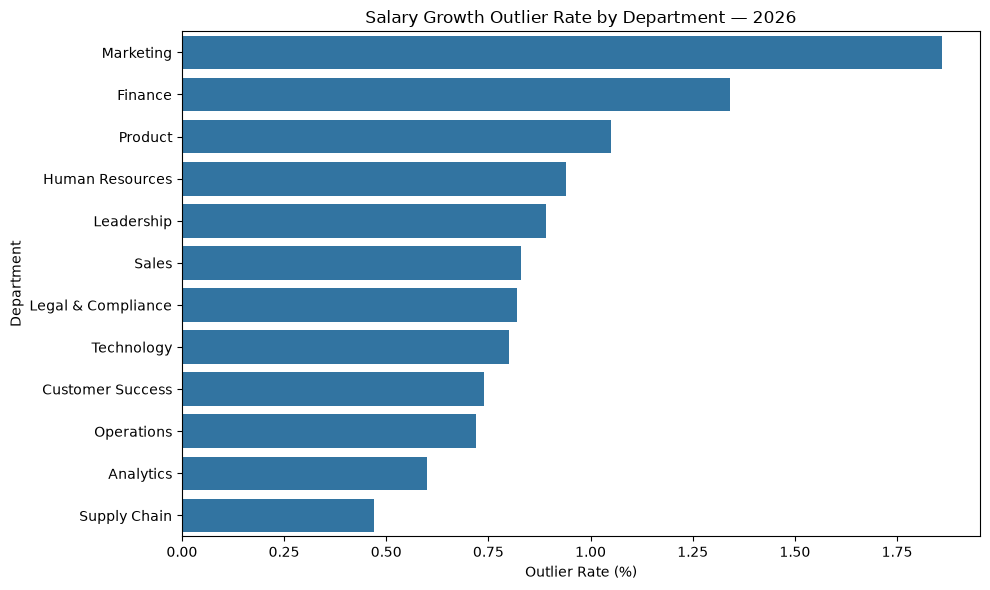

In [90]:

# Salary growth outliers by department — 2026

# Use the existing 2026 salary growth dataset
outlier_analysis = growth_2026.copy()

# Add department only if it is not already available
if "Department" not in outlier_analysis.columns:
    outlier_analysis = outlier_analysis.merge(
        jobs[["Job_ID", "Department"]],
        on="Job_ID",
        how="left",
        validate="many_to_one"
    )

# Flag salary growth outliers using Step 88 IQR bounds
outlier_analysis["Is_Outlier"] = (
    (outlier_analysis["Salary_Growth_Pct"] < lower_bound) |
    (outlier_analysis["Salary_Growth_Pct"] > upper_bound)
)

# Department-level outlier summary
department_outliers = (
    outlier_analysis
    .groupby("Department")
    .agg(
        Employees_Analyzed=("Employee_ID", "count"),
        Outlier_Employees=("Is_Outlier", "sum")
    )
    .reset_index()
)

department_outliers["Outlier_Rate"] = (
    department_outliers["Outlier_Employees"] /
    department_outliers["Employees_Analyzed"] * 100
).round(2)

department_outliers = department_outliers.sort_values(
    "Outlier_Rate", ascending=False
)

print("Employees Analyzed:", len(outlier_analysis))
print("Missing Departments:",
      outlier_analysis["Department"].isna().sum())
print("Total Outliers:",
      department_outliers["Outlier_Employees"].sum())

display(department_outliers)

# Visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_outliers,
    x="Outlier_Rate",
    y="Department"
)

plt.title("Salary Growth Outlier Rate by Department — 2026")
plt.xlabel("Outlier Rate (%)")
plt.ylabel("Department")
plt.tight_layout()
plt.show()


### Key Findings — Salary Growth Outliers by Department (2026)

- **80 employees (0.91%)** were identified as salary growth outliers across 12 departments.
- **Marketing** recorded the highest outlier rate at **1.86%** (11 employees), followed by Finance at **1.34%** (9 employees).
- **Leadership** had the highest absolute number of outliers (**12 employees**), although its outlier rate was **0.89%**.
- **Supply Chain** recorded the lowest outlier rate at **0.47%** (3 employees).
- Departments with higher outlier rates may require further review of unusual salary adjustments. Outliers do not necessarily indicate errors or unfair compensation.

Employees Analyzed: 8766
Missing Job Levels: 0
Total Outliers: 80
Job Levels Analyzed: 6


,Job_Level,Employees_Analyzed,Outlier_Employees,Outlier_Rate
0,1,393,7,1.78
1,2,1673,10,0.60
2,3,1858,19,1.02
3,4,2542,24,0.94
4,5,948,8,0.84
5,6,1352,12,0.89


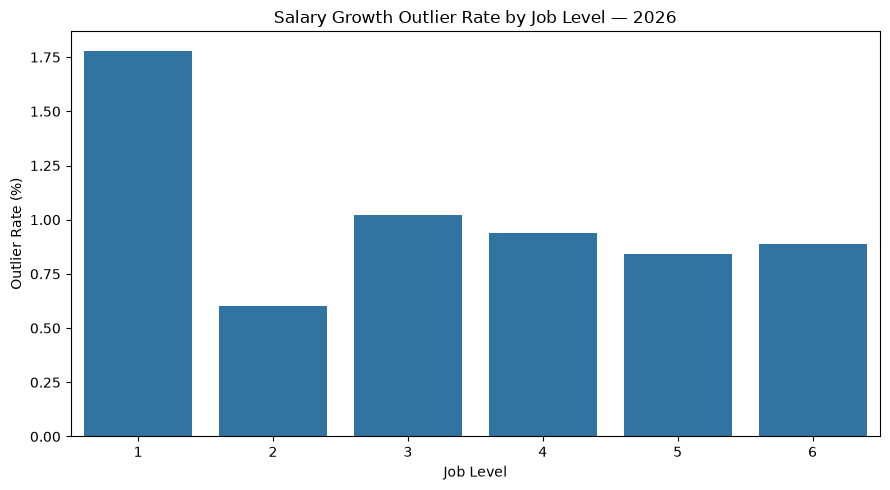

In [91]:

# Salary growth outliers by job level — 2026

level_outliers_data = outlier_analysis.copy()

# Add job level only if it is missing
if "Job_Level" not in level_outliers_data.columns:
    level_outliers_data = level_outliers_data.merge(
        jobs[["Job_ID", "Job_Level"]],
        on="Job_ID",
        how="left",
        validate="many_to_one"
    )

# Calculate outlier counts and rates by job level
level_outliers = (
    level_outliers_data
    .groupby("Job_Level")
    .agg(
        Employees_Analyzed=("Employee_ID", "count"),
        Outlier_Employees=("Is_Outlier", "sum")
    )
    .reset_index()
)

level_outliers["Outlier_Rate"] = (
    level_outliers["Outlier_Employees"] /
    level_outliers["Employees_Analyzed"] * 100
).round(2)

level_outliers = level_outliers.sort_values("Job_Level")

# Validation
print("Employees Analyzed:", len(level_outliers_data))
print("Missing Job Levels:",
      level_outliers_data["Job_Level"].isna().sum())
print("Total Outliers:",
      level_outliers["Outlier_Employees"].sum())
print("Job Levels Analyzed:", len(level_outliers))

display(level_outliers)

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=level_outliers,
    x="Job_Level",
    y="Outlier_Rate"
)

plt.title("Salary Growth Outlier Rate by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Outlier Rate (%)")

plt.tight_layout()
plt.show()


### Key Findings — Salary Growth Outliers by Job Level (2026)

- **Job Level 1** recorded the highest salary growth outlier rate at **1.78%** (7 employees).
- **Job Level 4** had the highest absolute number of outliers (**24 employees**), reflecting its larger employee population.
- **Job Level 2** recorded the lowest outlier rate at **0.60%** (10 employees).
- Outliers were present across all six job levels, with no clear pattern of consistently increasing outlier rates at higher levels.
- Unusual salary adjustments should be reviewed individually before drawing conclusions about compensation fairness.

Employees Analyzed: 8766
Missing Gender Values: 0
Total Outliers: 80


,Gender,Employees_Analyzed,Outlier_Employees,Outlier_Rate
2,Non-binary,94,2,2.13
1,Male,4496,44,0.98
0,Female,4176,34,0.81


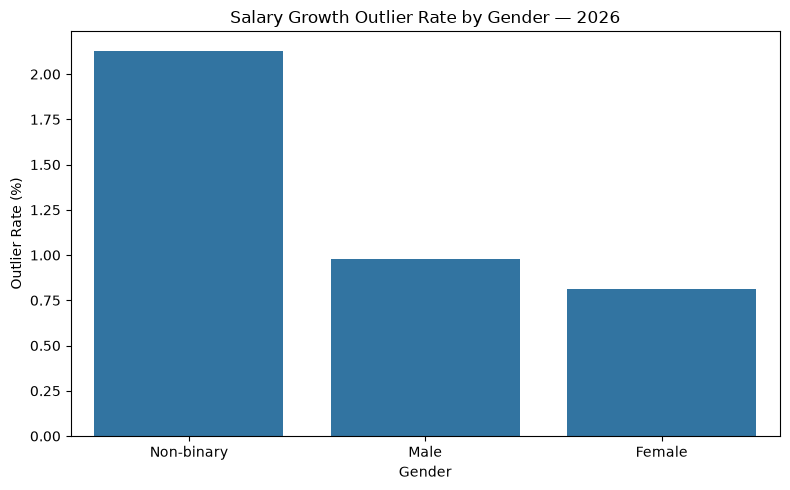

In [92]:

# Salary growth outliers by gender — 2026

gender_outliers_data = outlier_analysis.copy()

# Add gender only if it is missing
if "Gender" not in gender_outliers_data.columns:
    gender_outliers_data = gender_outliers_data.merge(
        employees[["Employee_ID", "Gender"]],
        on="Employee_ID",
        how="left",
        validate="many_to_one"
    )

# Calculate outlier counts and rates
gender_outliers = (
    gender_outliers_data
    .groupby("Gender")
    .agg(
        Employees_Analyzed=("Employee_ID", "count"),
        Outlier_Employees=("Is_Outlier", "sum")
    )
    .reset_index()
)

gender_outliers["Outlier_Rate"] = (
    gender_outliers["Outlier_Employees"] /
    gender_outliers["Employees_Analyzed"] * 100
).round(2)

gender_outliers = gender_outliers.sort_values(
    "Outlier_Rate", ascending=False
)

# Validation
print("Employees Analyzed:", len(gender_outliers_data))
print("Missing Gender Values:",
      gender_outliers_data["Gender"].isna().sum())
print("Total Outliers:",
      gender_outliers["Outlier_Employees"].sum())

display(gender_outliers)

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_outliers,
    x="Gender",
    y="Outlier_Rate"
)

plt.title("Salary Growth Outlier Rate by Gender — 2026")
plt.xlabel("Gender")
plt.ylabel("Outlier Rate (%)")

plt.tight_layout()
plt.show()


### Key Findings — Salary Growth Outliers by Gender (2026)

- **Non-binary employees** recorded the highest outlier rate at **2.13%** (2 out of 94 employees). However, the small group size makes this rate sensitive to individual cases.
- **Male employees** recorded an outlier rate of **0.98%** (44 employees), compared with **0.81%** (34 employees) among female employees.
- Male employees accounted for the highest absolute number of salary growth outliers.
- Differences in outlier rates are descriptive and do not independently establish compensation inequality. Further investigation should consider job level, department, performance, and the reasons for salary adjustments.

Employees Analyzed: 8766
Missing Performance Ratings: 0
Total Outliers: 80
Performance Ratings Analyzed: 5


,Performance_Rating,Performance_Category,Employees_Analyzed,Outlier_Employees,Outlier_Rate
0,1.00,Needs Improvement,363,2,0.55
1,2.00,Developing,995,5,0.50
2,3.00,Meets Expectations,4516,28,0.62
3,4.00,Exceeds Expectations,2355,28,1.19
4,5.00,Outstanding,537,17,3.17


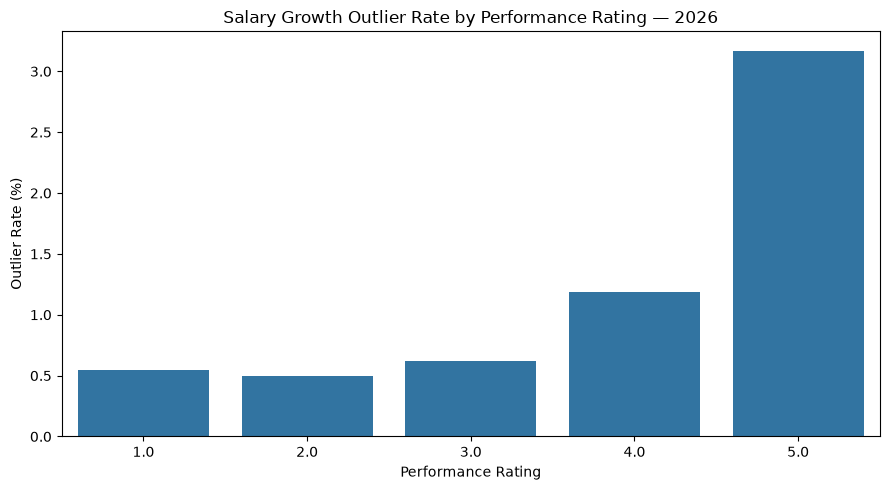

In [93]:

# Salary growth outliers by performance rating — 2026

performance_outliers_data = outlier_analysis.copy()

# Add 2026 performance ratings if not already present
if "Performance_Rating" not in performance_outliers_data.columns:
    performance_2026 = performance[
        performance["Review_Year"] == 2026
    ][[
        "Employee_ID",
        "Performance_Rating",
        "Performance_Category"
    ]].copy()

    performance_outliers_data = performance_outliers_data.merge(
        performance_2026,
        on="Employee_ID",
        how="left",
        validate="one_to_one"
    )

# Calculate outlier counts and rates
performance_outliers = (
    performance_outliers_data
    .groupby(
        ["Performance_Rating", "Performance_Category"]
    )
    .agg(
        Employees_Analyzed=("Employee_ID", "count"),
        Outlier_Employees=("Is_Outlier", "sum")
    )
    .reset_index()
)

performance_outliers["Outlier_Rate"] = (
    performance_outliers["Outlier_Employees"] /
    performance_outliers["Employees_Analyzed"] * 100
).round(2)

performance_outliers = performance_outliers.sort_values(
    "Performance_Rating"
)

# Validation
print("Employees Analyzed:", len(performance_outliers_data))
print("Missing Performance Ratings:",
      performance_outliers_data["Performance_Rating"].isna().sum())
print("Total Outliers:",
      performance_outliers["Outlier_Employees"].sum())
print("Performance Ratings Analyzed:",
      len(performance_outliers))

display(performance_outliers)

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=performance_outliers,
    x="Performance_Rating",
    y="Outlier_Rate"
)

plt.title("Salary Growth Outlier Rate by Performance Rating — 2026")
plt.xlabel("Performance Rating")
plt.ylabel("Outlier Rate (%)")

plt.tight_layout()
plt.show()


### Key Findings — Salary Growth Outliers by Performance Rating (2026)

- Employees rated **Outstanding (5)** recorded the highest salary growth outlier rate at **3.17%** (17 employees).
- Employees rated **Exceeds Expectations (4)** had an outlier rate of **1.19%** (28 employees).
- Employees rated **Meets Expectations (3)** also accounted for 28 outliers, but their outlier rate was lower at **0.62%**, reflecting the larger group size.
- Employees rated **Developing (2)** recorded the lowest outlier rate at **0.50%**.
- Higher performance ratings, particularly Outstanding, were associated with higher outlier rates. However, this analysis does not distinguish unusually high salary increases from unusually large decreases.

Employees Analyzed: 8766
Low Outliers: 10
High Outliers: 70
Total Outliers: 80

Outlier Counts:


Outlier_Type,Low Outlier,Normal,High Outlier
Performance_Rating,,,
1.00,2,361,0
2.00,3,990,2
3.00,5,4488,23
4.00,0,2327,28
5.00,0,520,17



Outlier Percentages:


Outlier_Type,Low Outlier,Normal,High Outlier
Performance_Rating,,,
1.00,0.55,99.45,0.00
2.00,0.30,99.50,0.20
3.00,0.11,99.38,0.51
4.00,0.00,98.81,1.19
5.00,0.00,96.83,3.17


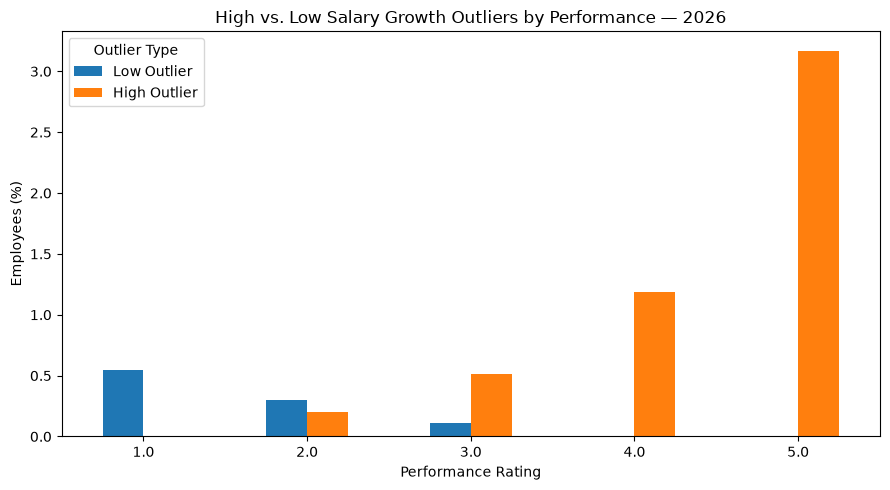

In [94]:

# High vs. low salary growth outliers by performance — 2026

performance_outlier_types = performance_outliers_data.copy()

# Classify outliers using the existing IQR bounds
performance_outlier_types["Outlier_Type"] = np.select(
    [
        performance_outlier_types["Salary_Growth_Pct"] < lower_bound,
        performance_outlier_types["Salary_Growth_Pct"] > upper_bound
    ],
    ["Low Outlier", "High Outlier"],
    default="Normal"
)

# Count outlier types by performance rating
outlier_type_counts = pd.crosstab(
    performance_outlier_types["Performance_Rating"],
    performance_outlier_types["Outlier_Type"]
)

# Ensure all categories are present
outlier_type_counts = outlier_type_counts.reindex(
    columns=["Low Outlier", "Normal", "High Outlier"],
    fill_value=0
)

# Calculate percentages within each performance group
outlier_type_pct = (
    outlier_type_counts.div(
        outlier_type_counts.sum(axis=1), axis=0
    ) * 100
).round(2)

# Validation
print("Employees Analyzed:", len(performance_outlier_types))
print("Low Outliers:",
      (performance_outlier_types["Outlier_Type"] == "Low Outlier").sum())
print("High Outliers:",
      (performance_outlier_types["Outlier_Type"] == "High Outlier").sum())
print("Total Outliers:",
      (performance_outlier_types["Outlier_Type"] != "Normal").sum())

print("\nOutlier Counts:")
display(outlier_type_counts)

print("\nOutlier Percentages:")
display(outlier_type_pct)

# Visualization: compare low and high outlier rates
outlier_type_pct[["Low Outlier", "High Outlier"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("High vs. Low Salary Growth Outliers by Performance — 2026")
plt.xlabel("Performance Rating")
plt.ylabel("Employees (%)")
plt.xticks(rotation=0)
plt.legend(title="Outlier Type")
plt.tight_layout()
plt.show()


### Key Findings — High vs. Low Salary Growth Outliers by Performance Rating (2026)

- Of the **80 salary growth outliers**, **70 were unusually high increases** and **10 were unusually large decreases**.
- Employees rated **Outstanding (5)** had the highest high-growth outlier rate at **3.17%** (17 employees).
- Employees rated **Exceeds Expectations (4)** recorded 28 high-growth outliers, representing **1.19%** of that performance group.
- No employees rated **4 or 5** experienced low-growth outliers.
- All **10 low-growth outliers** occurred among employees rated 1–3.
- The results suggest that unusually large salary increases are more common among higher-performing employees, consistent with performance-linked compensation practices. However, the analysis does not establish causation.

Employees Analyzed: 8766
Promoted Employees: 970
Low Outliers: 10
High Outliers: 70

Outlier Counts:


Outlier_Type,Low Outlier,Normal,High Outlier
Promotion_Status,,,
Not Promoted,10,7719,67
Promoted,0,967,3



Outlier Percentages:


Outlier_Type,Low Outlier,Normal,High Outlier
Promotion_Status,,,
Not Promoted,0.13,99.01,0.86
Promoted,0.00,99.69,0.31


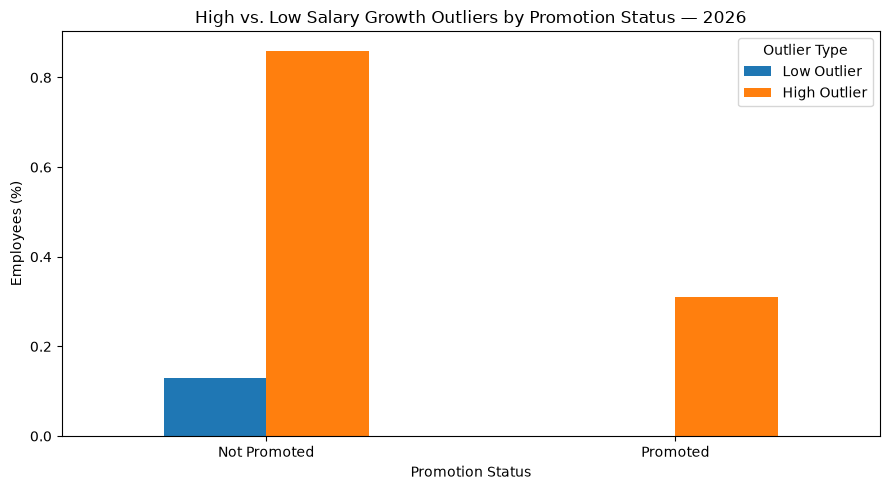

In [95]:

# Salary growth outliers by promotion status — 2026

promotion_outliers_data = outlier_analysis.copy()

# Identify employees promoted during 2026
promotions_2026 = promotions[
    pd.to_datetime(promotions["Promotion_Date"]).dt.year == 2026
]["Employee_ID"].drop_duplicates()

# Classify promotion status
promotion_outliers_data["Promotion_Status"] = np.where(
    promotion_outliers_data["Employee_ID"].isin(promotions_2026),
    "Promoted",
    "Not Promoted"
)

# Classify high and low outliers
promotion_outliers_data["Outlier_Type"] = np.select(
    [
        promotion_outliers_data["Salary_Growth_Pct"] < lower_bound,
        promotion_outliers_data["Salary_Growth_Pct"] > upper_bound
    ],
    ["Low Outlier", "High Outlier"],
    default="Normal"
)

# Count outlier types by promotion status
promotion_outlier_counts = pd.crosstab(
    promotion_outliers_data["Promotion_Status"],
    promotion_outliers_data["Outlier_Type"]
)

promotion_outlier_counts = promotion_outlier_counts.reindex(
    index=["Not Promoted", "Promoted"],
    columns=["Low Outlier", "Normal", "High Outlier"],
    fill_value=0
)

# Calculate percentages within each promotion group
promotion_outlier_pct = (
    promotion_outlier_counts.div(
        promotion_outlier_counts.sum(axis=1), axis=0
    ) * 100
).round(2)

# Validation
print("Employees Analyzed:", len(promotion_outliers_data))
print("Promoted Employees:",
      (promotion_outliers_data["Promotion_Status"] == "Promoted").sum())
print("Low Outliers:",
      (promotion_outliers_data["Outlier_Type"] == "Low Outlier").sum())
print("High Outliers:",
      (promotion_outliers_data["Outlier_Type"] == "High Outlier").sum())

print("\nOutlier Counts:")
display(promotion_outlier_counts)

print("\nOutlier Percentages:")
display(promotion_outlier_pct)

# Visualization
promotion_outlier_pct[["Low Outlier", "High Outlier"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("High vs. Low Salary Growth Outliers by Promotion Status — 2026")
plt.xlabel("Promotion Status")
plt.ylabel("Employees (%)")
plt.xticks(rotation=0)
plt.legend(title="Outlier Type")
plt.tight_layout()
plt.show()


### Key Findings — Salary Growth Outliers by Promotion Status (2026)

- Among **970 promoted employees**, only **3 (0.31%)** experienced unusually high year-over-year salary growth, and none experienced low-growth outliers.
- Among **7,796 non-promoted employees**, **67 (0.86%)** experienced unusually high salary growth, while **10 (0.13%)** experienced unusually large salary decreases.
- Non-promoted employees recorded a higher overall salary growth outlier rate (**0.99%**) than promoted employees (**0.31%**).
- These results indicate that unusually large annual salary adjustments were more common among non-promoted employees.
- Promotion-related salary increases and year-over-year base salary growth are different measures. The findings should not be interpreted as evidence that promotions reduce salary growth.

Employees Analyzed: 8766
Missing Departments: 0
Low Outliers: 10
High Outliers: 70
Departments Analyzed: 12

Outlier Counts:


Outlier_Type,Low Outlier,Normal,High Outlier
Department,,,
Marketing,3,580,8
Human Resources,0,526,5
Product,1,851,8
Finance,3,665,6
Leadership,0,1340,12
Sales,0,601,5
Legal & Compliance,0,606,5
Customer Success,0,540,4
Operations,0,553,4



Outlier Percentages:


Outlier_Type,Low Outlier,Normal,High Outlier
Department,,,
Marketing,0.51,98.14,1.35
Human Resources,0.00,99.06,0.94
Product,0.12,98.95,0.93
Finance,0.45,98.66,0.89
Leadership,0.00,99.11,0.89
Sales,0.00,99.17,0.83
Legal & Compliance,0.00,99.18,0.82
Customer Success,0.00,99.26,0.74
Operations,0.00,99.28,0.72


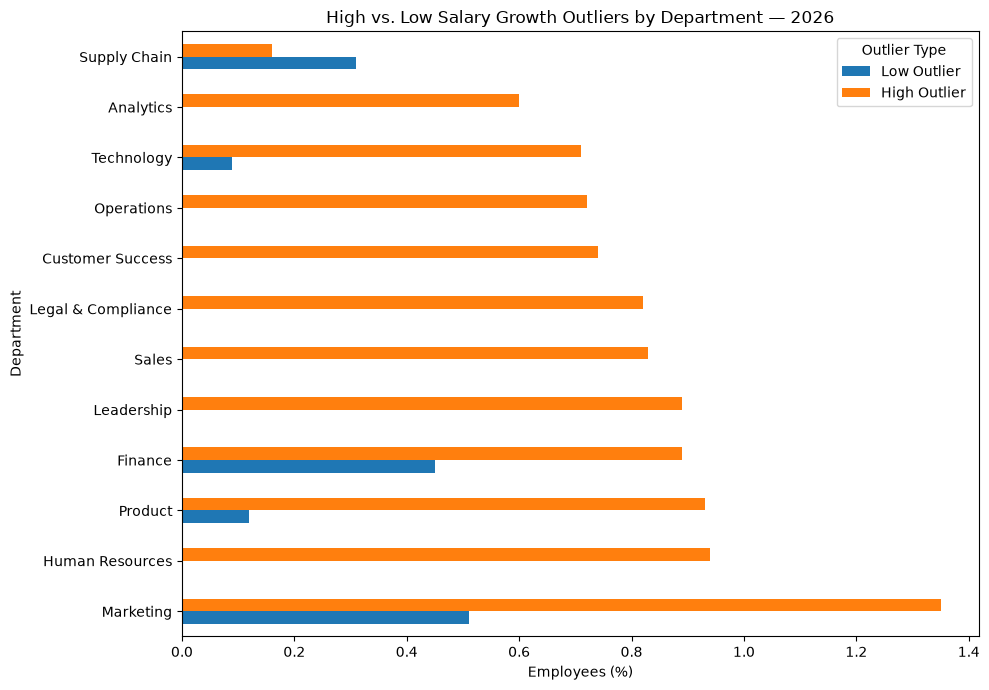

In [96]:

# High vs. low salary growth outliers by department — 2026

department_outlier_types = outlier_analysis.copy()

# Classify salary growth outliers
department_outlier_types["Outlier_Type"] = np.select(
    [
        department_outlier_types["Salary_Growth_Pct"] < lower_bound,
        department_outlier_types["Salary_Growth_Pct"] > upper_bound
    ],
    ["Low Outlier", "High Outlier"],
    default="Normal"
)

# Count outlier types by department
department_outlier_counts = pd.crosstab(
    department_outlier_types["Department"],
    department_outlier_types["Outlier_Type"]
)

department_outlier_counts = department_outlier_counts.reindex(
    columns=["Low Outlier", "Normal", "High Outlier"],
    fill_value=0
)

# Calculate percentages within each department
department_outlier_pct = (
    department_outlier_counts.div(
        department_outlier_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

# Sort by high outlier rate
department_outlier_pct = department_outlier_pct.sort_values(
    "High Outlier",
    ascending=False
)

department_outlier_counts = department_outlier_counts.loc[
    department_outlier_pct.index
]

# Validation
print("Employees Analyzed:", len(department_outlier_types))
print("Missing Departments:",
      department_outlier_types["Department"].isna().sum())
print("Low Outliers:",
      (department_outlier_types["Outlier_Type"] == "Low Outlier").sum())
print("High Outliers:",
      (department_outlier_types["Outlier_Type"] == "High Outlier").sum())
print("Departments Analyzed:", len(department_outlier_pct))

print("\nOutlier Counts:")
display(department_outlier_counts)

print("\nOutlier Percentages:")
display(department_outlier_pct)

# Visualization
department_outlier_pct[["Low Outlier", "High Outlier"]].plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("High vs. Low Salary Growth Outliers by Department — 2026")
plt.xlabel("Employees (%)")
plt.ylabel("Department")
plt.legend(title="Outlier Type")
plt.tight_layout()
plt.show()


### Key Findings — High vs. Low Salary Growth Outliers by Department (2026)

- **Marketing** recorded the highest high-growth outlier rate at **1.35%** (8 employees), followed by Human Resources at **0.94%**.
- **Leadership** had the highest absolute number of high-growth outliers (**12 employees**).
- **Marketing and Finance** each recorded 3 low-growth outliers, the highest counts among departments.
- **Supply Chain** recorded the lowest high-growth outlier rate at **0.16%**, with only 1 employee.
- High-growth outliers were more common than low-growth outliers across the organization, although their distribution varied by department.
- These findings can help prioritize reviews of unusual salary adjustments without assuming that outliers indicate compensation errors.

Employees Analyzed: 8766
Missing Job Levels: 0
Low Outliers: 10
High Outliers: 70
Job Levels Analyzed: 6

Outlier Counts:


Outlier_Type,Low Outlier,Normal,High Outlier
Job_Level,,,
1,0,386,7
2,3,1663,7
3,2,1839,17
4,5,2518,19
5,0,940,8
6,0,1340,12



Outlier Percentages:


Outlier_Type,Low Outlier,Normal,High Outlier
Job_Level,,,
1,0.00,98.22,1.78
2,0.18,99.40,0.42
3,0.11,98.98,0.91
4,0.20,99.06,0.75
5,0.00,99.16,0.84
6,0.00,99.11,0.89


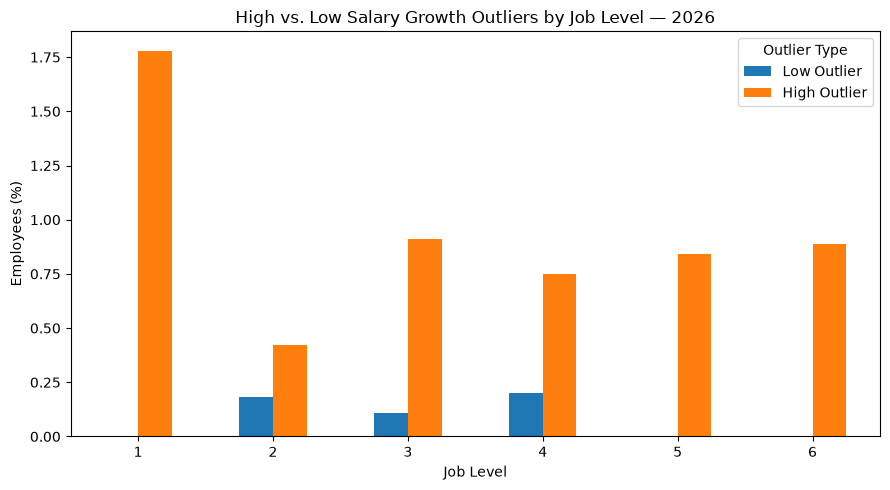

In [97]:

# High vs. low salary growth outliers by job level — 2026

level_outlier_types = level_outliers_data.copy()

# Classify salary growth outliers
level_outlier_types["Outlier_Type"] = np.select(
    [
        level_outlier_types["Salary_Growth_Pct"] < lower_bound,
        level_outlier_types["Salary_Growth_Pct"] > upper_bound
    ],
    ["Low Outlier", "High Outlier"],
    default="Normal"
)

# Count outlier types by job level
level_outlier_counts = pd.crosstab(
    level_outlier_types["Job_Level"],
    level_outlier_types["Outlier_Type"]
)

level_outlier_counts = level_outlier_counts.reindex(
    columns=["Low Outlier", "Normal", "High Outlier"],
    fill_value=0
)

# Calculate percentages within each job level
level_outlier_pct = (
    level_outlier_counts.div(
        level_outlier_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

# Validation
print("Employees Analyzed:", len(level_outlier_types))
print("Missing Job Levels:",
      level_outlier_types["Job_Level"].isna().sum())
print("Low Outliers:",
      (level_outlier_types["Outlier_Type"] == "Low Outlier").sum())
print("High Outliers:",
      (level_outlier_types["Outlier_Type"] == "High Outlier").sum())
print("Job Levels Analyzed:", len(level_outlier_pct))

print("\nOutlier Counts:")
display(level_outlier_counts)

print("\nOutlier Percentages:")
display(level_outlier_pct)

# Visualization
level_outlier_pct[["Low Outlier", "High Outlier"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("High vs. Low Salary Growth Outliers by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Employees (%)")
plt.xticks(rotation=0)
plt.legend(title="Outlier Type")

plt.tight_layout()
plt.show()


### Key Findings — High vs. Low Salary Growth Outliers by Job Level (2026)

- **Job Level 1** recorded the highest high-growth outlier rate (**1.78%**), with 7 employees.
- **Job Level 4** had the highest absolute number of high-growth outliers (**19 employees**) and low-growth outliers (**5 employees**).
- **Job Level 2** recorded the lowest high-growth outlier rate (**0.42%**).
- Low-growth outliers occurred only in Job Levels 2, 3, and 4.
- High-growth outliers were more common than low-growth outliers across all six job levels.
- Unusual salary growth patterns may warrant further review, particularly at Job Levels 1 and 4.

Employees Analyzed: 8766
Missing Locations: 0
Total Outliers: 80
Locations Analyzed: 6


,Location,Employees_Analyzed,Outlier_Employees,Outlier_Rate
2,Gurugram,1048,12,1.15
1,Chennai,1298,14,1.08
5,Pune,1343,13,0.97
0,Bengaluru,2465,22,0.89
4,Mumbai,1153,9,0.78
3,Hyderabad,1459,10,0.69


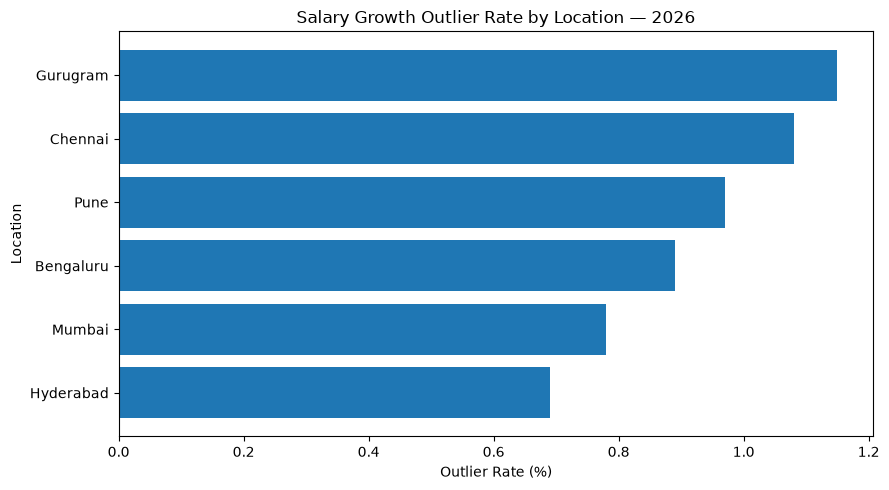

In [98]:

# Salary growth outlier rate by location — 2026

location_outlier_data = growth_2026.copy()

# Add location only if it is not already present
if "Location" not in location_outlier_data.columns:
    location_outlier_data = location_outlier_data.merge(
        employees[["Employee_ID", "Location"]],
        on="Employee_ID",
        how="left",
        validate="one_to_one"
    )

# Classify outliers using the previously calculated IQR bounds
location_outlier_data["Is_Outlier"] = (
    (location_outlier_data["Salary_Growth_Pct"] < lower_bound) |
    (location_outlier_data["Salary_Growth_Pct"] > upper_bound)
)

# Summarize by location
location_outlier_summary = (
    location_outlier_data.groupby("Location")
    .agg(
        Employees_Analyzed=("Employee_ID", "count"),
        Outlier_Employees=("Is_Outlier", "sum")
    )
    .reset_index()
)

location_outlier_summary["Outlier_Rate"] = (
    location_outlier_summary["Outlier_Employees"] /
    location_outlier_summary["Employees_Analyzed"] * 100
).round(2)

location_outlier_summary = location_outlier_summary.sort_values(
    "Outlier_Rate", ascending=False
)

# Validation
print("Employees Analyzed:", len(location_outlier_data))
print("Missing Locations:",
      location_outlier_data["Location"].isna().sum())
print("Total Outliers:",
      location_outlier_data["Is_Outlier"].sum())
print("Locations Analyzed:", len(location_outlier_summary))

display(location_outlier_summary)

# Visualization
plt.figure(figsize=(9, 5))

plt.barh(
    location_outlier_summary["Location"],
    location_outlier_summary["Outlier_Rate"]
)

plt.gca().invert_yaxis()

plt.title("Salary Growth Outlier Rate by Location — 2026")
plt.xlabel("Outlier Rate (%)")
plt.ylabel("Location")

plt.tight_layout()
plt.show()


### Key Findings — Salary Growth Outliers by Location (2026)

- **Gurugram** recorded the highest salary growth outlier rate (**1.15%**), followed by Chennai (**1.08%**).
- **Bengaluru** had the highest absolute number of outlier employees (**22**), but its outlier rate was **0.89%**.
- **Hyderabad** recorded the lowest outlier rate (**0.69%**).
- Outlier rates remained below **1.2%** across all six locations.
- These unusual salary growth cases may warrant further investigation but do not necessarily indicate errors or unfair compensation.

### Salary Band Compliance — Formula

**Salary Band Compliance Rate (%)**

$$
\frac{\text{Employees Within Salary Band}}{\text{Total Employees Analyzed}} \times 100
$$

**Below-Band Shortfall**

$$
\max(0, \text{Band Minimum} - \text{Base Salary})
$$

**Above-Band Excess**

$$
\max(0, \text{Base Salary} - \text{Band Maximum})
$$

In [100]:

# Step 98 — Final Salary Band Compliance Validation (2026)

# Select 2026 compensation records
band_validation = compensation.loc[
    compensation["Compensation_Year"] == 2026,
    ["Employee_ID", "Base_Salary"]
].copy()

# Add employee location and job
band_validation = band_validation.merge(
    employees[["Employee_ID", "Job_ID", "Location"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Add job level
band_validation = band_validation.merge(
    jobs[["Job_ID", "Job_Level"]],
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Match the appropriate salary band
band_validation = band_validation.merge(
    salary_bands[
        ["Job_ID", "Location", "Job_Level",
         "Band_Min", "Band_Max"]
    ],
    on=["Job_ID", "Location", "Job_Level"],
    how="left",
    validate="many_to_one"
)

# Classify salary band compliance
band_validation["Band_Status"] = np.select(
    [
        band_validation["Base_Salary"] < band_validation["Band_Min"],
        band_validation["Base_Salary"] > band_validation["Band_Max"]
    ],
    ["Below Band", "Above Band"],
    default="Within Band"
)

# Calculate shortfall and excess
band_validation["Below_Band_Shortfall"] = (
    band_validation["Band_Min"] - band_validation["Base_Salary"]
).clip(lower=0)

band_validation["Above_Band_Excess"] = (
    band_validation["Base_Salary"] - band_validation["Band_Max"]
).clip(lower=0)

# Summary
band_counts = band_validation["Band_Status"].value_counts()

band_summary = pd.DataFrame({
    "Employees": band_counts
})

band_summary["Percentage"] = (
    band_summary["Employees"] / len(band_validation) * 100
).round(2)

print("Employees Analyzed:", len(band_validation))
print("Missing Salary Bands:",
      band_validation["Band_Min"].isna().sum())
print("Duplicate Employees:",
      band_validation["Employee_ID"].duplicated().sum())

display(band_summary)

print("Total Below-Band Shortfall:",
      round(band_validation["Below_Band_Shortfall"].sum(), 2))

print("Total Above-Band Excess:",
      round(band_validation["Above_Band_Excess"].sum(), 2))


Employees Analyzed: 10000
Missing Salary Bands: 0
Duplicate Employees: 0


,Employees,Percentage
Band_Status,,
Within Band,9980,99.80
Below Band,19,0.19
Above Band,1,0.01


Total Below-Band Shortfall: 267993.93
Total Above-Band Excess: 162972.82


### Key Findings — Final Salary Band Compliance (2026)

- **99.80%** of employees (9,980 out of 10,000) have base salaries within their assigned salary bands.
- **19 employees (0.19%)** earn below their minimum salary bands, with a combined shortfall of **₹267,993.93**.
- **1 employee (0.01%)** earns above the maximum salary band, with an excess of **₹162,972.82**.
- All 10,000 employees have matching salary-band records, with no duplicate employee records.
- Overall salary-band compliance is high, although the 20 exceptions should be reviewed by HR and compensation teams.

In [101]:

# Step 99 — Final EDA Data Integrity Validation

validation_results = pd.DataFrame({
    "Validation_Check": [
        "Total Employees",
        "2026 Compensation Records",
        "2026 Performance Records",
        "2026 Salary Band Records",
        "2026 Salary Growth Comparisons",
        "Salary Growth Outliers",
        "Missing Salary Band Matches",
        "Duplicate 2026 Compensation Records"
    ],
    "Actual_Value": [
        len(employees),
        len(compensation[compensation["Compensation_Year"] == 2026]),
        len(performance[performance["Review_Year"] == 2026]),
        len(band_validation),
        len(growth_2026),
        int(location_outlier_data["Is_Outlier"].sum()),
        int(band_validation["Band_Min"].isna().sum()),
        int(
            compensation[
                compensation["Compensation_Year"] == 2026
            ]["Employee_ID"].duplicated().sum()
        )
    ],
    "Expected_Value": [
        10000,
        10000,
        10000,
        10000,
        8766,
        80,
        0,
        0
    ]
})

validation_results["Status"] = np.where(
    validation_results["Actual_Value"] ==
    validation_results["Expected_Value"],
    "PASS",
    "FAIL"
)

display(validation_results)

print(
    "Overall Validation:",
    "PASS" if (validation_results["Status"] == "PASS").all()
    else "FAIL"
)


,Validation_Check,Actual_Value,Expected_Value,Status
0,Total Employees,10000,10000,PASS
1,2026 Compensation Records,10000,10000,PASS
2,2026 Performance Records,10000,10000,PASS
3,2026 Salary Band Records,10000,10000,PASS
4,2026 Salary Growth Comparisons,8766,8766,PASS
5,Salary Growth Outliers,80,80,PASS
6,Missing Salary Band Matches,0,0,PASS
7,Duplicate 2026 Compensation Records,0,0,PASS


Overall Validation: PASS


## Final Business Insights & Recommendations

### 1. Compensation and Pay Equity

- Gender pay differences vary across departments, job levels, locations, and employee characteristics.
- Bengaluru recorded a **7.44%** male–female average base salary gap, while Gurugram recorded a **-10.59%** gap.
- Pay differences should be investigated using comparable job levels, experience, location, and performance rather than relying only on overall averages.

**Recommendation:** Conduct targeted compensation reviews within comparable employee groups to identify potentially unexplained pay differences.

### 2. Salary Band Compliance

- **99.80%** of employees received base salaries within their assigned salary bands.
- **19 employees** were below their minimum salary bands, representing a combined shortfall of **₹267,993.93**.
- **1 employee** was above the maximum salary band.

**Recommendation:** Prioritize reviewing below-band salaries and document approved exceptions to compensation policies.

### 3. Performance and Salary Growth

- Average base salary growth in 2026 was **3.86%** across **8,766 comparable employees**.
- Employees rated Outstanding recorded average salary growth of **8.52%**, compared with **-2.10%** for employees rated Needs Improvement.
- Higher performance ratings were generally associated with stronger salary growth.

**Recommendation:** Continue evaluating whether salary adjustments align consistently with performance outcomes.

### 4. Promotions and Compensation

- Among promoted employees included in the gender comparison, average promotion salary increases were **14.42% for females** and **14.61% for males**.
- The difference was **0.19 percentage points**.
- Promotion-related compensation differences varied across departments and job levels.

**Recommendation:** Review promotion increase guidelines to support consistent compensation decisions.

### 5. Salary Growth Distribution and Outliers

- **5,798 employees (66.14%)** received salary increases in 2026, while **2,968 (33.86%)** experienced decreases.
- **80 employees (0.91%)** were identified as salary growth outliers using the IQR method.
- Marketing recorded the highest departmental outlier rate (**1.86%**).
- Gurugram recorded the highest location-based outlier rate (**1.15%**).

**Recommendation:** Investigate unusual salary changes to distinguish legitimate compensation decisions from potential data or policy exceptions.

### 6. Final Conclusion

The analysis identified strong overall salary-band compliance, a positive relationship between performance ratings and salary growth, and compensation differences across employee groups.

The findings support three business priorities:

1. Strengthen pay equity monitoring across comparable employee groups.
2. Review salary-band exceptions and unusual salary adjustments.
3. Maintain transparent, consistent performance-based compensation and promotion practices.

All eight final data integrity checks passed, supporting the consistency of the completed analysis.